# Home Credit Default Assessment

This assessment develops a machine learning system to predict whether a Home Credit applicant is likely to default on a loan. It brings together information from several related datasets, prepares and selects useful features, trains different machine learning and neural network models, and compares their performance. The assessment also examines calibration, fairness, decision thresholds and model explanations before selecting the most suitable model for the final credit default prediction system.


## Assessment map

| Assessment area | What this notebook demonstrates |
|---|---|
| **A1** | EDA, missingness, domain anomalies, feature engineering and relational joins |
| **A2** | Three feature-selection signals, reduced feature set and leakage-safe preprocessing |
| **A3** | Classical ML: baseline, model-family comparison and tuning |
| **A4** | Ensemble ML: Random Forest, XGBoost, LightGBM and Optuna tuning |
| **A5** | MLP implemented in both Keras and PyTorch, tuning and 5-fold comparison |
| **A6** | Leaderboard, fold stability, Friedman/Wilcoxon, calibration, fairness, SMOTENC and cost threshold |
| **A7** | SHAP comparison across model families, global explanation and one-applicant explanation |
| **A8** | Final selection, test confirmation, latency, model card, persistence and deployment conditions |

> **How to read the notebook:** after each important code cell, the notebook explains what happened and states the decision that follows from the evidence.

---
## Setup — Environment, data location and reproducibility

Install the required packages, find the data files, import the libraries and set a fixed random seed so the workflow can be repeated more consistently.

### Setup Step 1 — Install the required libraries

In [ ]:
# Setup Step 1 — Install the required libraries
!pip install -q xgboost lightgbm shap optuna imbalanced-learn
print('Installation complete.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.4/267.4 kB 25.4 MB/s eta 0:00:00
Installation complete.


**Output explanation.** The required packages were installed successfully. This means the notebook has the main libraries needed for boosting, SHAP explanations, tuning and class-imbalance testing.

### Setup Step 2 — Mount Google Drive and locate the Home Credit files

In [ ]:
# Setup Step 2 — Mount Google Drive and locate the Home Credit files
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')


DATA_FOLDER = Path('/content/drive/MyDrive/Assignment_files')


print("Files found in Assignment_files:")

for file in DATA_FOLDER.iterdir():
    print("-", file.name)


Mounted at /content/drive
Files found in Assignment_files:
- HomeCredit_columns_description.csv
- POS_CASH_balance.parquet
- credit_card_balance.parquet
- installments_payments.parquet
- previous_application.parquet
- application_train.parquet
- application_test.parquet
- bureau_balance.parquet
- .ipynb_checkpoints
- bureau.parquet


**Output explanation.** Google Drive was mounted and the assignment folder was found. The listed files confirm that the main application data and the supporting Home Credit tables are available for the later steps.

### Setup Step 3 — Import the modelling, evaluation and deep-learning libraries

In [ ]:
# Setup Step 3 — Import the modelling, evaluation and deep-learning libraries

import numpy as np                  # arrays and maths
import pandas as pd                 # tables (DataFrames) -- how we'll hold the dataset
import matplotlib.pyplot as plt     # charts
import seaborn as sns               # nicer-looking charts, built on matplotlib
import scipy.stats as stats         # statistical tests, used later
import time, warnings               # time.time() to measure how long processing takes
from itertools import combinations  # generates all pairs of models, used

warnings.filterwarnings('ignore')

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer

from sklearn.model_selection import (StratifiedKFold, GridSearchCV,
                                     cross_val_score, cross_validate,
                                     cross_val_predict, train_test_split)
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             brier_score_loss, confusion_matrix,
                             precision_recall_curve, recall_score,
                             precision_score, make_scorer)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.inspection import permutation_importance

import shap
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import torch
import torch.nn as nn

print(f"TensorFlow GPU available: {tf.config.list_physical_devices('GPU') != []}")
print(f"PyTorch GPU available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print(f"PyTorch Device Name: {torch.cuda.get_device_name(0)}")


TensorFlow GPU available: True
PyTorch GPU available: True
PyTorch Device Name: Tesla T4


**Output explanation.** Both TensorFlow and PyTorch can use the GPU, and the available device is a Tesla T4. This should reduce the training time for the neural-network section.

### Setup Step 4 — Fix reproducibility and shared plotting settings

In [ ]:
# Setup Step 4 — Fix reproducibility and shared plotting settings
# Reproducibility

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

if 'tf_available' in globals() and tf_available:
    tf.random.set_seed(RANDOM_STATE)

if 'torch_available' in globals() and torch_available:
    torch.manual_seed(RANDOM_STATE)


# Plotting defaults (module standard)

BLUE, ORANGE, GREEN, RED = '#4878D0', '#EE854A', '#6ACC65', '#D65F5F'


plt.rcParams.update({
    'figure.dpi': 120,
    'figure.figsize': (10, 5),
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
sns.set_theme(style='whitegrid', palette='colorblind')


# Configuration

N_TRIALS = 15          # bounded Optuna trials per ensemble family (A4)
N_BINS_ECE = 10        # bins for Expected Calibration Error (A6)

# Device was selected in the core-import cell.
if 'DEVICE' not in globals():
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('Imports complete.')
print(f'  RANDOM_STATE = {RANDOM_STATE}')
print(f'  Optuna trials per ensemble: {N_TRIALS}')
print(f'  PyTorch device: {DEVICE}')


Imports complete.
  RANDOM_STATE = 42
  Optuna trials per ensemble: 15
  PyTorch device: cuda


**Output explanation.** The notebook uses a fixed random seed of **42**, **15 Optuna trials** for each ensemble search, and the GPU for PyTorch. Keeping these settings fixed makes repeated runs more consistent.

### Setup Step 5 — Define the two small reusable helpers

In [ ]:
# Setup Step 5 — Define the two small reusable helpers

# Helper 1: Expected Calibration Error

def compute_ece(y_true, y_prob, n_bins=N_BINS_ECE):
    """
    Calculate Expected Calibration Error (ECE).

    ECE compares predicted default probabilities with actual default rates.
    Lower ECE means better calibrated probabilities.
    """

    y_true = np.asarray(y_true).astype(float)
    y_prob = np.asarray(y_prob).astype(float)

    edges = np.linspace(0.0, 1.0, n_bins + 1)

    n, ece = len(y_true), 0.0

    for lo, hi in zip(edges[:-1], edges[1:]):

        in_bin = (
            ((y_prob >= lo) & (y_prob < hi))
            if hi < 1.0
            else ((y_prob >= lo) & (y_prob <= hi))
        )

        if in_bin.sum() == 0:
            continue

        conf = y_prob[in_bin].mean()
        acc = y_true[in_bin].mean()

        ece += (in_bin.sum() / n) * abs(acc - conf)

    return ece

# Helper 2: Map encoded features back to original columns

def ohe_name_to_source(ct, cat_cols):
    """
    Map transformed feature names back to their original Home Credit columns.

    Example:
    NAME_EDUCATION_TYPE_Higher education
    → NAME_EDUCATION_TYPE
    """

    raw_names = list(ct.get_feature_names_out())

    clean_names, mapping = [], {}

    for raw in raw_names:

        block, name = raw.split('__', 1)
        clean_names.append(name)

        if block.startswith('num'):
            mapping[name] = name

        else:
            candidates = [
                c for c in cat_cols
                if name == c or name.startswith(c + '_')
            ]

            mapping[name] = (
                max(candidates, key=len)
                if candidates
                else name
            )

    return clean_names, mapping


print('Utilities defined: compute_ece, ohe_name_to_source')


Utilities defined: compute_ece, ohe_name_to_source


**Output explanation.** Two helper functions were created successfully. One measures calibration error, while the other links one-hot encoded feature names back to their original source columns.


# A1 — Data Exploration, Preprocessing and Feature Engineering

A1 checks the data, creates a stratified development/test split, examines class imbalance, missing values and unusual values, then creates applicant-level and joined features. Model-development decisions use the development data only.

### A1 Step 1 — Load and verify the Home Credit data

In [ ]:
import pandas as pd

# A1.0: Load the Home Credit datasets

try:
    application_train = pd.read_parquet(
        DATA_FOLDER / 'application_train.parquet'
    )
    application_test = pd.read_parquet(
        DATA_FOLDER / 'application_test.parquet'
    )
    previous_application = pd.read_parquet(
        DATA_FOLDER / 'previous_application.parquet'
    )
    installments_payments = pd.read_parquet(
        DATA_FOLDER / 'installments_payments.parquet'
    )
    POS_CASH_balance = pd.read_parquet(
        DATA_FOLDER / 'POS_CASH_balance.parquet'
    )
    credit_card_balance = pd.read_parquet(
        DATA_FOLDER / 'credit_card_balance.parquet'
    )
    bureau = pd.read_parquet(
        DATA_FOLDER / 'bureau.parquet'
    )
    bureau_balance = pd.read_parquet(
        DATA_FOLDER / 'bureau_balance.parquet'
    )
    columns_description = pd.read_csv(
        DATA_FOLDER / 'HomeCredit_columns_description.csv',
        encoding='cp1252'
    )
    print('Loaded all Home Credit datasets from the assignment folder.')
except Exception as e:
    print(f'Dataset loading failed ({type(e).__name__}).')
    print('Check that all required Home Credit files are saved inside')
    print('the Assignment_files folder and set DATA_FOLDER correctly.')
    raise

application_train.columns = [str(c).strip() for c in application_train.columns]
target_aliases = ['TARGET', 'target']
for alias in target_aliases:
    if alias in application_train.columns:
        application_train = application_train.rename(columns={alias: 'TARGET'})
        break

if 'sk_id_curr' in application_train.columns and 'SK_ID_CURR' not in application_train.columns:
    application_train = application_train.rename(columns={'sk_id_curr': 'SK_ID_CURR'})

print(f'\nShape: {application_train.shape}')
print(f'Target column: TARGET')
print(f'Default rate: {application_train["TARGET"].mean() * 100:.2f}%')
print()
print('First rows:')
print(application_train.head(3).to_string())
print()
print('dtypes:')
print(application_train.dtypes.value_counts().to_string())
print()
print('Missing cells across the whole frame:',
      int(application_train.isnull().sum().sum()))


Loaded all Home Credit datasets from the assignment folder.

Shape: (307511, 122)
Target column: TARGET
Default rate: 8.07%

First rows:
   SK_ID_CURR  TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  AMT_GOODS_PRICE NAME_TYPE_SUITE NAME_INCOME_TYPE            NAME_EDUCATION_TYPE    NAME_FAMILY_STATUS  NAME_HOUSING_TYPE  REGION_POPULATION_RELATIVE  DAYS_BIRTH  DAYS_EMPLOYED  DAYS_REGISTRATION  DAYS_ID_PUBLISH  OWN_CAR_AGE  FLAG_MOBIL  FLAG_EMP_PHONE  FLAG_WORK_PHONE  FLAG_CONT_MOBILE  FLAG_PHONE  FLAG_EMAIL OCCUPATION_TYPE  CNT_FAM_MEMBERS  REGION_RATING_CLIENT  REGION_RATING_CLIENT_W_CITY WEEKDAY_APPR_PROCESS_START  HOUR_APPR_PROCESS_START  REG_REGION_NOT_LIVE_REGION  REG_REGION_NOT_WORK_REGION  LIVE_REGION_NOT_WORK_REGION  REG_CITY_NOT_LIVE_CITY  REG_CITY_NOT_WORK_CITY  LIVE_CITY_NOT_WORK_CITY       ORGANIZATION_TYPE  EXT_SOURCE_1  EXT_SOURCE_2  EXT_SOURCE_3  APARTMENTS_AVG  BASEMENTAREA_AVG  YEARS_BEGINEXPLU

**Output explanation.** The main Home Credit table contains **307,511 applicants and 122 columns**. The target default rate is **8.07%**, which shows that defaults are much less common than non-defaults.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Output explanation.** Google Drive was already mounted, so no second mount was needed. The notebook can continue using the same Drive connection and data folder.

### A1 Step 2 — Create a stratified development/test split before EDA

In [ ]:
df_tr, df_te = train_test_split(
    application_train, test_size=0.20, stratify=application_train['TARGET'], random_state=RANDOM_STATE)

print('=== SPLIT (stratified on the target) ===')
print(f'{"Split":<12} {"Rows":>8} {"Default rate":>14}')
print('-' * 36)
print(f'{"Training":<12} {len(df_tr):>8,} {df_tr["TARGET"].mean() * 100:>13.2f}%')
print(f'{"Test":<12} {len(df_te):>8,} {df_te["TARGET"].mean() * 100:>13.2f}%')
print()
print('Stratification check: the two rates above should agree to ~0.1pp.')
print('From here until A6, every plot and decision uses df_tr only.')

del application_train    # remove the full frame so it cannot be used by accident


=== SPLIT (stratified on the target) ===
Split            Rows   Default rate
------------------------------------
Training      246,008          8.07%
Test           61,503          8.07%

Stratification check: the two rates above should agree to ~0.1pp.
From here until A6, every plot and decision uses df_tr only.


**Output explanation.** The data was split into **246,008 development rows** and **61,503 held-out test rows**. Both parts keep the same **8.07% default rate**, so the split preserves the class balance. The test set is kept aside until final evaluation.

### A1 Step 3 — Measure the class imbalance and establish no-skill baselines

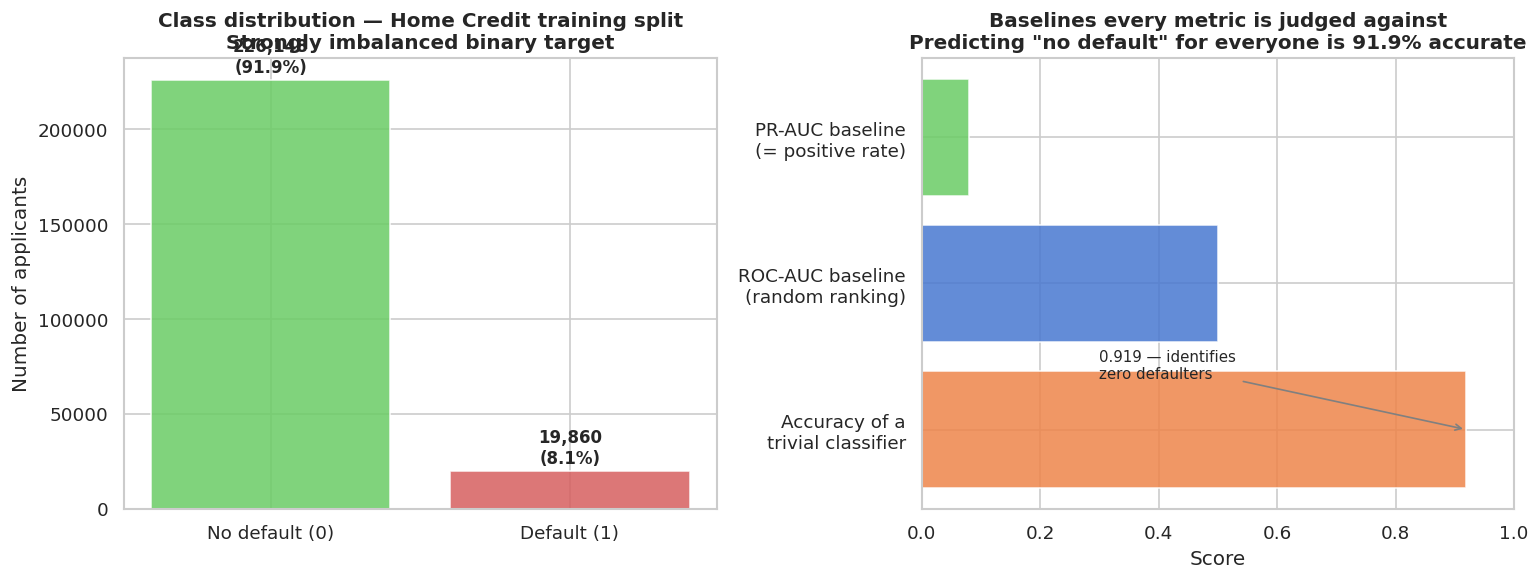

=== CLASS BALANCE (training split) ===
  No default: 226,148  (91.93%)
  Default:     19,860  (8.07%)
  Imbalance ratio: 11.4 : 1

  Accuracy baseline (always 0): 0.9193  -> accuracy is uninformative
  ROC-AUC baseline:             0.5000  -> primary metric
  PR-AUC baseline (pos rate):   0.0807  -> secondary metric


In [ ]:
# A1 Step 3 — Measure the class imbalance and establish no-skill baselines
tr = df_tr
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

counts = tr['TARGET'].value_counts().sort_index()
bars = axes[0].bar(['No default (0)', 'Default (1)'], counts.values,
                   color=[GREEN, RED], alpha=0.85, edgecolor='white')
axes[0].set_title('Class distribution — Home Credit training split\n'
                  'Strongly imbalanced binary target',
                  fontweight='bold')
axes[0].set_ylabel('Number of applicants')
for bar, cnt in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + len(tr) * 0.008,
                 f'{cnt:,}\n({cnt / len(tr) * 100:.1f}%)', ha='center', va='bottom',
                 fontsize=10, fontweight='bold')

acc_trivial = (tr['TARGET'] == 0).mean()
pr_baseline = tr['TARGET'].mean()
axes[1].barh(['Accuracy of a\ntrivial classifier', 'ROC-AUC baseline\n(random ranking)',
              'PR-AUC baseline\n(= positive rate)'],
             [acc_trivial, 0.5, pr_baseline], color=[ORANGE, BLUE, GREEN], alpha=0.85)
axes[1].set_xlim(0, 1); axes[1].set_xlabel('Score')
axes[1].set_title('Baselines every metric is judged against\n'
                  f'Predicting "no default" for everyone is {acc_trivial * 100:.1f}% accurate',
                  fontweight='bold')
axes[1].annotate(f'{acc_trivial:.3f} — identifies\nzero defaulters',
                 xy=(acc_trivial, 0), xytext=(0.30, 0.35),
                 arrowprops=dict(arrowstyle='->', color='grey'), fontsize=9)
plt.tight_layout()
plt.savefig('/content/a1_imbalance.png', dpi=300, bbox_inches='tight')
plt.show()

print('=== CLASS BALANCE (training split) ===')
print(f'  No default: {(tr["TARGET"] == 0).sum():>7,}  ({(1 - pr_baseline) * 100:.2f}%)')
print(f'  Default:    {(tr["TARGET"] == 1).sum():>7,}  ({pr_baseline * 100:.2f}%)')
print(f'  Imbalance ratio: {(1 - pr_baseline) / pr_baseline:.1f} : 1')
print()
print(f'  Accuracy baseline (always 0): {acc_trivial:.4f}  -> accuracy is uninformative')
print(f'  ROC-AUC baseline:             0.5000  -> primary metric')
print(f'  PR-AUC baseline (pos rate):   {pr_baseline:.4f}  -> secondary metric')


**Output explanation.** The training data contains **226,148 non-defaults** and **19,860 defaults**, giving an imbalance of about **11.4 to 1**. Accuracy alone would be misleading because predicting every case as non-default would already give **91.93% accuracy**. ROC-AUC and PR-AUC are therefore more useful measures.

### A1 Step 4 — Inspect explicit missing values

In [ ]:
# A1 Step 4 — Inspect explicit missing values

miss = tr.isnull().sum()

print('=== EXPLICIT MISSINGNESS ===')
print(f'  Columns with any NaN: {(miss > 0).sum()} of {tr.shape[1]}')
print(f'  Total missing cells:  {int(miss.sum())}')
print()

if miss.sum() == 0:

    print('  No explicit missing values. This is the "check for disguised missingness"')
    print('  case. Two places to look, both examined in A1.4:')

    print('    1. Categorical columns containing special values such as XNA')
    print('       (CODE_GENDER, ORGANIZATION_TYPE) -- these may represent')
    print('       unknown or structurally not-applicable categories.')

    print('    2. Numeric columns containing values outside the plausible domain')
    print('       (DAYS_EMPLOYED = 365243) -- this is a sentinel value rather')
    print('       than a genuine employment duration.')

else:

    for c in miss[miss > 0].index:

        print(
            f'  {c:<30} '
            f'{miss[c]:>7,} '
            f'({miss[c] / len(tr) * 100:.1f}%)'
        )


=== EXPLICIT MISSINGNESS ===
  Columns with any NaN: 67 of 122
  Total missing cells:  7318445

  AMT_ANNUITY                         10 (0.0%)
  AMT_GOODS_PRICE                    221 (0.1%)
  NAME_TYPE_SUITE                  1,029 (0.4%)
  OWN_CAR_AGE                    162,418 (66.0%)
  OCCUPATION_TYPE                 76,940 (31.3%)
  CNT_FAM_MEMBERS                      2 (0.0%)
  EXT_SOURCE_1                   138,595 (56.3%)
  EXT_SOURCE_2                       531 (0.2%)
  EXT_SOURCE_3                    48,805 (19.8%)
  APARTMENTS_AVG                 124,732 (50.7%)
  BASEMENTAREA_AVG               143,829 (58.5%)
  YEARS_BEGINEXPLUATATION_AVG    119,949 (48.8%)
  YEARS_BUILD_AVG                163,543 (66.5%)
  COMMONAREA_AVG                 171,811 (69.8%)
  ELEVATORS_AVG                  131,017 (53.3%)
  ENTRANCES_AVG                  123,775 (50.3%)
  FLOORSMAX_AVG                  122,297 (49.7%)
  FLOORSMIN_AVG                  166,921 (67.9%)
  LANDAREA_AVG             

**Output explanation.** Missing values are common: **67 of 122 columns** contain at least one missing value, with more than **7.3 million missing cells** in the development data. Some variables have very high missing rates, so removing incomplete rows or columns would discard too much information. Missing values are handled later inside the modelling pipeline.

#### A1 Step 4b — Check the missing-value pattern

Six features are checked to see whether missing values change across a related observed variable. These are reasonable working explanations based on the available data, not proof of the true reason a value is missing.

In [ ]:
# A1 Step 4b: define six working missingness judgements.

missingness_plan = pd.DataFrame([
    {
        'Feature': 'OCCUPATION_TYPE',
        'Working_classification': 'MAR candidate',
        'Observed_proxy': 'NAME_INCOME_TYPE',
        'Domain_reason': (
            'Occupation recording plausibly depends on the observed employment / '
            'income situation of the applicant.'
        )
    },
    {
        'Feature': 'AMT_GOODS_PRICE',
        'Working_classification': 'MAR candidate',
        'Observed_proxy': 'NAME_CONTRACT_TYPE',
        'Domain_reason': (
            'Goods price is tied to the observed contract / purchase context, so '
            'availability can depend on information already recorded.'
        )
    },
    {
        'Feature': 'CNT_FAM_MEMBERS',
        'Working_classification': 'MAR candidate',
        'Observed_proxy': 'NAME_FAMILY_STATUS',
        'Domain_reason': (
            'Household-size recording can depend on the observed family-status '
            'information collected on the application.'
        )
    },
    {
        'Feature': 'OWN_CAR_AGE',
        'Working_classification': 'MAR (structural)',
        'Observed_proxy': 'FLAG_OWN_CAR',
        'Domain_reason': (
            'Car age is not applicable when the applicant reports no car; the '
            'missingness mechanism is therefore largely explained by an observed field.'
        )
    },
    {
        'Feature': 'EXT_SOURCE_1',
        'Working_classification': 'MNAR-risk',
        'Observed_proxy': 'NAME_INCOME_TYPE',
        'Domain_reason': (
            'Availability of an external score may depend on an external-data '
            'footprint that is only partly represented in the application table.'
        )
    },
    {
        'Feature': 'EXT_SOURCE_3',
        'Working_classification': 'MNAR-risk',
        'Observed_proxy': 'NAME_EDUCATION_TYPE',
        'Domain_reason': (
            'External-score availability may depend on information held by the '
            'external provider, so observed application variables may not fully '
            'explain why the score is absent.'
        )
    },
])

print('A1 Step 4b done: working missingness hypotheses defined.')
display(missingness_plan)


A1 Step 4b done: working missingness hypotheses defined.


,Feature,Working_classification,Observed_proxy,Domain_reason
0,OCCUPATION_TYPE,MAR candidate,NAME_INCOME_TYPE,Occupation recording plausibly depends on the ...
1,AMT_GOODS_PRICE,MAR candidate,NAME_CONTRACT_TYPE,Goods price is tied to the observed contract /...
2,CNT_FAM_MEMBERS,MAR candidate,NAME_FAMILY_STATUS,Household-size recording can depend on the obs...
3,OWN_CAR_AGE,MAR (structural),FLAG_OWN_CAR,Car age is not applicable when the applicant r...
4,EXT_SOURCE_1,MNAR-risk,NAME_INCOME_TYPE,Availability of an external score may depend o...
5,EXT_SOURCE_3,MNAR-risk,NAME_EDUCATION_TYPE,External-score availability may depend on info...


**Output explanation.** Six features were selected for a closer missing-data check. The table gives a working reason for why each feature may be missing and links it to an observed variable that may help explain the pattern.

In [ ]:
# A1 Step 4c: check the missingness pattern on training data only.

missingness_rows = []

for _, plan in missingness_plan.iterrows():

    feature = plan['Feature']
    proxy = plan['Observed_proxy']

    if feature not in tr.columns:
        raise KeyError(f'{feature} is missing from the training table.')

    if proxy not in tr.columns:
        raise KeyError(f'{proxy} is missing from the training table.')

    is_missing = tr[feature].isna()

    proxy_rates = (
        pd.DataFrame({
            'proxy': tr[proxy],
            'missing': is_missing.astype(int)
        })
        .groupby('proxy', dropna=False)['missing']
        .mean()
    )

    proxy_range = (
        proxy_rates.max() - proxy_rates.min()
        if len(proxy_rates) > 1 else 0.0
    )

    missing_default = (
        tr.loc[is_missing, 'TARGET'].mean()
        if is_missing.any() else np.nan
    )

    observed_default = (
        tr.loc[~is_missing, 'TARGET'].mean()
        if (~is_missing).any() else np.nan
    )

    missingness_rows.append({
        'Feature': feature,
        'Working_classification': plan['Working_classification'],
        'Observed_proxy': proxy,
        'Missing_%': is_missing.mean() * 100,
        'Proxy_missingness_range_pp': proxy_range * 100,
        'Default_rate_if_missing': missing_default,
        'Default_rate_if_observed': observed_default,
        'Default_rate_gap': missing_default - observed_default,
        'Domain_reason': plan['Domain_reason'],
    })


missingness_evidence = pd.DataFrame(missingness_rows)

print('=== A1 MISSINGNESS EVIDENCE — TRAINING DATA ONLY ===')
display(
    missingness_evidence[
        [
            'Feature',
            'Working_classification',
            'Observed_proxy',
            'Missing_%',
            'Proxy_missingness_range_pp',
            'Default_rate_if_missing',
            'Default_rate_if_observed',
            'Default_rate_gap'
        ]
    ].round(4)
)

print()
print('Interpretation rule:')
print('  MAR candidate  -> observed variables explain at least part of the missingness pattern.')
print('  MNAR-risk      -> an unobserved data-availability process may still matter.')
print('These are working hypotheses, not formal proof of the mechanism.')


=== A1 MISSINGNESS EVIDENCE — TRAINING DATA ONLY ===


,Feature,Working_classification,Observed_proxy,Missing_%,Proxy_missingness_range_pp,Default_rate_if_missing,Default_rate_if_observed,Default_rate_gap
0,OCCUPATION_TYPE,MAR candidate,NAME_INCOME_TYPE,31.2754,84.3187,0.0649,0.0879,-0.0230
1,AMT_GOODS_PRICE,MAR candidate,NAME_CONTRACT_TYPE,0.0898,0.9425,0.0769,0.0807,-0.0038
2,CNT_FAM_MEMBERS,MAR candidate,NAME_FAMILY_STATUS,0.0008,100.0000,0.0000,0.0807,-0.0807
3,OWN_CAR_AGE,MAR (structural),FLAG_OWN_CAR,66.0214,99.9940,0.0848,0.0727,0.0121
4,EXT_SOURCE_1,MNAR-risk,NAME_INCOME_TYPE,56.3376,76.7753,0.0852,0.0749,0.0104
5,EXT_SOURCE_3,MNAR-risk,NAME_EDUCATION_TYPE,19.8388,8.7174,0.0928,0.0777,0.0150



Interpretation rule:
  MAR candidate  -> observed variables explain at least part of the missingness pattern.
  MNAR-risk      -> an unobserved data-availability process may still matter.
These are evidence-based working hypotheses, not formal proofs of the mechanism.


**Output explanation.** The missing rates differ across the six features and, in several cases, also differ across observed groups. This supports treating some missingness as linked to known applicant information, while the external-score variables may still involve information that is not observed. These are working explanations, not proof of the true cause of missingness.

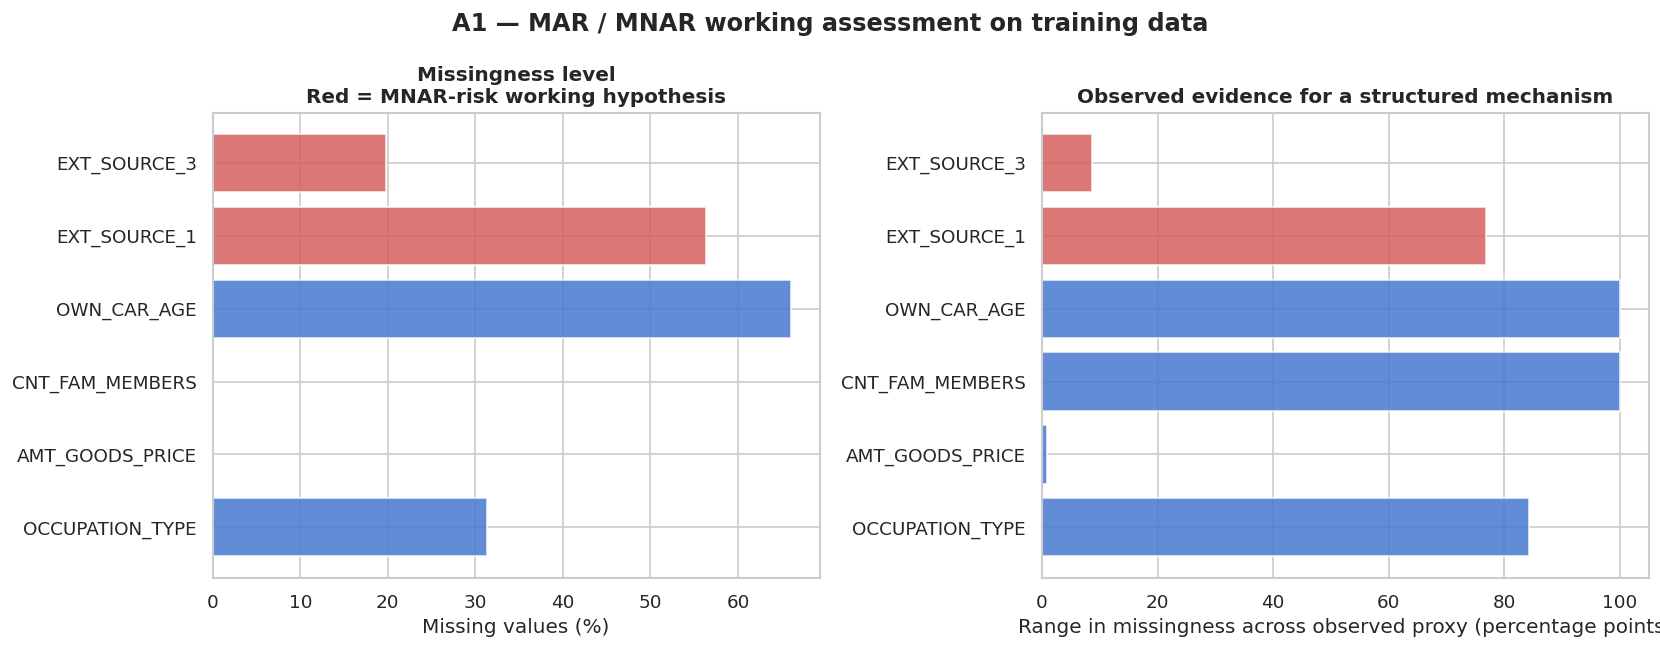

In [ ]:
# A1 Step 4d: plot missingness level and proxy variation.

plot_missing = missingness_evidence.copy()

bar_colours = [
    RED if 'MNAR' in x else BLUE
    for x in plot_missing['Working_classification']
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].barh(
    plot_missing['Feature'],
    plot_missing['Missing_%'],
    color=bar_colours,
    alpha=0.85
)
axes[0].set_xlabel('Missing values (%)')
axes[0].set_title(
    'Missingness level\nRed = MNAR-risk working hypothesis',
    fontweight='bold'
)

axes[1].barh(
    plot_missing['Feature'],
    plot_missing['Proxy_missingness_range_pp'],
    color=bar_colours,
    alpha=0.85
)
axes[1].set_xlabel('Range in missingness across observed proxy (percentage points)')
axes[1].set_title(
    'Observed evidence for a structured mechanism',
    fontweight='bold'
)

plt.suptitle(
    'A1 — MAR / MNAR working assessment on training data',
    fontweight='bold'
)
plt.tight_layout()
plt.savefig('/content/a1_missingness_mar_mnar.png', dpi=300, bbox_inches='tight')
plt.show()


**Output explanation.** The charts show how missingness changes across the selected observed groups and how default rates differ when values are missing or present. The patterns support keeping missing-value handling inside the pipeline rather than making a simple assumption that all missing values mean the same thing.

**67 of 122 columns** contain missing values, with more than **7.3 million missing cells** in the development data. Missingness is therefore handled inside the pipeline rather than by dropping large numbers of applicants.

### A1 Step 5 — Detect domain anomalies, not just NaNs

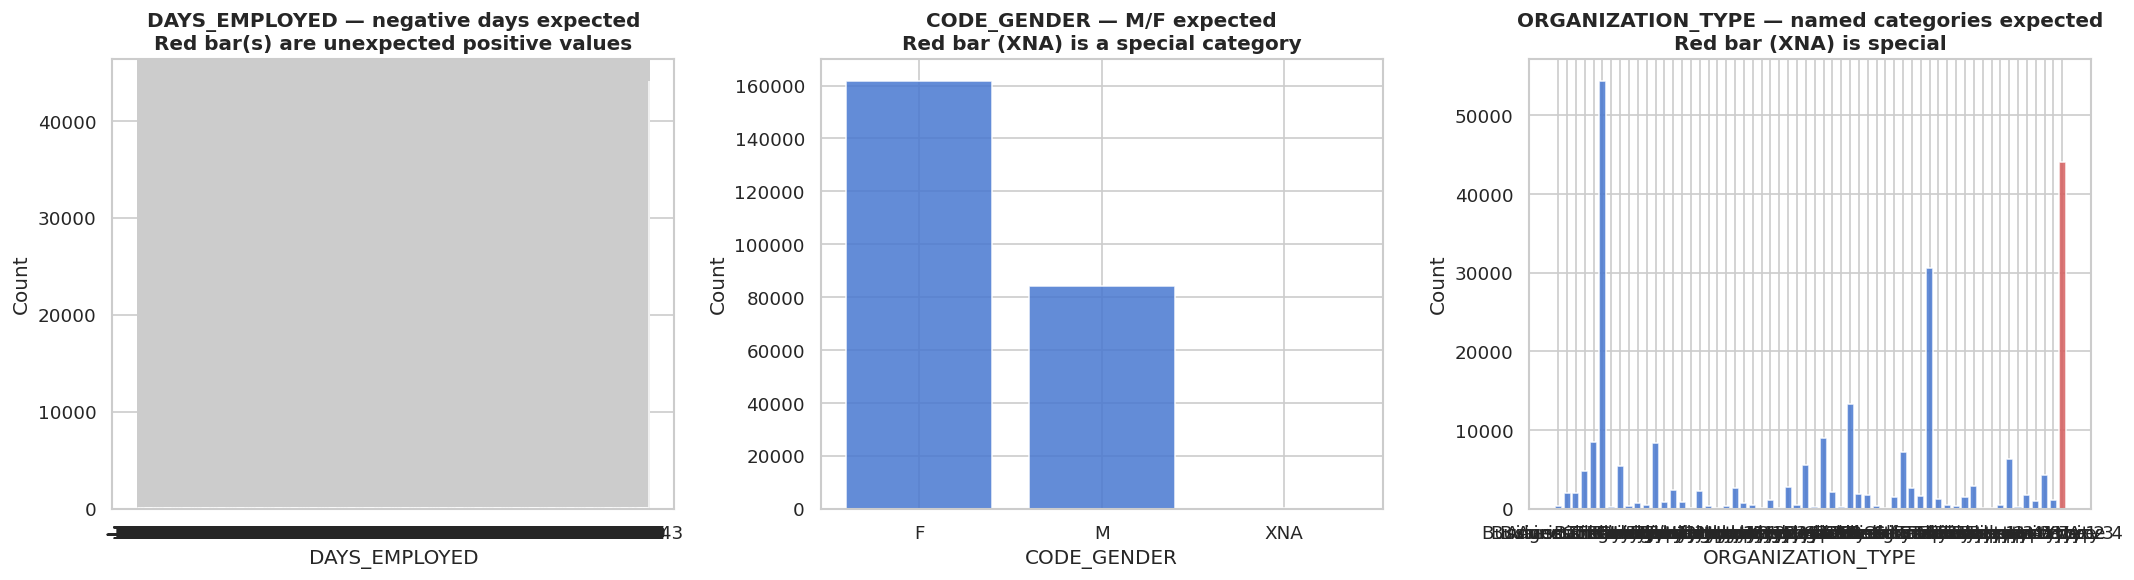

=== ANOMALY 1: DAYS_EMPLOYED contains unexpected positive values ===
  Rows affected: 44,143 (17.94%)
  Unexpected positive value(s):
DAYS_EMPLOYED
365243    44143
Name: count, dtype: int64
  Default rate | positive: 0.0537
  Default rate | expected: 0.0866
  TREATMENT: create a DAYS_EMPLOYED_ANOMALY flag, then replace the
  unexpected positive employment duration with NaN.

=== ANOMALY 2: CODE_GENDER = XNA (special category) ===
  Rows affected: 2 (0.0008%)
  Default rate | XNA: 0.0000
  Default rate | M/F: 0.0807
  TREATMENT: retain the information but relabel XNA as "Unknown" before one-hot.

=== ANOMALY 3: ORGANIZATION_TYPE = XNA (special category) ===
  Rows affected: 44,143 (17.94%)
  Default rate | XNA:   0.0537
  Default rate | other: 0.0866
  TREATMENT: relabel XNA as "Not_applicable" rather than treating it as
  an ordinary missing value.

=== CO-OCCURRENCE CHECK ===
  Positive DAYS_EMPLOYED:         44,143
  ORGANIZATION_TYPE XNA:          44,143
  Both conditions:          

In [ ]:
# A1.4: Domain anomaly detection (TRAINING DATA ONLY)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# DAYS_EMPLOYED: negative days expected, reality includes positive values
emp_counts = tr['DAYS_EMPLOYED'].value_counts().sort_index()
emp_colors = [RED if c > 0 else BLUE for c in emp_counts.index]
axes[0].bar(emp_counts.index.astype(str), emp_counts.values,
            color=emp_colors, alpha=0.85)
axes[0].set_title(
    'DAYS_EMPLOYED — negative days expected\n'
    'Red bar(s) are unexpected positive values',
    fontweight='bold'
)
axes[0].set_xlabel('DAYS_EMPLOYED'); axes[0].set_ylabel('Count')

# CODE_GENDER: M/F expected, reality includes XNA
gender_counts = tr['CODE_GENDER'].value_counts().sort_index()
gender_colors = [RED if c == 'XNA' else BLUE for c in gender_counts.index]
axes[1].bar(gender_counts.index.astype(str), gender_counts.values,
            color=gender_colors, alpha=0.85)
axes[1].set_title('CODE_GENDER — M/F expected\nRed bar (XNA) is a special category',
                  fontweight='bold')
axes[1].set_xlabel('CODE_GENDER'); axes[1].set_ylabel('Count')

# ORGANIZATION_TYPE: named categories expected, reality includes XNA
org_counts = tr['ORGANIZATION_TYPE'].value_counts().sort_index()
org_colors = [RED if c == 'XNA' else BLUE for c in org_counts.index]
axes[2].bar(org_counts.index.astype(str), org_counts.values,
            color=org_colors, alpha=0.85)
axes[2].set_title('ORGANIZATION_TYPE — named categories expected\nRed bar (XNA) is special',
                  fontweight='bold')
axes[2].set_xlabel('ORGANIZATION_TYPE'); axes[2].set_ylabel('Count')

plt.tight_layout()
plt.savefig('/content/a1_anomalies.png', dpi=300, bbox_inches='tight')
plt.show()

# Does each anomalous group default differently?
print('=== ANOMALY 1: DAYS_EMPLOYED contains unexpected positive values ===')
positive_emp = tr['DAYS_EMPLOYED'] > 0
print(f'  Rows affected: {positive_emp.sum():,} ({positive_emp.mean() * 100:.2f}%)')
print('  Unexpected positive value(s):')
print(tr.loc[positive_emp, 'DAYS_EMPLOYED'].value_counts().sort_index())
print(f'  Default rate | positive: {tr.loc[positive_emp, "TARGET"].mean():.4f}')
print(f'  Default rate | expected: {tr.loc[~positive_emp, "TARGET"].mean():.4f}')
print('  TREATMENT: create a DAYS_EMPLOYED_ANOMALY flag, then replace the')
print('  unexpected positive employment duration with NaN.')
print()

print('=== ANOMALY 2: CODE_GENDER = XNA (special category) ===')
gender_xna = tr['CODE_GENDER'] == 'XNA'
print(f'  Rows affected: {gender_xna.sum():,} ({gender_xna.mean() * 100:.4f}%)')
if gender_xna.sum() > 0:
    print(f'  Default rate | XNA: {tr.loc[gender_xna, "TARGET"].mean():.4f}')
    print(f'  Default rate | M/F: {tr.loc[~gender_xna, "TARGET"].mean():.4f}')
print('  TREATMENT: retain the information but relabel XNA as "Unknown" before one-hot.')
print()

print('=== ANOMALY 3: ORGANIZATION_TYPE = XNA (special category) ===')
org_xna = tr['ORGANIZATION_TYPE'] == 'XNA'
print(f'  Rows affected: {org_xna.sum():,} ({org_xna.mean() * 100:.2f}%)')
print(f'  Default rate | XNA:   {tr.loc[org_xna, "TARGET"].mean():.4f}')
print(f'  Default rate | other: {tr.loc[~org_xna, "TARGET"].mean():.4f}')
print('  TREATMENT: relabel XNA as "Not_applicable" rather than treating it as')
print('  an ordinary missing value.')
print()

both = positive_emp & org_xna

print('=== CO-OCCURRENCE CHECK ===')
print(f'  Positive DAYS_EMPLOYED:        {positive_emp.sum():>7,}')
print(f'  ORGANIZATION_TYPE XNA:         {org_xna.sum():>7,}')
print(f'  Both conditions:               {both.sum():>7,}')
print(f'  Positive without org XNA:      {(positive_emp & ~org_xna).sum():>7,}')
print(f'  Org XNA without positive:      {(org_xna & ~positive_emp).sum():>7,}')
print('  READING: if the two counts coincide exactly, the unexpected positive')
print('  DAYS_EMPLOYED values and ORGANIZATION_TYPE = XNA represent the same')
print('  structural employment condition.')
print('  TREATMENT: preserve that information with an anomaly indicator while')
print('  converting the implausible numeric duration to NaN for later imputation.')


**Output explanation.** Three important data issues were found. **44,143 rows** use the special `DAYS_EMPLOYED = 365243` value, the same **44,143 rows** have `ORGANIZATION_TYPE = XNA`, and only **2 rows** have `CODE_GENDER = XNA`. The employment value is treated as a special condition, flagged, and then changed to missing before later imputation.

### A1 Step 6 — Create clear applicant-level features

Apply the same fixed feature-engineering function to both data splits.

In [ ]:
# A1.5: Feature engineering — applied identically to both splits

AMOUNT_COLS = ['AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']

SOCIAL_COLS = ['OBS_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE',
               'DEF_30_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE']

BUREAU_REQ_COLS = ['AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY',
                   'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON',
                   'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']


def engineer_features(frame):
    """Deterministic, row-wise feature engineering. No fitted statistics."""
    d = frame.copy()

    # Clean the domain anomalies from A1.4
    d['DAYS_EMPLOYED_ANOMALY'] = d['DAYS_EMPLOYED'] > 0
    d['DAYS_EMPLOYED'] = d['DAYS_EMPLOYED'].where(d['DAYS_EMPLOYED'] <= 0)
    d['CODE_GENDER'] = d['CODE_GENDER'].replace({'XNA': 'Unknown'})
    d['ORGANIZATION_TYPE'] = d['ORGANIZATION_TYPE'].replace({'XNA': 'Not_applicable'})

    # Credit burden: loan amounts relative to income
    income = d['AMT_INCOME_TOTAL'].replace(0, np.nan)
    burden = d[AMOUNT_COLS].div(income, axis=0)
    d['amount_income_mean']  = burden.mean(axis=1)
    d['credit_income_ratio'] = burden['AMT_CREDIT']             # loan relative to applicant income
    d['amount_income_max']   = burden.max(axis=1)
    d['credit_goods_gap'] = burden['AMT_CREDIT'] - burden['AMT_GOODS_PRICE']

    # Social-circle behaviour: are observed contacts defaulting?
    circle_obs = d[SOCIAL_COLS[:2]].where(d[SOCIAL_COLS[:2]] > 0)  # ratio only meaningful for observed contacts
    circle_def = d[SOCIAL_COLS[2:]]
    circle_ratio = pd.DataFrame(circle_def.values / circle_obs.values, index=d.index)
    d['circle_default_ratio_mean'] = circle_ratio.mean(axis=1, skipna=True).clip(0, 5)  # clip runaway ratios
    d['circle_default_mean']  = circle_def.mean(axis=1)
    d['circle_observed_mean'] = d[SOCIAL_COLS[:2]].mean(axis=1)

    # Credit-bureau enquiry summary of the six request windows
    d['max_bureau_req']       = d[BUREAU_REQ_COLS].max(axis=1)              # busiest period
    d['n_bureau_req_periods'] = (d[BUREAU_REQ_COLS] > 0).sum(axis=1)        # persistence
    d['mean_bureau_req']      = d[BUREAU_REQ_COLS].mean(axis=1)
    d['bureau_req_trend'] = d[BUREAU_REQ_COLS[:3]].mean(axis=1) - d[BUREAU_REQ_COLS[3:]].mean(axis=1)

    d['income_per_family'] = d['AMT_INCOME_TOTAL'] / d['CNT_FAM_MEMBERS'].replace(0, np.nan)

    return d


df_tr_fe = engineer_features(df_tr)
df_te_fe = engineer_features(df_te)

ENGINEERED = ['DAYS_EMPLOYED_ANOMALY', 'amount_income_mean', 'credit_income_ratio',
              'amount_income_max', 'credit_goods_gap', 'circle_default_ratio_mean',
              'circle_default_mean', 'circle_observed_mean', 'max_bureau_req',
              'n_bureau_req_periods', 'mean_bureau_req', 'bureau_req_trend',
              'income_per_family']

print('=== ENGINEERED FEATURES (correlations on TRAINING data only) ===')
print(f'{"Feature":<28} {"corr with target":>18} {"% missing":>11}')
print('-' * 60)
for f in ENGINEERED:
    c = df_tr_fe[f].corr(df_tr_fe['TARGET'])
    m = df_tr_fe[f].isnull().mean() * 100
    print(f'{f:<28} {c:>+18.4f} {m:>10.1f}%')
print()
print('The credit-burden and social-circle features should show how affordability and')
print('surrounding repayment behaviour relate to default, while the bureau-request')
print('features capture the intensity and persistence of recent credit enquiries.')


=== ENGINEERED FEATURES (correlations on TRAINING data only) ===
Feature                        corr with target   % missing
------------------------------------------------------------
DAYS_EMPLOYED_ANOMALY                   -0.0464        0.0%
amount_income_mean                      -0.0117        0.0%
credit_income_ratio                     -0.0074        0.0%
amount_income_max                       -0.0075        0.0%
credit_goods_gap                        +0.0419        0.1%
circle_default_ratio_mean               +0.0413       53.6%
circle_default_mean                     +0.0332        0.3%
circle_observed_mean                    +0.0107        0.3%
max_bureau_req                          +0.0130       13.5%
n_bureau_req_periods                    -0.0158        0.0%
mean_bureau_req                         +0.0105       13.5%
bureau_req_trend                        -0.0098       13.5%
income_per_family                       -0.0054        0.0%

The credit-burden and social-circ

**Output explanation.** The new applicant-level features have mostly small individual correlations with default, which is normal because default risk depends on many factors together. `DAYS_EMPLOYED_ANOMALY`, `credit_goods_gap` and the social-circle default features show some of the clearer simple relationships, so these features are kept for later model testing.

#### A1 Step 6b — Record the engineered features

List each new feature, why it was created, its missing rate and its simple relationship with the target in the development data.

In [ ]:
# A1 Step 6b: record the applicant-level engineered features.

engineered_feature_register = pd.DataFrame([
    ('DAYS_EMPLOYED_ANOMALY',
     'Employment anomaly',
     'The sentinel employment condition may represent a distinct employment status and may carry risk information.'),

    ('amount_income_mean',
     'Affordability',
     'Applicants with larger requested amounts relative to income may have a heavier repayment burden.'),

    ('credit_income_ratio',
     'Affordability',
     'A larger loan relative to income may indicate less repayment headroom.'),

    ('amount_income_max',
     'Affordability',
     'The most demanding amount-to-income component may expose the applicant’s highest burden.'),

    ('credit_goods_gap',
     'Loan structure',
     'Credit materially above the goods value may indicate additional financed cost and a different risk profile.'),

    ('circle_default_ratio_mean',
     'Social-circle behaviour',
     'A higher share of observed social contacts with default events may proxy a riskier surrounding environment.'),

    ('circle_default_mean',
     'Social-circle behaviour',
     'More observed default events in the applicant’s social circle may be associated with higher applicant risk.'),

    ('circle_observed_mean',
     'Social-circle coverage',
     'The amount of observable social-circle information may itself distinguish applicants with different data footprints.'),

    ('max_bureau_req',
     'Credit demand',
     'A high peak in recent credit-bureau enquiries may indicate concentrated credit-seeking activity.'),

    ('n_bureau_req_periods',
     'Credit demand',
     'Enquiries spread across many time windows may indicate persistent credit-seeking behaviour.'),

    ('mean_bureau_req',
     'Credit demand',
     'A higher average enquiry count may indicate sustained demand for new credit.'),

    ('bureau_req_trend',
     'Credit demand',
     'Increasing recent enquiries relative to older periods may indicate accelerating demand for credit.'),

    ('income_per_family',
     'Household affordability',
     'Income shared across more family members may reduce the resources available per person.')
], columns=['Feature', 'Feature_family', 'Hypothesis'])


engineered_feature_register['Train_corr_with_TARGET'] = [
    df_tr_fe[f].corr(df_tr_fe['TARGET'])
    for f in engineered_feature_register['Feature']
]

engineered_feature_register['Missing_%'] = [
    df_tr_fe[f].isna().mean() * 100
    for f in engineered_feature_register['Feature']
]

print('=== A1 APPLICANT-LEVEL FEATURE REGISTER ===')
display(engineered_feature_register.round(4))

print()
print('The hypothesis column is the reason each feature was engineered; the correlation')
print('is only a quick sanity check, not the feature-selection rule. A2 uses three')
print('stronger and complementary selection signals.')


=== A1 APPLICANT-LEVEL FEATURE REGISTER ===


,Feature,Feature_family,Hypothesis,Train_corr_with_TARGET,Missing_%
0,DAYS_EMPLOYED_ANOMALY,Employment anomaly,The sentinel employment condition may represen...,-0.0464,0.0000
1,amount_income_mean,Affordability,Applicants with larger requested amounts relat...,-0.0117,0.0000
2,credit_income_ratio,Affordability,A larger loan relative to income may indicate ...,-0.0074,0.0000
3,amount_income_max,Affordability,The most demanding amount-to-income component ...,-0.0075,0.0000
4,credit_goods_gap,Loan structure,Credit materially above the goods value may in...,0.0419,0.0898
5,circle_default_ratio_mean,Social-circle behaviour,A higher share of observed social contacts wit...,0.0413,53.6210
6,circle_default_mean,Social-circle behaviour,More observed default events in the applicant’...,0.0332,0.3297
7,circle_observed_mean,Social-circle coverage,The amount of observable social-circle informa...,0.0107,0.3297
8,max_bureau_req,Credit demand,A high peak in recent credit-bureau enquiries ...,0.0130,13.5134
9,n_bureau_req_periods,Credit demand,Enquiries spread across many time windows may ...,-0.0158,0.0000



The hypothesis column is the reason each feature was engineered; the correlation
is only a quick sanity check, not the feature-selection rule. A2 uses three
stronger and complementary selection signals.


**Output explanation.** The feature register records each engineered feature, the reason it was created, its simple relationship with the target and its missing rate. This gives a clear record of what was added and why, rather than creating features without explanation.

### A1 Step 7–8 — Summarise and join the supporting Home Credit tables

Reduce each one-to-many table to one row per applicant before using a LEFT join. Then check that the number of application rows has not changed.

In [ ]:
# A1.6: the join skill, applied to Home Credit
# Aggregate each one-to-many table before joining it to the application spine.

def demonstrate_relational_join(frame):
    # Copy the Home Credit tables used in the relational workflow
    df       = frame.copy()
    bur      = bureau.copy()
    bb       = bureau_balance.copy()
    prev     = previous_application.copy()
    inst     = installments_payments.copy()
    pos      = POS_CASH_balance.copy()
    print(f'application {df.shape} | bureau {bur.shape} | bureau_balance {bb.shape} | '
          f'previous {prev.shape} | installments {inst.shape} | POS {pos.shape}')
    n_applicants = len(df)

    # Aggregate bureau_balance to one row per bureau record.
    bb['bb_late'] = bb['STATUS'].isin(['1', '2', '3', '4', '5']).astype(int)

    bb_agg = bb.groupby('SK_ID_BUREAU').agg(
        bb_count        = ('MONTHS_BALANCE', 'count'),
        bb_recent_month = ('MONTHS_BALANCE', 'max'),
        bb_oldest_month = ('MONTHS_BALANCE', 'min'),
        bb_late_rate    = ('bb_late',        'mean'),
        bb_ever_late    = ('bb_late',        'max'),
    ).reset_index()
    print(f'  bureau_balance aggregated: {len(bb):,} rows -> '
          f'{len(bb_agg):,} bureau records (one row each)')

    bur = bur.merge(bb_agg, on='SK_ID_BUREAU', how='left')
    bur['bureau_active'] = (bur['CREDIT_ACTIVE'] == 'Active').astype(int)
    bur['bureau_overdue'] = (bur['CREDIT_DAY_OVERDUE'] > 0).astype(int)

    bureau_agg = bur.groupby('SK_ID_CURR').agg(
        bureau_count              = ('SK_ID_BUREAU',          'count'),
        bureau_active_count       = ('bureau_active',          'sum'),
        bureau_overdue_rate       = ('bureau_overdue',         'mean'),
        bureau_days_credit_recent = ('DAYS_CREDIT',            'max'),
        bureau_credit_mean        = ('AMT_CREDIT_SUM',         'mean'),
        bureau_credit_max         = ('AMT_CREDIT_SUM',         'max'),
        bureau_debt_mean          = ('AMT_CREDIT_SUM_DEBT',    'mean'),
        bureau_overdue_max        = ('AMT_CREDIT_SUM_OVERDUE', 'max'),
        bureau_bb_count_mean      = ('bb_count',               'mean'),
        bureau_late_rate          = ('bb_late_rate',           'mean'),
        bureau_ever_late          = ('bb_ever_late',           'max'),
    ).reset_index()
    print(f'  bureau aggregated: {len(bur):,} rows -> '
          f'{len(bureau_agg):,} applicants (one row each)')

    prev['prev_approved'] = (prev['NAME_CONTRACT_STATUS'] == 'Approved').astype(int)
    prev['prev_refused'] = (prev['NAME_CONTRACT_STATUS'] == 'Refused').astype(int)

    previous_agg = prev.groupby('SK_ID_CURR').agg(
        previous_count         = ('SK_ID_PREV',       'count'),
        previous_credit_mean   = ('AMT_CREDIT',       'mean'),
        previous_credit_max    = ('AMT_CREDIT',       'max'),
        previous_annuity_mean  = ('AMT_ANNUITY',      'mean'),
        previous_goods_mean    = ('AMT_GOODS_PRICE',  'mean'),
        previous_recent        = ('DAYS_DECISION',    'max'),
        previous_approved_rate = ('prev_approved',    'mean'),
        previous_refused_rate  = ('prev_refused',     'mean'),
    ).reset_index()
    print(f'  previous_application aggregated: {len(prev):,} rows -> '
          f'{len(previous_agg):,} applicants (one row each)')

    inst['payment_difference'] = inst['AMT_INSTALMENT'] - inst['AMT_PAYMENT']
    inst['payment_delay'] = inst['DAYS_ENTRY_PAYMENT'] - inst['DAYS_INSTALMENT']
    inst['late_payment'] = (inst['payment_delay'] > 0).astype(int)
    inst['underpayment'] = (inst['payment_difference'] > 0).astype(int)

    installments_agg = inst.groupby('SK_ID_CURR').agg(
        installments_count      = ('SK_ID_PREV',         'count'),
        installment_mean        = ('AMT_INSTALMENT',     'mean'),
        payment_mean            = ('AMT_PAYMENT',        'mean'),
        payment_difference_mean = ('payment_difference', 'mean'),
        payment_difference_max  = ('payment_difference', 'max'),
        payment_delay_mean      = ('payment_delay',      'mean'),
        payment_delay_max       = ('payment_delay',      'max'),
        late_payment_rate       = ('late_payment',       'mean'),
        underpayment_rate       = ('underpayment',       'mean'),
    ).reset_index()
    print(f'  installments_payments aggregated: {len(inst):,} rows -> '
          f'{len(installments_agg):,} applicants (one row each)')

    pos['pos_late'] = (pos['SK_DPD'] > 0).astype(int)

    pos_agg = pos.groupby('SK_ID_CURR').agg(
        pos_count                  = ('SK_ID_PREV',           'count'),
        pos_recent_month           = ('MONTHS_BALANCE',       'max'),
        pos_oldest_month           = ('MONTHS_BALANCE',       'min'),
        pos_instalment_mean        = ('CNT_INSTALMENT',       'mean'),
        pos_instalment_future_mean = ('CNT_INSTALMENT_FUTURE','mean'),
        pos_dpd_mean               = ('SK_DPD',               'mean'),
        pos_dpd_max                = ('SK_DPD',               'max'),
        pos_dpd_def_max            = ('SK_DPD_DEF',           'max'),
        pos_late_rate              = ('pos_late',             'mean'),
    ).reset_index()
    print(f'  POS_CASH_balance aggregated: {len(pos):,} rows -> '
          f'{len(pos_agg):,} applicants (one row each)')

    df = df.merge(bureau_agg,       on='SK_ID_CURR', how='left')
    assert len(df) == n_applicants, (
        f'ROW COUNT CHANGED {n_applicants} -> {len(df)} after bureau merge')

    df = df.merge(previous_agg,     on='SK_ID_CURR', how='left')
    assert len(df) == n_applicants, (
        f'ROW COUNT CHANGED {n_applicants} -> {len(df)} after previous_application merge')

    df = df.merge(installments_agg, on='SK_ID_CURR', how='left')
    assert len(df) == n_applicants, (
        f'ROW COUNT CHANGED {n_applicants} -> {len(df)} after installments merge')

    df = df.merge(pos_agg,          on='SK_ID_CURR', how='left')
    assert len(df) == n_applicants, (
        f'ROW COUNT CHANGED {n_applicants} -> {len(df)} after POS merge')

    assert len(df) == n_applicants, (
        f'ROW COUNT CHANGED {n_applicants} -> {len(df)}: '
        f'a one-to-many merge duplicated the spine')
    assert df['SK_ID_CURR'].is_unique, (
        'SK_ID_CURR is no longer unique after relational joins')
    print(f'  Row-count check PASSED: {n_applicants} applicants in, '
          f'{len(df)} rows out. No duplication.')

    bureau_feat_cols = [
        'bureau_count', 'bureau_active_count', 'bureau_overdue_rate',
        'bureau_days_credit_recent', 'bureau_credit_mean', 'bureau_credit_max',
        'bureau_debt_mean', 'bureau_overdue_max', 'bureau_bb_count_mean',
        'bureau_late_rate', 'bureau_ever_late'
    ]
    no_bureau_history = df['bureau_count'].isnull()
    df[bureau_feat_cols] = df[bureau_feat_cols].fillna(0)
    df['no_bureau_history'] = no_bureau_history.astype(int)
    print(f'  Clients with no bureau history: {no_bureau_history.sum():,}'
          f' -> flagged via no_bureau_history, joined columns set to 0')

    previous_feat_cols = [
        'previous_count', 'previous_credit_mean', 'previous_credit_max',
        'previous_annuity_mean', 'previous_goods_mean', 'previous_recent',
        'previous_approved_rate', 'previous_refused_rate'
    ]
    no_previous_history = df['previous_count'].isnull()
    df[previous_feat_cols] = df[previous_feat_cols].fillna(0)
    df['no_previous_history'] = no_previous_history.astype(int)
    print(f'  Clients with no previous-application history: {no_previous_history.sum():,}'
          f' -> flagged via no_previous_history, joined columns set to 0')

    installments_feat_cols = [
        'installments_count', 'installment_mean', 'payment_mean',
        'payment_difference_mean', 'payment_difference_max',
        'payment_delay_mean', 'payment_delay_max',
        'late_payment_rate', 'underpayment_rate'
    ]
    no_installments_history = df['installments_count'].isnull()
    df[installments_feat_cols] = df[installments_feat_cols].fillna(0)
    df['no_installments_history'] = no_installments_history.astype(int)
    print(f'  Clients with no instalment history: {no_installments_history.sum():,}'
          f' -> flagged via no_installments_history, joined columns set to 0')

    pos_feat_cols = [
        'pos_count', 'pos_recent_month', 'pos_oldest_month',
        'pos_instalment_mean', 'pos_instalment_future_mean',
        'pos_dpd_mean', 'pos_dpd_max', 'pos_dpd_def_max', 'pos_late_rate'
    ]
    no_pos_history = df['pos_count'].isnull()
    df[pos_feat_cols] = df[pos_feat_cols].fillna(0)
    df['no_pos_history'] = no_pos_history.astype(int)
    print(f'  Clients with no POS/CASH history: {no_pos_history.sum():,}'
          f' -> flagged via no_pos_history, joined columns set to 0')

    print(f'\n  Final relational frame: {df.shape}')
    return df


df_tr_rel = demonstrate_relational_join(df_tr_fe)
df_te_rel = demonstrate_relational_join(df_te_fe)

print()
print('Relational feature engineering complete.')
print(f'  Training: {df_tr_fe.shape} -> {df_tr_rel.shape}')
print(f'  Test:     {df_te_fe.shape} -> {df_te_rel.shape}')

assert len(df_tr_rel) == len(df_tr_fe)
assert len(df_te_rel) == len(df_te_fe)
assert df_tr_rel['SK_ID_CURR'].is_unique
assert df_te_rel['SK_ID_CURR'].is_unique


application (246008, 135) | bureau (1716428, 17) | bureau_balance (27299925, 3) | previous (1670214, 37) | installments (808876, 8) | POS (10001358, 8)
  bureau_balance aggregated: 27,299,925 rows -> 817,395 bureau records (one row each)
  bureau aggregated: 1,716,428 rows -> 305,811 applicants (one row each)
  previous_application aggregated: 1,670,214 rows -> 338,857 applicants (one row each)
  installments_payments aggregated: 808,876 rows -> 90,289 applicants (one row each)
  POS_CASH_balance aggregated: 10,001,358 rows -> 337,252 applicants (one row each)
  Row-count check PASSED: 246008 applicants in, 246008 rows out. No duplication.
  Clients with no bureau history: 35,244 -> flagged via no_bureau_history, joined columns set to 0
  Clients with no previous-application history: 13,174 -> flagged via no_previous_history, joined columns set to 0
  Clients with no instalment history: 184,076 -> flagged via no_installments_history, joined columns set to 0
  Clients with no POS/CASH h

**Output explanation.** Each supporting Home Credit table was first reduced to one row per applicant and then joined to the application data. The row-count checks passed for both the development and test sets, so the joins did not create duplicate applicants. Separate flags also record applicants with no history in a supporting table.

#### A1 Step 8b — Record the joined features

List each joined feature, its source table, the summary method used and its purpose.

In [ ]:
# A1 Step 8b: record the relational features and their source tables.

relational_feature_rows = [

    # bureau / bureau_balance
    ('bureau_count', 'bureau', 'count', 'More prior credit records indicate a larger observed credit-history footprint.'),
    ('bureau_active_count', 'bureau', 'sum', 'More active external credits may increase current debt obligations.'),
    ('bureau_overdue_rate', 'bureau', 'mean', 'A higher share of overdue external credits indicates adverse repayment behaviour.'),
    ('bureau_days_credit_recent', 'bureau', 'max', 'More recent external borrowing may indicate current demand for credit.'),
    ('bureau_credit_mean', 'bureau', 'mean', 'Larger typical external credit exposures may increase repayment burden.'),
    ('bureau_credit_max', 'bureau', 'max', 'The largest external credit exposure captures peak historical borrowing.'),
    ('bureau_debt_mean', 'bureau', 'mean', 'Higher average outstanding debt may reduce repayment capacity.'),
    ('bureau_overdue_max', 'bureau', 'max', 'The worst observed overdue amount captures severe external delinquency.'),
    ('bureau_bb_count_mean', 'bureau_balance', 'mean', 'Longer observable bureau histories may distinguish mature from sparse credit files.'),
    ('bureau_late_rate', 'bureau_balance', 'mean', 'A higher monthly late-payment rate indicates persistent external delinquency.'),
    ('bureau_ever_late', 'bureau_balance', 'max', 'Any historical late bureau month may be an important adverse-event flag.'),
    ('no_bureau_history', 'bureau', 'indicator', 'No external bureau history is a different information state from a measured zero.'),

    # previous_application
    ('previous_count', 'previous_application', 'count', 'More previous Home Credit applications indicate repeated credit demand.'),
    ('previous_credit_mean', 'previous_application', 'mean', 'Higher typical previous requested credit may indicate larger borrowing needs.'),
    ('previous_credit_max', 'previous_application', 'max', 'The largest earlier requested amount captures peak borrowing demand.'),
    ('previous_annuity_mean', 'previous_application', 'mean', 'Higher earlier annuities proxy stronger recurring repayment commitments.'),
    ('previous_goods_mean', 'previous_application', 'mean', 'Higher typical financed-goods values describe the scale of prior borrowing.'),
    ('previous_recent', 'previous_application', 'max', 'A more recent prior application may indicate current or repeated credit demand.'),
    ('previous_approved_rate', 'previous_application', 'mean', 'The historical approval share summarises prior lender acceptance patterns.'),
    ('previous_refused_rate', 'previous_application', 'mean', 'A higher refusal share may indicate earlier applications that did not meet lending criteria.'),
    ('no_previous_history', 'previous_application', 'indicator', 'No previous Home Credit application history is distinct from a numeric zero history.'),

    # installments_payments
    ('installments_count', 'installments_payments', 'count', 'More observed instalments provide a deeper behavioural repayment history.'),
    ('installment_mean', 'installments_payments', 'mean', 'Higher scheduled instalments indicate larger recurring payment obligations.'),
    ('payment_mean', 'installments_payments', 'mean', 'Average actual payment describes the scale of realised repayment behaviour.'),
    ('payment_difference_mean', 'installments_payments', 'mean', 'A persistent shortfall between scheduled and actual payment may indicate repayment stress.'),
    ('payment_difference_max', 'installments_payments', 'max', 'The largest payment shortfall captures the worst underpayment episode.'),
    ('payment_delay_mean', 'installments_payments', 'mean', 'Positive average delay indicates systematically late repayment.'),
    ('payment_delay_max', 'installments_payments', 'max', 'The worst payment delay captures severe delinquency.'),
    ('late_payment_rate', 'installments_payments', 'mean', 'A higher proportion of late instalments indicates persistent repayment difficulty.'),
    ('underpayment_rate', 'installments_payments', 'mean', 'A higher proportion of underpayments indicates repeated inability to meet scheduled amounts.'),
    ('no_installments_history', 'installments_payments', 'indicator', 'Absence of instalment history is an information state, not equivalent to perfect repayment.'),

    # POS_CASH_balance
    ('pos_count', 'POS_CASH_balance', 'count', 'More POS/CASH monthly observations indicate a longer observed account history.'),
    ('pos_recent_month', 'POS_CASH_balance', 'max', 'The most recent POS/CASH observation captures recency of account activity.'),
    ('pos_oldest_month', 'POS_CASH_balance', 'min', 'The oldest observation captures depth of the POS/CASH history.'),
    ('pos_instalment_mean', 'POS_CASH_balance', 'mean', 'Average instalment count describes the typical repayment schedule.'),
    ('pos_instalment_future_mean', 'POS_CASH_balance', 'mean', 'More future instalments indicate remaining repayment obligations.'),
    ('pos_dpd_mean', 'POS_CASH_balance', 'mean', 'Higher average days past due indicates persistent delinquency.'),
    ('pos_dpd_max', 'POS_CASH_balance', 'max', 'Maximum days past due captures the worst delinquency episode.'),
    ('pos_dpd_def_max', 'POS_CASH_balance', 'max', 'Maximum tolerated days past due captures severe delinquency under the contractual definition.'),
    ('pos_late_rate', 'POS_CASH_balance', 'mean', 'A higher proportion of late POS/CASH months indicates repeated repayment difficulty.'),
    ('no_pos_history', 'POS_CASH_balance', 'indicator', 'No POS/CASH history is a distinct data state and should not be silently treated as zero.')
]

relational_feature_register = pd.DataFrame(
    relational_feature_rows,
    columns=['Feature', 'Source_table', 'Aggregation', 'Hypothesis']
)

relational_feature_register['Train_corr_with_TARGET'] = [
    df_tr_rel[f].corr(df_tr_rel['TARGET'])
    if f in df_tr_rel.columns else np.nan
    for f in relational_feature_register['Feature']
]

relational_feature_register['Missing_%'] = [
    df_tr_rel[f].isna().mean() * 100
    if f in df_tr_rel.columns else np.nan
    for f in relational_feature_register['Feature']
]

print('=== A1 RELATIONAL FEATURE REGISTER ===')
print(f'{len(relational_feature_register)} documented relational features')
display(relational_feature_register.round(4))

print()
print('Every feature above was created after aggregation to one row per join key.')
print('The row-count assertions in A1.6 remain the integrity check that the joins did')
print('not duplicate applicants or corrupt the TARGET relationship.')


=== A1 RELATIONAL FEATURE REGISTER ===
41 documented relational features


,Feature,Source_table,Aggregation,Hypothesis,Train_corr_with_TARGET,Missing_%
0,bureau_count,bureau,count,More prior credit records indicate a larger ob...,-0.0092,0.0
1,bureau_active_count,bureau,sum,More active external credits may increase curr...,0.0432,0.0
2,bureau_overdue_rate,bureau,mean,A higher share of overdue external credits ind...,0.0257,0.0
3,bureau_days_credit_recent,bureau,max,More recent external borrowing may indicate cu...,0.0533,0.0
4,bureau_credit_mean,bureau,mean,Larger typical external credit exposures may i...,-0.0242,0.0
5,bureau_credit_max,bureau,max,The largest external credit exposure captures ...,-0.0238,0.0
6,bureau_debt_mean,bureau,mean,Higher average outstanding debt may reduce rep...,-0.0040,0.0
7,bureau_overdue_max,bureau,max,The worst observed overdue amount captures sev...,0.0087,0.0
8,bureau_bb_count_mean,bureau_balance,mean,Longer observable bureau histories may disting...,-0.0251,0.0
9,bureau_late_rate,bureau_balance,mean,A higher monthly late-payment rate indicates p...,0.0332,0.0



Every feature above was created after aggregation to one row per join key.
The row-count assertions in A1.6 remain the integrity check that the joins did
not duplicate applicants or corrupt the TARGET relationship.


**Output explanation.** The relational feature register documents **41 features** created from the supporting tables. It records the source table and the type of summary used, making the joined features easier to trace and explain.

### A1 wrap-up

A1 produces **`df_tr_rel`** and **`df_te_rel`**, which contain the cleaned application data and the joined applicant-level features needed for feature selection.

---
# A2 — Feature Selection

### A2 Step 1 — Build the modelling feature set

In [ ]:
# A2.0: Assemble the modelling feature list
DROP_COLS = ['TARGET', 'SK_ID_CURR']

# Numeric: application, engineered and relational features
NUMERIC_FEATS = [c for c in df_tr_rel.select_dtypes(include=[np.number]).columns
                 if c not in DROP_COLS]

# Categorical: nominal Home Credit columns -> one-hot, never ordinal
CAT_FEATS = [c for c in df_tr_rel.select_dtypes(
    include=['object', 'string', 'category']).columns
             if c not in DROP_COLS]

ALL_FEATS = NUMERIC_FEATS + CAT_FEATS

for c in CAT_FEATS:
    df_tr_rel[c] = df_tr_rel[c].astype('object')
    df_te_rel[c] = df_te_rel[c].astype('object')

X_tr = df_tr_rel[ALL_FEATS].copy()
y_tr = df_tr_rel['TARGET'].copy()
X_te = df_te_rel[ALL_FEATS].copy()
y_te = df_te_rel['TARGET'].copy()

print('=== FEATURE INVENTORY ===')
print(f'  Numeric features:     {len(NUMERIC_FEATS):>3}')
print(f'  Categorical features: {len(CAT_FEATS):>3}  (one-hot encoded later)')
print(f'  Total input columns:  {len(ALL_FEATS):>3}')
print()
print(f'  X_tr = {X_tr.shape}  -- all training and tuning happens here')
print(f'  X_te = {X_te.shape}  -- sealed until A6')


=== FEATURE INVENTORY ===
  Numeric features:     157
  Categorical features:  16  (one-hot encoded later)
  Total input columns:  173

  X_tr = (246008, 173)  -- all training and tuning happens here
  X_te = (61503, 173)  -- sealed until A6


**Output explanation.** The modelling data contains **173 source features: 157 numeric and 16 categorical**. The development set has **246,008 rows**, while the **61,503-row** test set remains held out for later evaluation.

### A2 Step 2 — Build a temporary screening matrix

Create a clean numeric matrix for feature-selection checks. This matrix is used for screening only; the final preprocessing remains inside the modelling pipeline.

In [ ]:
# A2 Step 2 — Build a crude screening matrix
# Use this quick matrix only for feature screening; final preprocessing is built later.

num_pipe_crude = Pipeline([('imp', SimpleImputer(strategy='median')),
                           ('sc',  StandardScaler())])

cat_pipe_crude = Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                           ('ohe', OneHotEncoder(drop='first', sparse_output=False,
                                                 handle_unknown='ignore'))])

preprocessor_crude = ColumnTransformer([
    ('num', num_pipe_crude, NUMERIC_FEATS),
    ('cat', cat_pipe_crude, CAT_FEATS),
], remainder='drop')

preprocessor_crude.fit(X_tr, y_tr)

X_tr_mat = preprocessor_crude.transform(X_tr)

FEAT_NAMES, FEAT_SOURCE = ohe_name_to_source(
    preprocessor_crude,
    CAT_FEATS
)

print(f'Input columns:  {len(ALL_FEATS)}')
print(f'Output columns: {X_tr_mat.shape[1]}  (after one-hot expansion)')
print(f'Training matrix: {X_tr_mat.shape}')

assert not np.isnan(X_tr_mat).any() and np.isfinite(X_tr_mat).all(), \
    'NaN/inf survived crude prep'

print('Sanity check PASSED: no NaN, no inf.')


Input columns:  173
Output columns: 287  (after one-hot expansion)
Training matrix: (246008, 287)
Sanity check PASSED: no NaN, no inf.


**Output explanation.** After simple screening preprocessing and one-hot encoding, **173 source columns become 287 model columns**. The final screening matrix contains no missing or infinite values, so it is suitable for the feature-selection checks that follow.

### A2 Step 3 — Collect three feature-selection signals

Use L1 Logistic Regression, LightGBM importance and permutation importance so feature selection is not based on one method alone.

In [ ]:
# A2 Step 3 — Collect three independent feature-selection signals

# Signal 1: L1 logistic regression
l1_model = LogisticRegression(penalty='l1', solver='liblinear', C=0.1,
                              class_weight='balanced', max_iter=1000,
                              random_state=RANDOM_STATE).fit(X_tr_mat, y_tr)
l1_imp = np.abs(l1_model.coef_[0])
print(f'[1] L1 logistic: {(l1_imp > 0).sum()} of {len(l1_imp)} coefficients non-zero')

# Signal 2: LightGBM GAIN importance (NOT the default 'split')
lgb_fs = LGBMClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                        num_leaves=31, class_weight='balanced',
                        importance_type='gain',       # <-- the line that matters
                        random_state=RANDOM_STATE, verbose=-1, n_jobs=-1).fit(X_tr_mat, y_tr)
gain_imp = lgb_fs.feature_importances_.astype(float)

lgb_split = LGBMClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                           num_leaves=31, class_weight='balanced', importance_type='split',
                           random_state=RANDOM_STATE, verbose=-1, n_jobs=-1).fit(X_tr_mat, y_tr)

rho_gs = stats.spearmanr(gain_imp, lgb_split.feature_importances_).statistic
print(f'[2] LightGBM gain: {(gain_imp > 0).sum()} features used;'
      f' Spearman(gain, split) = {rho_gs:.3f}')
print('    (checked the gain-vs-split distinction rather than accepting the default)')

# Signal 3: permutation importance on a held-out slice
perm_fit, perm_eval = train_test_split(np.arange(len(X_tr_mat)), test_size=0.3,
                                       stratify=y_tr, random_state=RANDOM_STATE)

lgb_perm = LGBMClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                          num_leaves=31, class_weight='balanced',
                          random_state=RANDOM_STATE,
                          verbose=-1, n_jobs=-1).fit(X_tr_mat[perm_fit],
                                                    y_tr.values[perm_fit])

perm_result = permutation_importance(lgb_perm,
                                     X_tr_mat[perm_eval],
                                     y_tr.values[perm_eval],
                                     scoring='roc_auc',
                                     n_repeats=5,
                                     random_state=RANDOM_STATE,
                                     n_jobs=-1)

perm_imp = perm_result.importances_mean

print(f'[3] Permutation: {(perm_imp < 0).sum()} features have negative score '
      f'(candidates for dropping)')


[1] L1 logistic: 235 of 287 coefficients non-zero
[2] LightGBM gain: 228 features used; Spearman(gain, split) = 0.991
    (checked the gain-vs-split distinction rather than accepting the default)
[3] Permutation: 55 features have negative score (candidates for dropping)


**Output explanation.** The three feature-selection methods give different signals. L1 Logistic Regression keeps **235 of 287** coefficients, LightGBM uses **228** features, and permutation importance finds **55** features with negative scores. Because the methods judge usefulness differently, the notebook compares them before choosing a smaller feature set.

### A2 Step 4 — Compare the methods and choose the working feature set

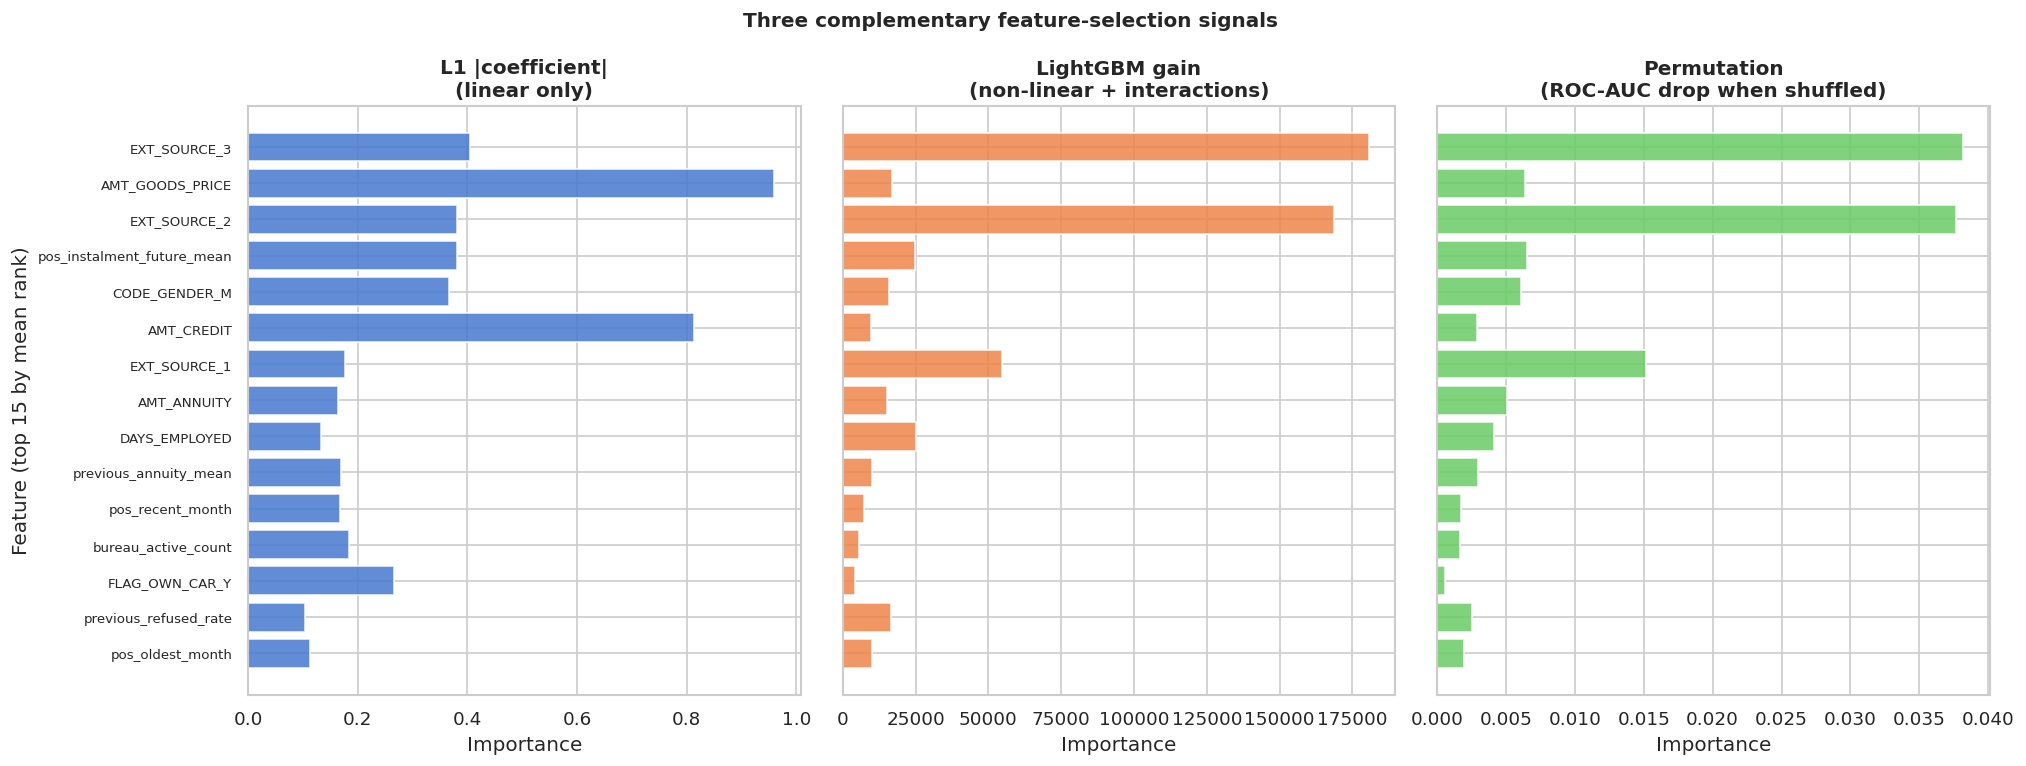

=== RANK AGREEMENT ===
  L1           vs LGB_gain     Spearman +0.328   top-15 overlap 5/15
  L1           vs Permutation  Spearman +0.299   top-15 overlap 6/15
  LGB_gain     vs Permutation  Spearman +0.677   top-15 overlap 12/15

  In the top-15 of ALL THREE (5): ['AMT_GOODS_PRICE', 'CODE_GENDER_M', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'pos_instalment_future_mean']
  Tree methods only (candidate interactions): ['AMT_ANNUITY', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'EXT_SOURCE_1', 'NAME_EDUCATION_TYPE_Higher education', 'bureau_credit_max', 'bureau_days_credit_recent', 'bureau_debt_mean', 'credit_goods_gap', 'pos_count', 'previous_annuity_mean', 'previous_refused_rate']

=== TOP 15 BY MEAN RANK ===
                   feature  L1_rank  LGB_gain_rank  Permutation_rank  mean_rank
              EXT_SOURCE_3      7.0            1.0               1.0   3.000000
           AMT_GOODS_PRICE      1.0            8.0               5.0   4.666667
              EXT_SOURCE_2     11.0            2.0              

In [ ]:
# A2 Step 4 — Compare agreement and choose the working subset

fs = pd.DataFrame({'feature': FEAT_NAMES,
                   'source':  [FEAT_SOURCE[f] for f in FEAT_NAMES],
                   'L1': l1_imp, 'LGB_gain': gain_imp, 'Permutation': perm_imp})
for col in ['L1', 'LGB_gain', 'Permutation']:
    fs[f'{col}_rank'] = fs[col].rank(ascending=False, method='min')
fs['mean_rank'] = fs[['L1_rank', 'LGB_gain_rank',
                      'Permutation_rank']].mean(axis=1)
fs = fs.sort_values('mean_rank').reset_index(drop=True)


# Side-by-side visualisation
top15 = fs.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 3, figsize=(17, 6.5), sharey=True)
for ax, col, title, colr in zip(
        axes,
        ['L1', 'LGB_gain', 'Permutation'],
        ['L1 |coefficient|\n(linear only)',
         'LightGBM gain\n(non-linear + interactions)',
         'Permutation\n(ROC-AUC drop when shuffled)'],
        [BLUE, ORANGE, GREEN]):
    ax.barh(top15['feature'], top15[col], color=colr, alpha=0.85)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Importance')
    ax.tick_params(axis='y', labelsize=8)
axes[0].set_ylabel('Feature (top 15 by mean rank)')
plt.suptitle(
    'Three complementary feature-selection signals',
    fontweight='bold',
    fontsize=12
)
plt.tight_layout()
plt.savefig('/content/a2_signals.png', dpi=300, bbox_inches='tight')
plt.show()


# Rank agreement
K = 15
top_sets = {
    c: set(fs.nsmallest(K, f'{c}_rank')['feature'])
    for c in ['L1', 'LGB_gain', 'Permutation']
}
print('=== RANK AGREEMENT ===')
for a, b in combinations(['L1', 'LGB_gain', 'Permutation'], 2):
    rho = stats.spearmanr(
        fs[f'{a}_rank'],
        fs[f'{b}_rank']
    ).statistic
    ov = len(top_sets[a] & top_sets[b])
    print(
        f'  {a:<12} vs {b:<12} '
        f'Spearman {rho:>+.3f}   '
        f'top-{K} overlap {ov}/{K}'
    )

unanimous = (
    top_sets['L1']
    &
    top_sets['LGB_gain']
    &
    top_sets['Permutation']
)
print(
    f'\n  In the top-{K} of ALL THREE '
    f'({len(unanimous)}): {sorted(unanimous)}'
)
tree_only = (
    top_sets['LGB_gain']
    |
    top_sets['Permutation']
) - top_sets['L1']

print(
    f'  Tree methods only '
    f'(candidate interactions): {sorted(tree_only)}'
)
print()
print('=== TOP 15 BY MEAN RANK ===')
print(
    fs.head(15)[
        ['feature', 'L1_rank', 'LGB_gain_rank',
         'Permutation_rank', 'mean_rank']
    ].to_string(index=False)
)


# Selection: union of the top-K from each method

selected_ohe = set().union(*top_sets.values())
selected_sources = {
    FEAT_SOURCE[f]
    for f in selected_ohe
}
sel_num = [
    c for c in NUMERIC_FEATS
    if c in selected_sources
]
sel_cat = [
    c for c in CAT_FEATS
    if c in selected_sources
]
SELECTED_FEATURES = sel_num + sel_cat


selected_features = SELECTED_FEATURES.copy()
print(
    f'\n=== SELECTION: union of top-{K} across the three methods ==='
)
print(
    f'  {len(SELECTED_FEATURES)} source columns: '
    f'{len(sel_num)} numeric, '
    f'{len(sel_cat)} categorical'
)
print(
    f'  Numeric: {sel_num}'
)
print(
    f'  Categorical: '
    f'{sel_cat if sel_cat else "(none survived -- report this honestly)"}'
)
assert len(sel_num) > 0, (
    'No numeric features selected -- check the rule'
)
X_tr_sel = X_tr[SELECTED_FEATURES].copy()
X_te_sel = X_te[SELECTED_FEATURES].copy()


**Output explanation.** LightGBM gain and permutation importance agree most strongly, with **Spearman correlation 0.677** and **12 of the same top 15 features**. Five features appear in the top 15 of all three methods. Taking the union of the top features gives **21 source columns: 17 numeric and 4 categorical**.

### A2 Step 5 — Check the effect of feature reduction

Compare the full and reduced feature sets on the same cross-validation folds to see how much performance and training time change.

In [ ]:
# A2.6: Validate the reduction — full vs reduced
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
def quick_lgb():
    return LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                          class_weight='balanced', random_state=RANDOM_STATE,
                          verbose=-1, n_jobs=-1)

pipe_full = Pipeline([('prep', clone(preprocessor_crude)), ('clf', quick_lgb())])
t0 = time.time()
auc_full = cross_val_score(pipe_full, X_tr, y_tr, cv=cv3, scoring='roc_auc', n_jobs=1)
t_full = time.time() - t0

prep_reduced_crude = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), sel_num),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('ohe', OneHotEncoder(drop='first', sparse_output=False,
                                            handle_unknown='ignore'))]), sel_cat),
], remainder='drop')
pipe_red = Pipeline([('prep', prep_reduced_crude), ('clf', quick_lgb())])
t0 = time.time()
auc_red = cross_val_score(pipe_red, X_tr_sel, y_tr, cv=cv3, scoring='roc_auc', n_jobs=1)
t_red = time.time() - t0
n_out_red = clone(prep_reduced_crude).fit_transform(X_tr_sel, y_tr).shape[1]

print('=== FULL vs REDUCED (3-fold CV, identical folds) ===')
print(f'{"":<14} {"Model cols":>11} {"ROC-AUC":>18} {"Fit s":>8}')
print('-' * 54)
print(f'{"Full":<14} {X_tr_mat.shape[1]:>11} {auc_full.mean():>10.4f} +/- {auc_full.std():.3f} {t_full:>8.1f}')
print(f'{"Reduced":<14} {n_out_red:>11} {auc_red.mean():>10.4f} +/- {auc_red.std():.3f} {t_red:>8.1f}')
print('-' * 54)
print(f'{"Change":<14} {n_out_red - X_tr_mat.shape[1]:>+11} {auc_red.mean() - auc_full.mean():>+16.4f} {t_red - t_full:>+8.1f}')
print()
print('A small AUC change in either direction is the expected, acceptable outcome. A')
print('gain means the dropped columns were noise the full model mildly overfit.')


=== FULL vs REDUCED (3-fold CV, identical folds) ===
                Model cols            ROC-AUC    Fit s
------------------------------------------------------
Full                   287     0.7702 +/- 0.002     49.1
Reduced                 98     0.7600 +/- 0.003     15.8
------------------------------------------------------
Change                -189          -0.0101    -33.3

A small AUC change in either direction is the expected, acceptable outcome. A
gain means the dropped columns were noise the full model mildly overfit.


**Output explanation.** Reducing the model from **287 to 98 columns** lowers mean ROC-AUC from **0.7702 to 0.7600**, a drop of about **0.0101**. Fit time also falls from **49.1 seconds to 15.8 seconds**. The reduced set is kept because it is much smaller and faster while retaining most of the ranking performance.

### A2 Step 6 — Build the final preprocessing pipeline

Use the selected numeric and categorical features in one shared preprocessing setup for all later models.

In [ ]:
# A1 Part B: final domain-aware pipeline on the surviving features
SKEW_THRESHOLD = 2.0
skew_candidates = [c for c in sel_num
                   if (X_tr_sel[c].min(skipna=True) >= 0)
                   and abs(X_tr_sel[c].skew(skipna=True)) > SKEW_THRESHOLD]
sel_num_skewed = skew_candidates
sel_num_plain  = [c for c in sel_num if c not in sel_num_skewed]

log1p_tf = FunctionTransformer(np.log1p, feature_names_out='one-to-one')
prep_sel = ColumnTransformer([
    ('num_skew', Pipeline([('log', log1p_tf),
                           ('imp', SimpleImputer(strategy='median')),
                           ('sc',  StandardScaler())]), sel_num_skewed),
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc',  StandardScaler())]), sel_num_plain),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('ohe', OneHotEncoder(drop='first', sparse_output=False,
                                            handle_unknown='ignore'))]), sel_cat),
], remainder='drop')

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision',
           'recall': 'recall', 'brier': 'neg_brier_score'}
fold_scores, leaderboard, tuned_models = {}, [], {}
POS_WEIGHT = (y_tr == 0).sum() / (y_tr == 1).sum()

print('=== SHARED SETUP ===')
print(f'  Skewed (log1p) numerics: {sel_num_skewed}')
print(f'  Plain numerics:          {sel_num_plain}')
print(f'  One-hot categoricals:    {sel_cat}')
print(f'  cv5 = StratifiedKFold(5, shuffle=True, random_state={RANDOM_STATE})')
print(f'  POS_WEIGHT = {POS_WEIGHT:.2f}')
_check = clone(prep_sel).fit_transform(X_tr_sel, y_tr)
print(f'  Model matrix width: {_check.shape[1]} columns')
assert np.isfinite(_check).all(), 'Non-finite survived prep_sel'
print('  Sanity check PASSED.')
del _check


=== SHARED SETUP ===
  Skewed (log1p) numerics: ['BASEMENTAREA_MEDI', 'bureau_credit_max', 'previous_annuity_mean']
  Plain numerics:          ['AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'credit_goods_gap', 'bureau_days_credit_recent', 'bureau_debt_mean', 'previous_refused_rate', 'pos_count', 'pos_instalment_future_mean']
  One-hot categoricals:    ['CODE_GENDER', 'NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
  cv5 = StratifiedKFold(5, shuffle=True, random_state=42)
  POS_WEIGHT = 11.39
  Model matrix width: 98 columns
  Sanity check PASSED.


**Output explanation.** The final shared preprocessing setup uses **21 selected source features**, which become **98 model columns** after one-hot encoding. Three skewed numeric features receive a log transform, other numeric features are imputed and scaled, and four categorical variables are imputed and one-hot encoded. All later models use the same five stratified folds.

### A2 wrap-up

The reduced feature set keeps most of the ROC-AUC while making later model training much smaller and faster. Preprocessing remains inside each training fold to reduce data leakage.

---
# A3 — Classical Machine Learning

A3 compares four classical model families using the same cross-validation folds, checks whether RBF SVM gives enough extra value to justify its cost, and tunes the main settings.

### A3 Step 1 — Check whether RBF SVM is worth the extra time

In [ ]:
# A3 Step 1 — Test whether RBF SVM is worth using
X_probe, _, y_probe, _ = train_test_split(X_tr_sel, y_tr, train_size=5000,
                                          stratify=y_tr, random_state=RANDOM_STATE)
cv3_probe = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
probe = {}
for label, clf in [
    ('Linear SVM', CalibratedClassifierCV(LinearSVC(C=0.1, class_weight='balanced',
                    max_iter=5000, random_state=RANDOM_STATE), cv=3)),
    ('RBF SVM', SVC(kernel='rbf', C=1.0, gamma='scale', probability=True,
                    class_weight='balanced', random_state=RANDOM_STATE))]:
    pipe = Pipeline([('prep', clone(prep_sel)), ('clf', clf)])
    t0 = time.time()
    sc = cross_val_score(pipe, X_probe, y_probe, cv=cv3_probe,
                         scoring='roc_auc', n_jobs=1)
    probe[label] = (sc.mean(), time.time() - t0)
print(f'=== KERNEL PROBE on {len(X_probe):,} rows (3-fold CV) ===')
for label, (m, t) in probe.items():
    print(f'  {label:<12} ROC-AUC {m:.4f}   fit {t:.1f}s')
gap = probe['RBF SVM'][0] - probe['Linear SVM'][0]
print(f'  RBF advantage: {gap:+.4f} AUC at '
      f'{probe["RBF SVM"][1] / max(probe["Linear SVM"][1], 1e-9):.0f}x cost')
print('  If the gap is under ~0.005, the LinearSVC substitution is justified on efficiency.')


=== KERNEL PROBE on 5,000 rows (3-fold CV) ===
  Linear SVM   ROC-AUC 0.6805   fit 0.5s
  RBF SVM      ROC-AUC 0.6858   fit 13.3s
  RBF advantage: +0.0053 AUC at 27x cost
  If the gap is under ~0.005, the LinearSVC substitution is justified on efficiency.


**Output explanation.** On the 5,000-row check, RBF SVM reaches **0.6858 ROC-AUC** compared with **0.6805** for linear SVM. The gain is only **0.0053**, while RBF takes about **27 times longer** to fit. The linear SVM is therefore kept as the more efficient option, although the RBF result is slightly higher.

### A3 Step 2 — Compare the classical base models

In [ ]:
# A3 Step 2 — Compare the classical base models

print('=== CLASSICAL — BASE (5-fold CV) ===')
print(f'{"Model":<26} {"ROC-AUC":>18} {"PR-AUC":>9} {"Recall":>8} {"Brier":>8}')
print('-' * 74)
classical_base = {}
def run_and_record(name, pipe, stage):
    cv = cross_validate(pipe, X_tr_sel, y_tr, cv=cv5, scoring=SCORING, n_jobs=1)
    roc = cv['test_roc_auc']
    fold_scores[name] = roc
    leaderboard.append({'Model': name, 'Stage': stage, 'ROC_AUC': roc.mean(),
                        'ROC_AUC_std': roc.std(), 'PR_AUC': cv['test_pr_auc'].mean(),
                        'Recall': cv['test_recall'].mean(), 'Brier': -cv['test_brier'].mean()})
    print(f'{name:<26} {roc.mean():>10.4f} +/- {roc.std():.3f} {cv["test_pr_auc"].mean():>9.4f}'
          f' {cv["test_recall"].mean():>8.4f} {-cv["test_brier"].mean():>8.4f}')
    return roc


run_and_record('Dummy (stratified)',
    Pipeline([('prep', clone(prep_sel)), ('clf', DummyClassifier(strategy='stratified',
              random_state=RANDOM_STATE))]), 'A3-base')
classical_base['Logistic Regression'] = run_and_record('Logistic Regression (base)',
    Pipeline([('prep', clone(prep_sel)), ('clf', LogisticRegression(C=1.0,
              class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE))]), 'A3-base')
classical_base['SVM (linear)'] = run_and_record('SVM (linear, base)',
    Pipeline([('prep', clone(prep_sel)), ('clf', CalibratedClassifierCV(LinearSVC(C=0.1,
              class_weight='balanced', max_iter=5000, random_state=RANDOM_STATE), cv=3))]), 'A3-base')
classical_base['k-NN'] = run_and_record('k-NN (base, k=25)',
    Pipeline([('prep', clone(prep_sel)), ('clf', KNeighborsClassifier(n_neighbors=25,
              n_jobs=-1))]), 'A3-base')
classical_base['Naive Bayes'] = run_and_record('Naive Bayes (base)',
    Pipeline([('prep', clone(prep_sel)), ('clf', GaussianNB())]), 'A3-base')
print('\nEvery model above must be judged against the ~0.5 random-ranking ROC-AUC baseline.')
print(f'PR-AUC no-skill baseline = {y_tr.mean():.4f}')


=== CLASSICAL — BASE (5-fold CV) ===
Model                                 ROC-AUC    PR-AUC   Recall    Brier
--------------------------------------------------------------------------
Dummy (stratified)             0.5009 +/- 0.003    0.0809   0.0822   0.1481
Logistic Regression (base)     0.7465 +/- 0.003    0.2223   0.6759   0.2037
SVM (linear, base)             0.7465 +/- 0.003    0.2226   0.0114   0.0687
k-NN (base, k=25)              0.6945 +/- 0.003    0.1780   0.0067   0.0709
Naive Bayes (base)             0.6384 +/- 0.003    0.1224   0.8483   0.6068

Every model above must be judged against the ~0.5 random-ranking ROC-AUC baseline.
PR-AUC no-skill baseline = 0.0807


**Output explanation.** Logistic Regression and linear SVM are the strongest base classical models, both at about **0.7465 ROC-AUC**. k-NN is lower at **0.6945**, while Naive Bayes is lowest at **0.6384**. Recall varies greatly at the default 0.5 threshold, so threshold choice is examined later rather than using recall alone to select a model here.

### A3 Step 3 — Tune the classical models

Tune a small set of important settings and compare the tuned ROC-AUC with each base model.

In [ ]:
# A3 Step 3 — Tune the classical models
print('=== CLASSICAL — TUNED ===')
print(f'{"Model":<22} {"Base":>8} {"Tuned":>8} {"Gain":>8}  Best params')
print('-' * 78)
def tune_and_record(name_base, name_tuned, estimator, grid, base_scores):
    gs = GridSearchCV(estimator, grid, cv=cv5, scoring='roc_auc', n_jobs=1, refit=True)
    gs.fit(X_tr_sel, y_tr)
    cv = cross_validate(clone(gs.best_estimator_), X_tr_sel, y_tr,
                        cv=cv5, scoring=SCORING, n_jobs=1)
    roc = cv['test_roc_auc']
    fold_scores[name_tuned] = roc
    leaderboard.append({'Model': name_tuned, 'Stage': 'A3-tuned',
                        'ROC_AUC': roc.mean(),
                        'ROC_AUC_std': roc.std(),
                        'PR_AUC': cv['test_pr_auc'].mean(),
                        'Recall': cv['test_recall'].mean(),
                        'Brier': -cv['test_brier'].mean()})

    tuned_models[name_tuned] = clone(gs.best_estimator_)
    params = {k.split('__')[-1]: v for k, v in gs.best_params_.items()}
    print(f'{name_base:<22} {base_scores.mean():>8.4f} {roc.mean():>8.4f}'
          f' {roc.mean() - base_scores.mean():>+8.4f}  {params}')


# Logistic Regression: tune regularisation strength C
tune_and_record('Logistic Regression', 'Logistic Regression (tuned)',
    Pipeline([('prep', clone(prep_sel)), ('clf', LogisticRegression(
              class_weight='balanced', max_iter=2000,
              random_state=RANDOM_STATE))]),
    {'clf__C': [0.01, 0.1, 1.0, 10.0]},
    classical_base['Logistic Regression'])


# Linear SVM: tune regularisation strength C
tune_and_record('SVM (linear)', 'SVM (linear, tuned)',
    Pipeline([('prep', clone(prep_sel)), ('clf', CalibratedClassifierCV(
              LinearSVC(class_weight='balanced', max_iter=5000,
                        random_state=RANDOM_STATE), cv=3))]),
    {'clf__estimator__C': [0.01, 0.1, 1.0]},
    classical_base['SVM (linear)'])


# k-NN: tune the number of neighbours
tune_and_record('k-NN', 'k-NN (tuned)',
    Pipeline([('prep', clone(prep_sel)),
              ('clf', KNeighborsClassifier(n_jobs=-1))]),
    {'clf__n_neighbors': [15, 35, 75]},
    classical_base['k-NN'])


# Naive Bayes: tune variance smoothing
tune_and_record('Naive Bayes', 'Naive Bayes (tuned)',
    Pipeline([('prep', clone(prep_sel)),
              ('clf', GaussianNB())]),
    {'clf__var_smoothing': np.logspace(-11, -5, 7)},
    classical_base['Naive Bayes'])

print()
print('The table above shows the observed ROC-AUC change after tuning each')
print('classical model family and the hyperparameters selected by grid search.')


=== CLASSICAL — TUNED ===
Model                      Base    Tuned     Gain  Best params
------------------------------------------------------------------------------
Logistic Regression      0.7465   0.7466  +0.0001  {'C': 0.01}
SVM (linear)             0.7465   0.7466  +0.0000  {'C': 0.01}
k-NN                     0.6945   0.7263  +0.0317  {'n_neighbors': 75}
Naive Bayes              0.6384   0.6384  +0.0001  {'var_smoothing': np.float64(9.999999999999999e-06)}

The table above shows the observed ROC-AUC change after tuning each
classical model family and the hyperparameters selected by grid search.


**Output explanation.** Tuning changes Logistic Regression, linear SVM and Naive Bayes very little. k-NN improves the most, moving from **0.6945 to 0.7263 ROC-AUC** with **75 neighbours**. Even after this gain, k-NN remains below the two linear models.

### A3 Step 4 — Compare base and tuned classical models

Place the base and tuned results side by side so the effect of tuning is clear for each model family.

In [ ]:
# A3 Step 4: compare base and tuned classical models.

classical_review = pd.DataFrame([
    {
        'Model': 'Logistic Regression',
        'Base_ROC_AUC': classical_base['Logistic Regression'].mean(),
        'Tuned_ROC_AUC': fold_scores['Logistic Regression (tuned)'].mean(),
        'Theory_link': 'Linear log-odds boundary; regularisation mainly controls coefficient shrinkage.'
    },
    {
        'Model': 'SVM (linear)',
        'Base_ROC_AUC': classical_base['SVM (linear)'].mean(),
        'Tuned_ROC_AUC': fold_scores['SVM (linear, tuned)'].mean(),
        'Theory_link': 'Linear margin classifier; similar ranking ceiling to logistic regression on this representation.'
    },
    {
        'Model': 'k-NN',
        'Base_ROC_AUC': classical_base['k-NN'].mean(),
        'Tuned_ROC_AUC': fold_scores['k-NN (tuned)'].mean(),
        'Theory_link': 'Distance becomes less informative as the transformed feature space becomes wider and sparser.'
    },
    {
        'Model': 'Naive Bayes',
        'Base_ROC_AUC': classical_base['Naive Bayes'].mean(),
        'Tuned_ROC_AUC': fold_scores['Naive Bayes (tuned)'].mean(),
        'Theory_link': 'Conditional-independence assumption is strained by correlated affordability and repayment-history features.'
    },
])

classical_review['Tuning_gain'] = (
    classical_review['Tuned_ROC_AUC']
    -
    classical_review['Base_ROC_AUC']
)

print('=== A3 BASE vs TUNED — REQUIRED CLASSICAL FAMILIES ===')
display(classical_review.round(4))


=== A3 BASE vs TUNED — REQUIRED CLASSICAL FAMILIES ===


,Model,Base_ROC_AUC,Tuned_ROC_AUC,Theory_link,Tuning_gain
0,Logistic Regression,0.7465,0.7466,Linear log-odds boundary; regularisation mainl...,0.0001
1,SVM (linear),0.7465,0.7466,Linear margin classifier; similar ranking ceil...,0.0000
2,k-NN,0.6945,0.7263,Distance becomes less informative as the trans...,0.0317
3,Naive Bayes,0.6384,0.6384,Conditional-independence assumption is straine...,0.0001


**Output explanation.** The base-versus-tuned table confirms that most classical models are already close to their best result under this search. k-NN is the clear exception, with a gain of about **0.0317 ROC-AUC**. The tuned versions are carried forward so the later comparison uses the best tested form of each classical family.

### A3 wrap-up

The classical models provide useful reference points. Logistic Regression and linear SVM are the strongest classical models, but they remain below the best boosting models tested in A4.

---
# A4 — Ensemble Machine Learning

A4 compares Random Forest, XGBoost and LightGBM, then uses a limited Optuna search to check whether tuning gives a useful improvement.

### A4 Step 1 — Compare base ensemble models

In [ ]:
# A4 Step 1 — Compare base ensemble models
print('=== ENSEMBLES — BASE (5-fold CV) ===')
print(f'{"Model":<26} {"ROC-AUC":>18} {"PR-AUC":>9} {"Recall":>8} {"Brier":>8}')
print('-' * 74)

ensemble_base = {}

# Random Forest
ensemble_base['Random Forest'] = run_and_record(
    'Random Forest (base)',
    Pipeline([
        ('prep', clone(prep_sel)),
        ('clf', RandomForestClassifier(
            n_estimators=150,
            max_depth=8,
            min_samples_leaf=20,
            max_features='sqrt',
            class_weight='balanced',
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),
    'A4-base'
)

# XGBoost
ensemble_base['XGBoost'] = run_and_record(
    'XGBoost (base)',
    Pipeline([
        ('prep', clone(prep_sel)),
        ('clf', XGBClassifier(
            n_estimators=250,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            scale_pos_weight=POS_WEIGHT,
            eval_metric='logloss',
            tree_method='hist',
            random_state=RANDOM_STATE,
            verbosity=0,
            n_jobs=-1
        ))
    ]),
    'A4-base'
)

# LightGBM
ensemble_base['LightGBM'] = run_and_record(
    'LightGBM (base)',
    Pipeline([
        ('prep', clone(prep_sel)),
        ('clf', LGBMClassifier(
            n_estimators=250,
            max_depth=6,
            learning_rate=0.05,
            num_leaves=31,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            scale_pos_weight=POS_WEIGHT,
            random_state=RANDOM_STATE,
            verbose=-1,
            n_jobs=-1
        ))
    ]),
    'A4-base'
)

best_classical = max(
    (k for k in fold_scores
     if k.endswith('(tuned)') and 'Dummy' not in k),
    key=lambda k: fold_scores[k].mean()
)
print(
    f'\nBest tuned classical so far: '
    f'{best_classical} ({fold_scores[best_classical].mean():.4f})'
)


=== ENSEMBLES — BASE (5-fold CV) ===
Model                                 ROC-AUC    PR-AUC   Recall    Brier
--------------------------------------------------------------------------
Random Forest (base)           0.7434 +/- 0.003    0.2186   0.6531   0.2063
XGBoost (base)                 0.7606 +/- 0.002    0.2465   0.6848   0.1938
LightGBM (base)                0.7617 +/- 0.002    0.2475   0.6763   0.1879

Best tuned classical so far: Logistic Regression (tuned) (0.7466)


**Output explanation.** LightGBM gives the best base ensemble ROC-AUC at **0.7617**, followed closely by XGBoost at **0.7606**. Random Forest reaches **0.7434**. The two boosting models therefore perform better than the bagging model and also exceed the best classical result so far.

### A4 Step 2 — Tune the ensemble models with a limited Optuna search

In [ ]:
# A4 Step 2 — Tune the ensembles with bounded Optuna searches


ensemble_best_params = {}


def rf_factory(t):
    return RandomForestClassifier(
        n_estimators=t.suggest_int(
            'n_estimators', 100, 200, step=50
        ),
        max_depth=t.suggest_int(
            'max_depth', 5, 12
        ),
        min_samples_leaf=t.suggest_int(
            'min_samples_leaf', 10, 40, step=5
        ),
        max_features=t.suggest_categorical(
            'max_features', ['sqrt', 'log2']
        ),
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )


def xgb_factory(t):
    return XGBClassifier(
        n_estimators=t.suggest_int(
            'n_estimators', 150, 300, step=50
        ),
        max_depth=t.suggest_int(
            'max_depth', 3, 6
        ),
        learning_rate=t.suggest_float(
            'learning_rate', 0.02, 0.10, log=True
        ),
        subsample=t.suggest_float(
            'subsample', 0.7, 1.0
        ),
        colsample_bytree=t.suggest_float(
            'colsample_bytree', 0.7, 1.0
        ),
        reg_lambda=t.suggest_float(
            'reg_lambda', 0.1, 10.0, log=True
        ),
        min_child_weight=t.suggest_int(
            'min_child_weight', 1, 8
        ),
        scale_pos_weight=POS_WEIGHT,
        eval_metric='logloss',
        tree_method='hist',
        random_state=RANDOM_STATE,
        verbosity=0,
        n_jobs=-1
    )


def lgb_factory(t):
    return LGBMClassifier(
        n_estimators=t.suggest_int(
            'n_estimators', 150, 300, step=50
        ),
        max_depth=t.suggest_int(
            'max_depth', 4, 7
        ),
        learning_rate=t.suggest_float(
            'learning_rate', 0.02, 0.10, log=True
        ),
        num_leaves=t.suggest_int(
            'num_leaves', 15, 63
        ),
        subsample=t.suggest_float(
            'subsample', 0.7, 1.0
        ),
        subsample_freq=1,
        colsample_bytree=t.suggest_float(
            'colsample_bytree', 0.7, 1.0
        ),
        reg_lambda=t.suggest_float(
            'reg_lambda', 0.1, 10.0, log=True
        ),
        min_child_samples=t.suggest_int(
            'min_child_samples', 20, 80, step=10
        ),
        scale_pos_weight=POS_WEIGHT,
        random_state=RANDOM_STATE,
        verbose=-1,
        n_jobs=-1
    )


FACTORIES = {
    'Random Forest': rf_factory,
    'XGBoost': xgb_factory,
    'LightGBM': lgb_factory
}
print(
    f'=== A4 ENSEMBLES — TUNED '
    f'(Optuna, {N_TRIALS} trials each; 5-fold CV) ==='
)
print(
    f'{"Model":<18} '
    f'{"Base":>8} '
    f'{"Tuned":>8} '
    f'{"Gain":>8} '
    f'{"Time":>8}'
)
print('-' * 54)
for name, factory in FACTORIES.items():

    def objective(trial, _f=factory):

        pipe = Pipeline([
            ('prep', clone(prep_sel)),
            ('clf', _f(trial))
        ])

        scores = cross_val_score(
            pipe,
            X_tr_sel,
            y_tr,
            cv=cv5,
            scoring='roc_auc',
            n_jobs=1
        )
        return scores.mean()
    t0 = time.time()
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )
    study.optimize(
        objective,
        n_trials=N_TRIALS,
        n_jobs=1,
        gc_after_trial=True,
        show_progress_bar=False
    )
    best_pipe = Pipeline([
        ('prep', clone(prep_sel)),
        ('clf', factory(
            optuna.trial.FixedTrial(
                study.best_params
            )
        ))
    ])


    cv = cross_validate(
        clone(best_pipe),
        X_tr_sel,
        y_tr,
        cv=cv5,
        scoring=SCORING,
        n_jobs=1
    )
    roc = cv['test_roc_auc']
    label = f'{name} (tuned)'

    fold_scores[label] = roc

    leaderboard.append({
        'Model': label,
        'Stage': 'A4-tuned',
        'ROC_AUC': roc.mean(),
        'ROC_AUC_std': roc.std(),
        'PR_AUC': cv['test_pr_auc'].mean(),
        'Recall': cv['test_recall'].mean(),
        'Brier': -cv['test_brier'].mean()
    })

    tuned_models[label] = clone(best_pipe)
    ensemble_best_params[name] = study.best_params

    print(
        f'{name:<18} '
        f'{ensemble_base[name].mean():>8.4f} '
        f'{roc.mean():>8.4f} '
        f'{roc.mean() - ensemble_base[name].mean():>+8.4f} '
        f'{time.time() - t0:>7.0f}s'
    )
print()
print(
    'The search was deliberately bounded to control runtime while '
    'retaining the shared 5-fold Home Credit evaluation protocol.'
)
print(
    'Parameters pinned to the EDGE of their range may indicate '
    'that the bounded search space could be widened in a future experiment.'
)


=== A4 ENSEMBLES — TUNED (Optuna, 15 trials each; 5-fold CV) ===
Model                  Base    Tuned     Gain     Time
------------------------------------------------------
Random Forest        0.7434   0.7487  +0.0053     736s
XGBoost              0.7606   0.7618  +0.0012     356s
LightGBM             0.7617   0.7621  +0.0004     331s

The search was deliberately bounded to control runtime while retaining the shared 5-fold Home Credit evaluation protocol.
Parameters pinned to the EDGE of their range may indicate that the bounded search space could be widened in a future experiment.


**Output explanation.** Tuning improves Random Forest from **0.7434 to 0.7487 ROC-AUC**, while the gains for XGBoost and LightGBM are smaller. Tuned XGBoost reaches **0.7618** and tuned LightGBM reaches **0.7621**, so LightGBM remains slightly ahead. The search was kept limited to control training time.

### A4 Analysis — Why boosting performs better here

Boosting can learn non-linear patterns and feature interactions by improving one tree after another. This can suit credit data where risk may depend on several features working together rather than one feature on its own.

### A4 wrap-up

LightGBM has the best mean cross-validated ROC-AUC, with XGBoost extremely close. Later model selection therefore considers more than ROC-AUC alone.

---
# A5 — Neural Networks in Keras and PyTorch

A5 builds the same MLP design in Keras and PyTorch, tests a small set of settings, and compares both versions on the same five folds.

### A5 Step 1 — Define matching Keras and PyTorch MLPs and training helpers

In [ ]:
# A5 Step 1 — Define matched Keras and PyTorch MLPs and training helpers
def build_keras_mlp(input_dim, lr=1e-3, width=64, dropout=0.3):
    """Keras MLP: 64 -> 32 -> 16 -> 1.

    Layer order is Dense -> BatchNorm -> ReLU -> Dropout. The activation is
    applied as a separate layer so BatchNorm sits between the linear map and
    the non-linearity, matching the PyTorch architecture below.
    """
    inputs = keras.Input(shape=(input_dim,), name='features')

    # Block 1
    x = layers.Dense(width, kernel_initializer='he_normal')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(dropout)(x)

    # Block 2
    x = layers.Dense(width // 2, kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(dropout)(x)

    # Block 3 -- no BatchNorm/Dropout this close to the output
    x = layers.Dense(width // 2 // 2, activation='relu',
                     kernel_initializer='he_normal')(x)

    outputs = layers.Dense(1, activation='sigmoid',
                           name='default_prob')(x)

    model = keras.Model(inputs, outputs, name='CreditMLP_Keras')

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=[keras.metrics.AUC(name='auc')]
    )

    return model


class CreditMLP(nn.Module):
    """PyTorch MLP -- architecturally identical to build_keras_mlp.

    Sigmoid is INSIDE the model and the loss is nn.BCELoss.
    If BCEWithLogitsLoss is used instead, nn.Sigmoid() below must be removed
    because BCEWithLogitsLoss already applies the sigmoid operation internally.
    """

    def __init__(self, input_dim, width=64, dropout=0.3):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, width),
            nn.BatchNorm1d(width),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(width, width // 2),
            nn.BatchNorm1d(width // 2),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(width // 2, width // 2 // 2),
            nn.ReLU(),

            nn.Linear(width // 2 // 2, 1),
            nn.Sigmoid(),
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.net(x).squeeze(1)


def train_keras(Xtr, ytr, Xva, yva, lr=1e-3, width=64, dropout=0.3,
                epochs=80, batch=512, verbose=0):
    """Train one Keras MLP. Returns (model, history_dict, val_probs)."""

    tf.keras.utils.set_random_seed(RANDOM_STATE)

    model = build_keras_mlp(
        Xtr.shape[1],
        lr,
        width,
        dropout
    )

    class_weight = {
        0: 1.0,
        1: float(
            (ytr == 0).sum()
            /
            max((ytr == 1).sum(), 1)
        )
    }
    cbs = [
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=8,
            restore_best_weights=True,
            verbose=0
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=4,
            verbose=0
        ),
    ]

    hist = model.fit(
        Xtr,
        ytr,
        validation_data=(Xva, yva),
        epochs=epochs,
        batch_size=batch,
        class_weight=class_weight,
        callbacks=cbs,
        verbose=verbose
    )
    return (
        model,
        hist.history,
        model.predict(Xva, verbose=0).ravel()
    )
def train_pytorch(Xtr, ytr, Xva, yva, lr=1e-3, width=64, dropout=0.3,
                  epochs=80, batch=512, verbose=False):

    """Train one PyTorch MLP with an explicit loop.

    Returns (model, history, val_probs).

    Mirrors train_keras: same architecture, training class weighting,
    early-stopping criterion, patience and learning-rate schedule.
    """

    torch.manual_seed(RANDOM_STATE)

    model = CreditMLP(
        Xtr.shape[1],
        width,
        dropout
    ).to(DEVICE)

    opt = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt,
        mode='min',
        factor=0.5,
        patience=4
    )

    bce = nn.BCELoss(reduction='none').to(DEVICE)

    pos_w = float(
        (ytr == 0).sum()
        /
        max((ytr == 1).sum(), 1)
    )

    Xtr_t = torch.tensor(
        Xtr,
        dtype=torch.float32,
        device=DEVICE
    )

    ytr_t = torch.tensor(
        ytr,
        dtype=torch.float32,
        device=DEVICE
    )

    wtr_t = torch.where(
        ytr_t > 0.5,
        torch.tensor(pos_w, device=DEVICE),
        torch.tensor(1.0, device=DEVICE)
    )

    Xva_t = torch.tensor(
        Xva,
        dtype=torch.float32,
        device=DEVICE
    )

    yva_t = torch.tensor(
        yva,
        dtype=torch.float32,
        device=DEVICE
    )


    history = {
        'loss': [],
        'val_loss': [],
        'val_auc': []
    }

    best_val = np.inf
    best_state = None
    wait = 0
    patience = 8


    for epoch in range(epochs):

        # Training pass

        model.train()

        perm = torch.randperm(
            len(Xtr_t),
            device=DEVICE
        )

        running = 0.0
        seen = 0

        for i in range(0, len(Xtr_t), batch):

            b = perm[i:i + batch]

            opt.zero_grad()

            out = model(
                Xtr_t[b]
            )

            if verbose:
                print(f"PyTorch device check (in loss loop): bce={bce.device}, out={out.device}, ytr_t[b]={ytr_t[b].device}, wtr_t[b]={wtr_t[b].device}")
            loss = (
                bce(out.to(DEVICE), ytr_t[b].to(DEVICE))
                *
                wtr_t[b].to(DEVICE)
            ).mean()

            loss.backward()

            opt.step()

            running += (
                loss.item()
                *
                len(b)
            )

            seen += len(b)

        train_loss = (
            running
            /
            seen
        )


        model.eval()

        with torch.no_grad():

            vout = model(
                Xva_t
            )

            val_loss = bce(
                vout.to(DEVICE),
                yva_t.to(DEVICE)
            ).mean().item()

            vprob = (
                vout
                .cpu()
                .numpy()
            )


        val_auc = roc_auc_score(
            yva,
            vprob
        )


        history['loss'].append(
            train_loss
        )

        history['val_loss'].append(
            val_loss
        )

        history['val_auc'].append(
            val_auc
        )


        sched.step(
            val_loss
        )


        if val_loss < best_val - 1e-5:

            best_val = val_loss
            wait = 0

            best_state = {
                k: v.detach().clone()
                for k, v
                in model.state_dict().items()
            }

        else:

            wait += 1

            if wait >= patience:

                if verbose:
                    print(
                        f'    early stop at epoch '
                        f'{epoch + 1}'
                    )

                break

    if best_state is not None:
        model.load_state_dict(
            best_state
        )

    model.eval()

    with torch.no_grad():

        val_probs = (
            model(Xva_t.to(DEVICE))
            .cpu()
            .numpy()
        )

    return (
        model,
        history,
        val_probs
    )


Both frameworks use the same MLP structure and closely matched training rules. This makes the comparison mainly about the implementation rather than different network designs.

### A5 Step 2 — Tune the MLP without using the held-out test set

Use an internal development split to choose a small set of network settings. The held-out test set remains untouched.

=== A5 MLP LIGHT TUNING — 12 configurations on one 85/15 holdout ===
      LR   Width   Dropout   Val ROC-AUC   Epochs
--------------------------------------------------
   1e-03      64       0.2        0.7493       16
   1e-03      64       0.3        0.7492       27
   1e-03      64       0.4        0.7461       13
   1e-03     128       0.2        0.7481       12
   1e-03     128       0.3        0.7408        9
   1e-03     128       0.4        0.7402        9
   3e-04      64       0.2        0.7486       30
   3e-04      64       0.3        0.7484       43
   3e-04      64       0.4        0.7476       33
   3e-04     128       0.2        0.7418       11
   3e-04     128       0.3        0.7379       10
   3e-04     128       0.4        0.7295        9

Best configuration: lr=1e-03, width=64, dropout=0.2
Spread across the grid: 0.0198 AUC

INTERPRETATION: if the spread is under ~0.01 the MLP is insensitive to these
choices on this data, which is itself worth reporting -- it mean

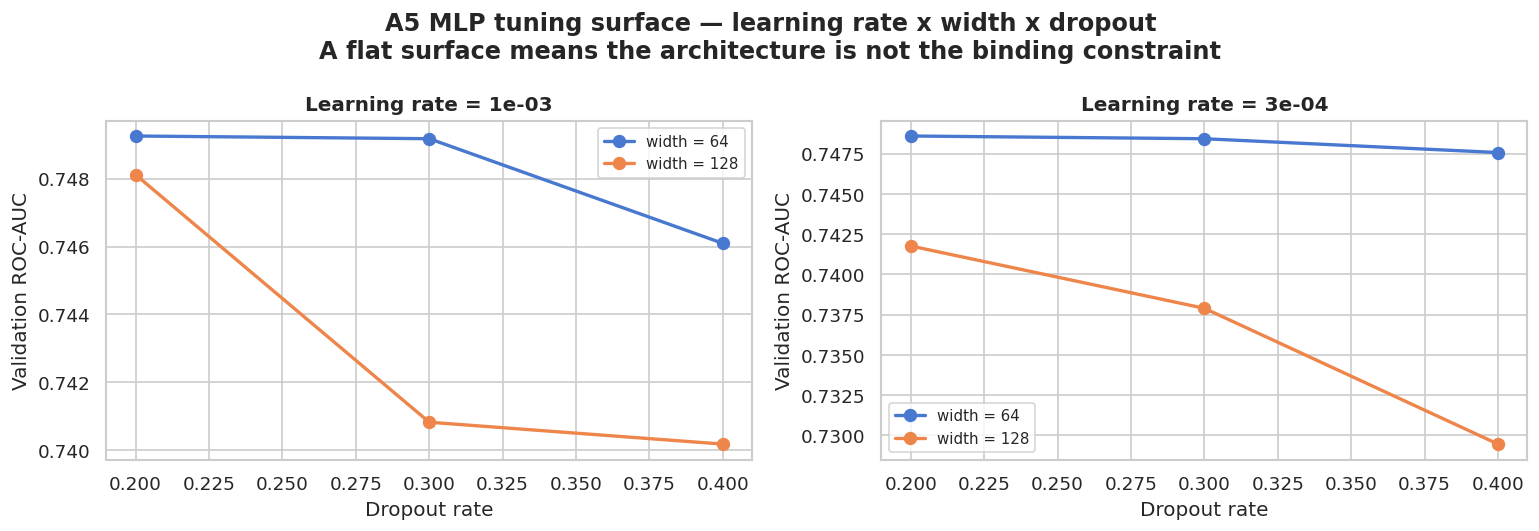

In [ ]:
# A5 Step 2 — Lightly tune the MLP without touching the sealed test set
# Tune on an internal training split; keep the sealed test set untouched.

tune_tr_idx, tune_va_idx = train_test_split(
    np.arange(len(X_tr_sel)), test_size=0.15,
    stratify=y_tr, random_state=RANDOM_STATE)

prep_tune = clone(prep_sel).fit(X_tr_sel.iloc[tune_tr_idx], y_tr.iloc[tune_tr_idx])
X_tune_tr = prep_tune.transform(X_tr_sel.iloc[tune_tr_idx]).astype('float32')
X_tune_va = prep_tune.transform(X_tr_sel.iloc[tune_va_idx]).astype('float32')
y_tune_tr = y_tr.values[tune_tr_idx].astype('float32')
y_tune_va = y_tr.values[tune_va_idx].astype('float32')

GRID = [(lr, w, dr)
        for lr in (1e-3, 3e-4)
        for w  in (64, 128)
        for dr in (0.2, 0.3, 0.4)]

print(f'=== A5 MLP LIGHT TUNING — {len(GRID)} configurations on one 85/15 holdout ===')
print(f'{"LR":>8} {"Width":>7} {"Dropout":>9} {"Val ROC-AUC":>13} {"Epochs":>8}')
print('-' * 50)

tune_rows = []
for lr, w, dr in GRID:
    _, hist, vprob = train_keras(
        X_tune_tr, y_tune_tr, X_tune_va, y_tune_va,
        lr=lr, width=w, dropout=dr, epochs=60, verbose=0)
    auc = roc_auc_score(y_tune_va, vprob)
    tune_rows.append({'lr': lr, 'width': w, 'dropout': dr,
                      'val_auc': auc, 'epochs': len(hist['loss'])})
    print(f'{lr:>8.0e} {w:>7} {dr:>9.1f} {auc:>13.4f} {len(hist["loss"]):>8}')

tune_df = pd.DataFrame(tune_rows).sort_values('val_auc', ascending=False).reset_index(drop=True)

BEST_LR = float(tune_df.iloc[0]['lr'])
BEST_WIDTH = int(tune_df.iloc[0]['width'])
BEST_DROPOUT = float(tune_df.iloc[0]['dropout'])

print()
print(f'Best configuration: lr={BEST_LR:.0e}, width={BEST_WIDTH}, dropout={BEST_DROPOUT:.1f}')
print(f'Spread across the grid: {tune_df["val_auc"].max() - tune_df["val_auc"].min():.4f} AUC')
print()
print('INTERPRETATION: if the spread is under ~0.01 the MLP is insensitive to these')
print('choices on this data, which is itself worth reporting -- it means the ceiling')
print('is set by the features, not by the architecture. Configurations that stop after')
print('very few epochs are diverging; those that run to the epoch cap may be')
print('under-trained rather than optimal.')

# Visualise the tuning surface
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, lr_val in zip(axes, sorted(tune_df['lr'].unique(), reverse=True)):
    sub = tune_df[tune_df['lr'] == lr_val]
    for w_val, colr in zip(sorted(sub['width'].unique()), [BLUE, ORANGE]):
        s = sub[sub['width'] == w_val].sort_values('dropout')
        ax.plot(s['dropout'], s['val_auc'], 'o-', color=colr, lw=2, ms=7,
                label=f'width = {w_val}')
    ax.set_title(f'Learning rate = {lr_val:.0e}', fontweight='bold')
    ax.set_xlabel('Dropout rate')
    ax.set_ylabel('Validation ROC-AUC')
    ax.legend(fontsize=9)

plt.suptitle('A5 MLP tuning surface — learning rate x width x dropout\n'
             'A flat surface means the architecture is not the binding constraint',
             fontweight='bold')
plt.tight_layout()
plt.savefig('/content/a5_mlp_tuning.png', dpi=300, bbox_inches='tight')
plt.show()


**Output explanation.** The best tested MLP setting is **learning rate 0.001, width 64 and dropout 0.2**, with validation ROC-AUC **0.7493**. Results vary by about **0.0198 AUC** across the tested settings, so the network is affected by these choices. The selected setting is used for the shared cross-validation comparison.

### A5 Step 3 — Cross-validate Keras and PyTorch on the same folds

=== A5.3 MLP 5-FOLD CROSS-VALIDATION (shared cv5 folds) ===
Configuration: lr=1e-03, width=64, dropout=0.2

Fold     Keras AUC   PyTorch AUC   Difference     Time
------------------------------------------------------
1           0.7516        0.7513       0.0003      65s
2           0.7505        0.7507       0.0001      54s
3           0.7555        0.7565       0.0010      46s
4           0.7516        0.7502       0.0014      55s
5           0.7524        0.7527       0.0003      67s
------------------------------------------------------
Mean        0.7523        0.7523       0.0001     290s

=== FRAMEWORK CONSISTENCY ===
  Mean |difference| across folds: 0.0006
  Wilcoxon signed-rank across the 5 paired folds: p = 1.0000

  PRACTICAL AGREEMENT: mean absolute AUC difference is under 0.005.
  The two framework implementations give closely aligned discrimination.

  The Wilcoxon test checks for paired differences; a non-significant result
  alone does not prove statistical equivalenc

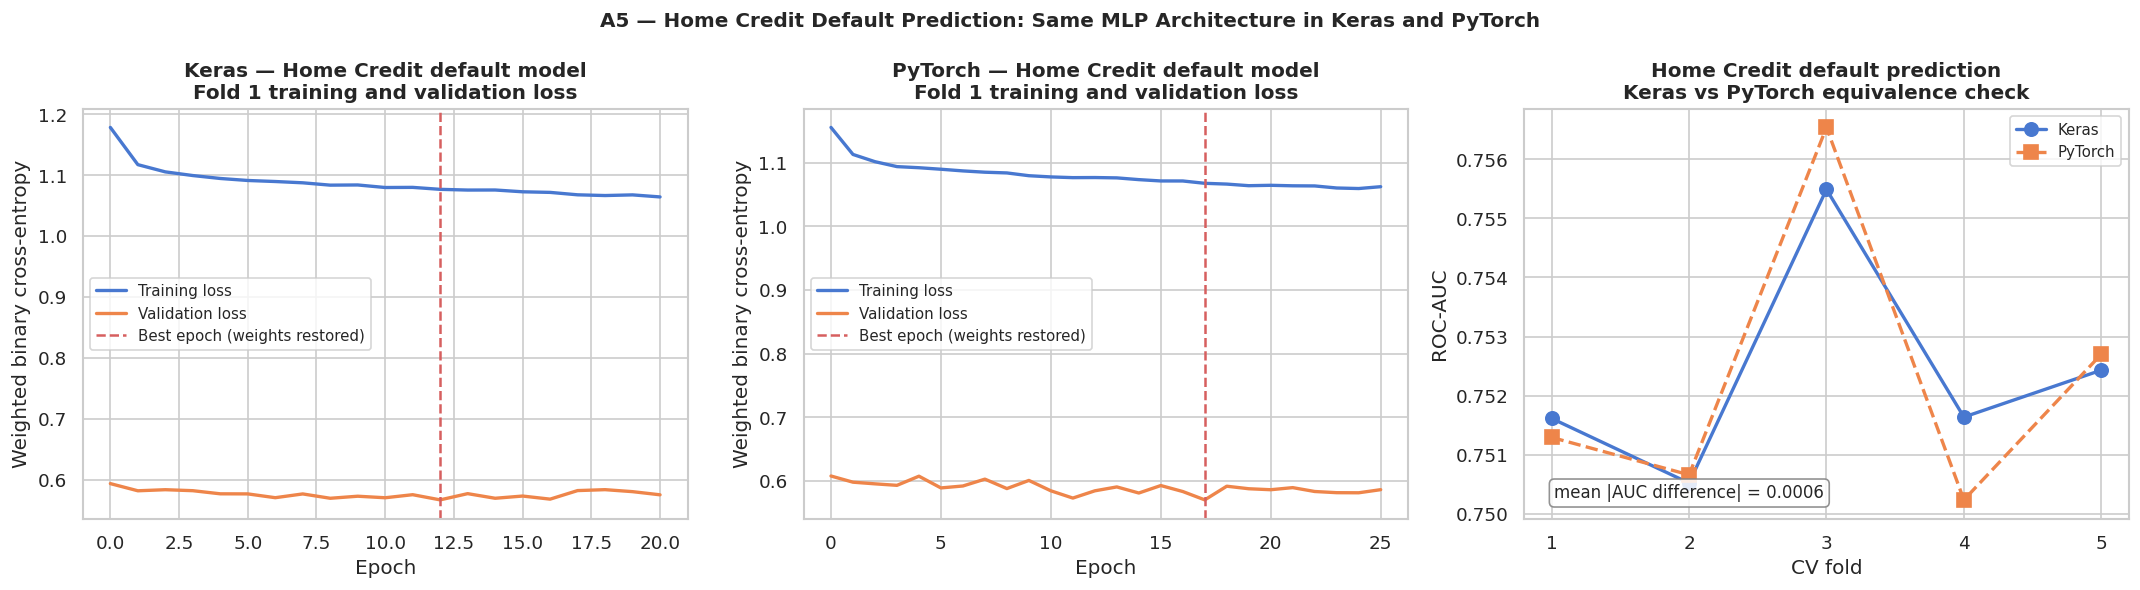

=== HOME CREDIT — EPOCHS TRAINED PER FOLD (EarlyStopping) ===
Fold      Keras    PyTorch
--------------------------
1            21         26
2            16         27
3            19         14
4            28         14
5            31         26

If one framework consistently trains for substantially more epochs than the other,
its effective optimisation or regularisation behaviour may differ despite using the same MLP architecture.

Fitting final Home Credit neural-network models for use in A6 and A7...
  Internal NN training rows:  209,106
  EarlyStopping validation:   36,902
  Total development rows:     246,008
  Neural-network input width: 98 features
  X_te_nn prepared:           (61503, 98)
  Sealed test targets have NOT been used — final scoring is deferred until A6.


In [ ]:
keras_fold_auc, torch_fold_auc = [], []
keras_fold_pr,  torch_fold_pr  = [], []
keras_fold_rec, torch_fold_rec = [], []
keras_fold_br,  torch_fold_br  = [], []

keras_histories, torch_histories = [], []


# Out-of-fold probabilities for later calibration analysis.
# Fit preprocessing on inner-training rows only so outer-fold predictions remain leakage-free.

oof_keras = np.zeros(
    len(X_tr_sel),
    dtype=np.float32
)

oof_torch = np.zeros(
    len(X_tr_sel),
    dtype=np.float32
)


print(
    '=== A5.3 MLP 5-FOLD CROSS-VALIDATION '
    '(shared cv5 folds) ==='
)

print(
    f'Configuration: '
    f'lr={BEST_LR:.0e}, '
    f'width={BEST_WIDTH}, '
    f'dropout={BEST_DROPOUT}'
)

print()

print(
    f'{"Fold":<6} '
    f'{"Keras AUC":>11} '
    f'{"PyTorch AUC":>13} '
    f'{"Difference":>12} '
    f'{"Time":>8}'
)

print('-' * 54)


t_start = time.time()


for fold, (tr_idx, va_idx) in enumerate(
    cv5.split(
        X_tr_sel,
        y_tr
    ),
    start=1
):

    t0 = time.time()


    # Inner split from OUTER-fold training rows

    in_tr_pos, in_va_pos = train_test_split(
        np.arange(
            len(tr_idx)
        ),
        test_size=0.15,
        stratify=y_tr.iloc[
            tr_idx
        ],
        random_state=RANDOM_STATE
    )


    in_tr_idx = tr_idx[
        in_tr_pos
    ]

    in_va_idx = tr_idx[
        in_va_pos
    ]


    # Fit preprocessing on INNER-TRAINING rows only

    prep_f = clone(
        prep_sel
    ).fit(
        X_tr_sel.iloc[
            in_tr_idx
        ],
        y_tr.iloc[
            in_tr_idx
        ]
    )


    Xf_tr = prep_f.transform(
        X_tr_sel.iloc[
            in_tr_idx
        ]
    ).astype(
        'float32'
    )


    Xf_inva = prep_f.transform(
        X_tr_sel.iloc[
            in_va_idx
        ]
    ).astype(
        'float32'
    )


    Xf_va = prep_f.transform(
        X_tr_sel.iloc[
            va_idx
        ]
    ).astype(
        'float32'
    )


    yf_tr = y_tr.iloc[
        in_tr_idx
    ].values.astype(
        'float32'
    )


    yf_inva = y_tr.iloc[
        in_va_idx
    ].values.astype(
        'float32'
    )


    yf_va = y_tr.iloc[
        va_idx
    ].values.astype(
        'float32'
    )


    # Keras

    tf.keras.backend.clear_session()


    k_model, k_hist, _ = train_keras(
        Xf_tr,
        yf_tr,
        Xf_inva,
        yf_inva,
        lr=BEST_LR,
        width=BEST_WIDTH,
        dropout=BEST_DROPOUT,
        epochs=80,
        verbose=0
    )


    k_prob = (
        k_model.predict(
            Xf_va,
            verbose=0
        )
        .ravel()
    )


    # PyTorch — SAME training and validation data

    t_model, t_hist, _ = train_pytorch(
        Xf_tr,
        yf_tr,
        Xf_inva,
        yf_inva,
        lr=BEST_LR,
        width=BEST_WIDTH,
        dropout=BEST_DROPOUT,
        epochs=80,
        verbose=False
    )


    torch_model_device = next(
        t_model.parameters()
    ).device


    Xf_va_t = torch.as_tensor(
        Xf_va,
        dtype=torch.float32,
        device=torch_model_device
    )


    t_model.eval()


    with torch.no_grad():

        t_prob = (
            t_model(
                Xf_va_t
            )
            .detach()
            .cpu()
            .numpy()
            .ravel()
        )


    assert len(k_prob) == len(yf_va), (
        'Keras prediction length does not match validation rows.'
    )

    assert len(t_prob) == len(yf_va), (
        'PyTorch prediction length does not match validation rows.'
    )

    assert np.isfinite(
        k_prob
    ).all(), (
        'Keras produced NaN or infinite probabilities.'
    )

    assert np.isfinite(
        t_prob
    ).all(), (
        'PyTorch produced NaN or infinite probabilities.'
    )


    for probs, auc_l, pr_l, rec_l, br_l, oof in [

        (
            k_prob,
            keras_fold_auc,
            keras_fold_pr,
            keras_fold_rec,
            keras_fold_br,
            oof_keras
        ),

        (
            t_prob,
            torch_fold_auc,
            torch_fold_pr,
            torch_fold_rec,
            torch_fold_br,
            oof_torch
        )
    ]:


        auc_l.append(
            roc_auc_score(
                yf_va,
                probs
            )
        )


        pr_l.append(
            average_precision_score(
                yf_va,
                probs
            )
        )


        rec_l.append(
            recall_score(
                yf_va,
                (
                    probs >= 0.5
                ).astype(int),
                zero_division=0
            )
        )


        br_l.append(
            brier_score_loss(
                yf_va,
                probs
            )
        )


        oof[
            va_idx
        ] = probs


    keras_histories.append(
        k_hist
    )

    torch_histories.append(
        t_hist
    )


    print(
        f'{fold:<6} '
        f'{keras_fold_auc[-1]:>11.4f} '
        f'{torch_fold_auc[-1]:>13.4f} '
        f'{abs(keras_fold_auc[-1] - torch_fold_auc[-1]):>12.4f} '
        f'{time.time() - t0:>7.0f}s'
    )


    del Xf_va_t
    del k_model
    del t_model


    tf.keras.backend.clear_session()


    if torch.cuda.is_available():
        torch.cuda.empty_cache()


keras_fold_auc = np.array(
    keras_fold_auc
)

torch_fold_auc = np.array(
    torch_fold_auc
)


print('-' * 54)


print(
    f'{"Mean":<6} '
    f'{keras_fold_auc.mean():>11.4f} '
    f'{torch_fold_auc.mean():>13.4f} '
    f'{abs(keras_fold_auc.mean() - torch_fold_auc.mean()):>12.4f} '
    f'{time.time() - t_start:>7.0f}s'
)

print()


fold_scores[
    'MLP Keras (tuned)'
] = keras_fold_auc


fold_scores[
    'MLP PyTorch (tuned)'
] = torch_fold_auc


leaderboard.append({

    'Model':
        'MLP Keras (tuned)',

    'Stage':
        'A5',

    'ROC_AUC':
        keras_fold_auc.mean(),

    'ROC_AUC_std':
        keras_fold_auc.std(),

    'PR_AUC':
        np.mean(
            keras_fold_pr
        ),

    'Recall':
        np.mean(
            keras_fold_rec
        ),

    'Brier':
        np.mean(
            keras_fold_br
        ),

    'Fit_s':
        np.nan
})


leaderboard.append({

    'Model':
        'MLP PyTorch (tuned)',

    'Stage':
        'A5',

    'ROC_AUC':
        torch_fold_auc.mean(),

    'ROC_AUC_std':
        torch_fold_auc.std(),

    'PR_AUC':
        np.mean(
            torch_fold_pr
        ),

    'Recall':
        np.mean(
            torch_fold_rec
        ),

    'Brier':
        np.mean(
            torch_fold_br
        ),

    'Fit_s':
        np.nan
})


framework_diff = (
    keras_fold_auc
    -
    torch_fold_auc
)


mean_abs_diff = np.abs(
    framework_diff
).mean()


if np.allclose(
    framework_diff,
    0
):

    w_stat = 0.0
    w_p = 1.0

else:

    w_stat, w_p = stats.wilcoxon(
        keras_fold_auc,
        torch_fold_auc,
        alternative='two-sided'
    )


print(
    '=== FRAMEWORK CONSISTENCY ==='
)


print(
    f'  Mean |difference| across folds: '
    f'{mean_abs_diff:.4f}'
)


print(
    f'  Wilcoxon signed-rank across the '
    f'5 paired folds: p = {w_p:.4f}'
)


print()


if mean_abs_diff < 0.005:

    print(
        '  PRACTICAL AGREEMENT: mean absolute AUC difference '
        'is under 0.005.'
    )

    print(
        '  The two framework implementations give closely '
        'aligned discrimination.'
    )


else:

    print(
        '  DIFFERENCE ABOVE 0.005: inspect the framework '
        'implementations and'
    )

    print(
        '  training histories before describing their '
        'performance as closely aligned.'
    )


print()


print(
    '  The Wilcoxon test checks for paired differences; '
    'a non-significant result'
)

print(
    '  alone does not prove statistical equivalence.'
)

print()


print(
    '  NOTE for A6: only the Keras MLP enters the main '
    'model-comparison tests.'
)

print(
    '  The PyTorch implementation remains on the leaderboard '
    'as framework'
)

print(
    '  replication evidence rather than a separate model family.'
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)


kh = keras_histories[0]

axes[0].plot(
    kh['loss'],
    color=BLUE,
    lw=2,
    label='Training loss'
)

axes[0].plot(
    kh['val_loss'],
    color=ORANGE,
    lw=2,
    label='Validation loss'
)

axes[0].axvline(
    int(np.argmin(kh['val_loss'])),
    color=RED,
    ls='--',
    lw=1.5,
    label='Best epoch (weights restored)'
)

axes[0].set_xlabel('Epoch')

axes[0].set_ylabel(
    'Weighted binary cross-entropy'
)

axes[0].set_title(
    'Keras — Home Credit default model\n'
    'Fold 1 training and validation loss',
    fontweight='bold'
)

axes[0].legend(fontsize=9)


th = torch_histories[0]

axes[1].plot(
    th['loss'],
    color=BLUE,
    lw=2,
    label='Training loss'
)

axes[1].plot(
    th['val_loss'],
    color=ORANGE,
    lw=2,
    label='Validation loss'
)

axes[1].axvline(
    int(np.argmin(th['val_loss'])),
    color=RED,
    ls='--',
    lw=1.5,
    label='Best epoch (weights restored)'
)

axes[1].set_xlabel('Epoch')

axes[1].set_ylabel(
    'Weighted binary cross-entropy'
)

axes[1].set_title(
    'PyTorch — Home Credit default model\n'
    'Fold 1 training and validation loss',
    fontweight='bold'
)

axes[1].legend(fontsize=9)


folds = np.arange(
    1,
    len(keras_fold_auc) + 1
)

axes[2].plot(
    folds,
    keras_fold_auc,
    'o-',
    color=BLUE,
    lw=2,
    ms=8,
    label='Keras'
)

axes[2].plot(
    folds,
    torch_fold_auc,
    's--',
    color=ORANGE,
    lw=2,
    ms=8,
    label='PyTorch'
)

axes[2].set_xticks(folds)

axes[2].set_xlabel(
    'CV fold'
)

axes[2].set_ylabel(
    'ROC-AUC'
)

axes[2].set_title(
    'Home Credit default prediction\n'
    'Keras vs PyTorch equivalence check',
    fontweight='bold'
)

axes[2].legend(fontsize=9)


mean_auc_diff = np.abs(
    np.asarray(keras_fold_auc)
    -
    np.asarray(torch_fold_auc)
).mean()

axes[2].annotate(
    f'mean |AUC difference| = {mean_auc_diff:.4f}',
    xy=(0.05, 0.05),
    xycoords='axes fraction',
    fontsize=10,
    bbox=dict(
        boxstyle='round',
        fc='white',
        ec='grey',
        alpha=0.85
    )
)


plt.suptitle(
    'A5 — Home Credit Default Prediction: '
    'Same MLP Architecture in Keras and PyTorch',
    fontweight='bold',
    fontsize=12
)

plt.tight_layout()

plt.savefig(
    '/content/a5_home_credit_mlp_curves.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


print(
    '=== HOME CREDIT — EPOCHS TRAINED PER FOLD '
    '(EarlyStopping) ==='
)

print(
    f'{"Fold":<6} '
    f'{"Keras":>8} '
    f'{"PyTorch":>10}'
)

print('-' * 26)


for i, (k, t) in enumerate(
    zip(
        keras_histories,
        torch_histories
    ),
    start=1
):

    print(
        f'{i:<6} '
        f'{len(k["loss"]):>8} '
        f'{len(t["loss"]):>10}'
    )


print()

print(
    'If one framework consistently trains for substantially more epochs '
    'than the other,'
)

print(
    'its effective optimisation or regularisation behaviour may differ '
    'despite using the same MLP architecture.'
)


print()

print(
    'Fitting final Home Credit neural-network models '
    'for use in A6 and A7...'
)


fin_tr, fin_va = train_test_split(

    np.arange(len(X_tr_sel)),

    test_size=0.15,

    stratify=y_tr,

    random_state=RANDOM_STATE
)


X_fin_tr = X_tr_sel.iloc[fin_tr]

X_fin_va = X_tr_sel.iloc[fin_va]

y_fin_tr = y_tr.iloc[fin_tr].values.astype(
    'float32'
)

y_fin_va = y_tr.iloc[fin_va].values.astype(
    'float32'
)


prep_nn_final = clone(
    prep_sel
).fit(
    X_fin_tr,
    y_tr.iloc[fin_tr]
)


X_fin_tr_nn = prep_nn_final.transform(
    X_fin_tr
).astype(
    'float32'
)

X_fin_va_nn = prep_nn_final.transform(
    X_fin_va
).astype(
    'float32'
)


X_te_nn = prep_nn_final.transform(
    X_te_sel
).astype(
    'float32'
)


keras_final, keras_final_history, _ = train_keras(

    X_fin_tr_nn,
    y_fin_tr,

    X_fin_va_nn,
    y_fin_va,

    lr=BEST_LR,

    width=BEST_WIDTH,

    dropout=BEST_DROPOUT,

    epochs=80,

    verbose=0
)


torch_final, torch_final_history, _ = train_pytorch(

    X_fin_tr_nn,
    y_fin_tr,

    X_fin_va_nn,
    y_fin_va,

    lr=BEST_LR,

    width=BEST_WIDTH,

    dropout=BEST_DROPOUT,

    epochs=80
)


print(
    f'  Internal NN training rows:  '
    f'{len(fin_tr):,}'
)

print(
    f'  EarlyStopping validation:   '
    f'{len(fin_va):,}'
)

print(
    f'  Total development rows:     '
    f'{len(X_tr_sel):,}'
)

print(
    f'  Neural-network input width: '
    f'{X_fin_tr_nn.shape[1]} features'
)

print(
    f'  X_te_nn prepared:           '
    f'{X_te_nn.shape}'
)

print(
    '  Sealed test targets have NOT been used — '
    'final scoring is deferred until A6.'
)


**Output explanation.** Keras and PyTorch both achieve a mean ROC-AUC of about **0.7523** across the same five folds. Their mean absolute fold difference is only **0.0006**, and the paired Wilcoxon test gives **p = 1.0000**. This shows very similar results from the two implementations, although it does not prove that they are exactly equivalent.

### A5 Step 4 — Compare Keras and PyTorch

Keras needs less code for this standard MLP, while PyTorch gives more control over the training loop. Their measured performance is compared first; implementation style is a secondary point.

### A5 wrap-up

The MLP performs well but remains below the two strongest boosting models. The close Keras and PyTorch results also show that the neural result is not mainly caused by the choice of framework.

---
# A6 — Model Evaluation

A6 compares all tuned models, checks statistical differences and probability calibration, reviews subgroup results, tests SMOTENC, and selects a cost-based decision threshold using development evidence only.

### A6 Step 1 — Build one cross-validated leaderboard

=== UNIFIED LEADERBOARD — TUNED MODELS (5-fold CV, shared outer folds) ===

#    Model                                   ROC-AUC    PR-AUC   Recall     Brier
----------------------------------------------------------------------------------
1    LightGBM (tuned)                 0.7621 +/- 0.002    0.2485   0.6716    0.1870
2    XGBoost (tuned)                  0.7618 +/- 0.002    0.2475   0.6667    0.1855
3    MLP Keras (tuned)                0.7523 +/- 0.002    0.2338   0.6749    0.1909
4    MLP PyTorch (tuned)              0.7523 +/- 0.002    0.2329   0.6824    0.1948
5    Random Forest (tuned)            0.7487 +/- 0.002    0.2264   0.6157    0.1871
6    SVM (linear, tuned)              0.7466 +/- 0.003    0.2226   0.0114    0.0687
7    Logistic Regression (tuned)      0.7466 +/- 0.003    0.2224   0.6770    0.2037
8    k-NN (tuned)                     0.7263 +/- 0.002    0.2066   0.0007    0.0694
9    Naive Bayes (tuned)              0.6384 +/- 0.003    0.1225   0.6044    0.3241
---

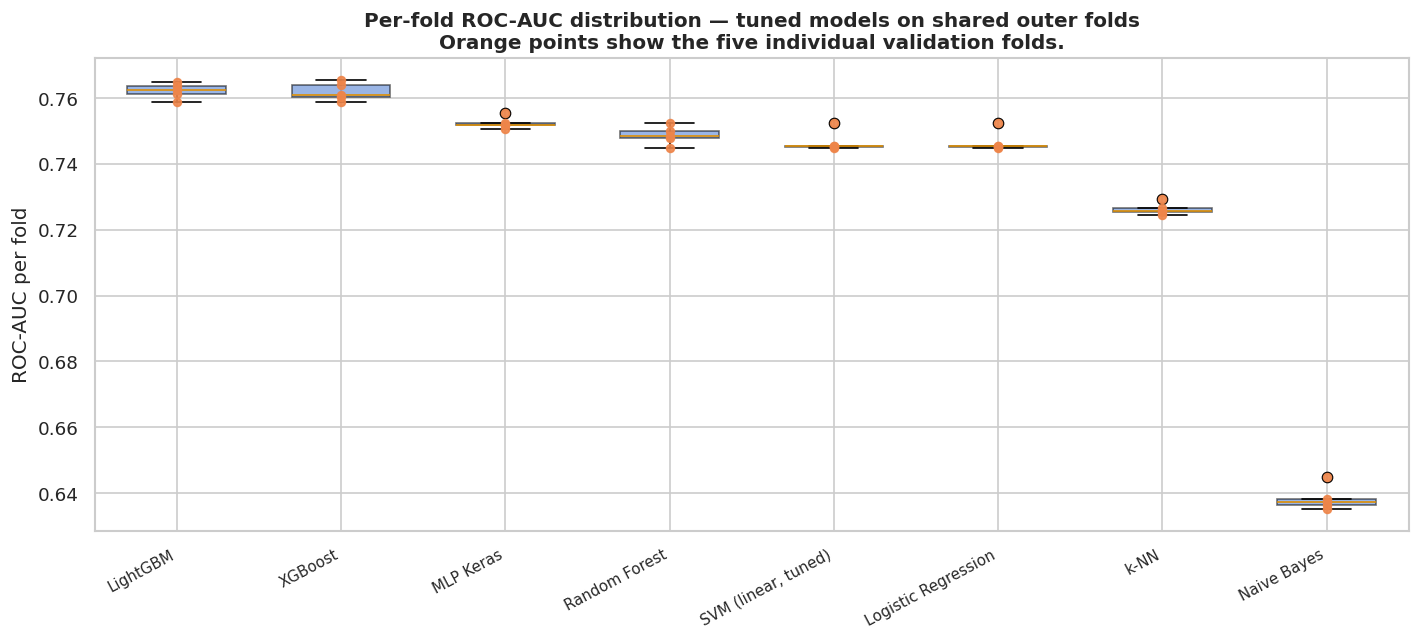


The plot complements the statistical tests by showing the magnitude,
stability and consistency of the model differences across the five folds.
Look at both the separation between distributions and whether the leading
model remains ahead consistently across the individual folds.


In [ ]:
# A6 Step 1 — Build the unified cross-validated leaderboard
# Use one representative per model family in the formal rank test.

lb = pd.DataFrame(leaderboard)


STAT_MODELS = [
    'Logistic Regression (tuned)',
    'SVM (linear, tuned)',
    'k-NN (tuned)',
    'Naive Bayes (tuned)',
    'Random Forest (tuned)',
    'XGBoost (tuned)',
    'LightGBM (tuned)',
    'MLP Keras (tuned)'
]

STAT_MODELS = [
    m for m in STAT_MODELS
    if m in fold_scores
]


lb_tuned = (
    lb[
        lb['Model'].isin(
            STAT_MODELS + ['MLP PyTorch (tuned)']
        )
    ]
    .drop_duplicates(
        subset='Model',
        keep='last'
    )
    .sort_values(
        'ROC_AUC',
        ascending=False
    )
    .reset_index(drop=True)
)

lb_tuned.insert(
    0,
    'Rank',
    lb_tuned.index + 1
)


print('=== UNIFIED LEADERBOARD — TUNED MODELS (5-fold CV, shared outer folds) ===')

print()

print(
    f'{"#":<4} {"Model":<28} {"ROC-AUC":>18} '
    f'{"PR-AUC":>9} {"Recall":>8} {"Brier":>9}'
)

print('-' * 82)


for _, r in lb_tuned.iterrows():

    print(
        f'{int(r.Rank):<4} '
        f'{r.Model:<28} '
        f'{r.ROC_AUC:>10.4f} +/- {r.ROC_AUC_std:.3f}'
        f' {r.PR_AUC:>9.4f}'
        f' {r.Recall:>8.4f}'
        f' {r.Brier:>9.4f}'
    )


print('-' * 82)

print(
    f'{"":<4} '
    f'{"PR-AUC baseline (= positive rate)":<28} '
    f'{"":>18} '
    f'{y_tr.mean():>9.4f}'
)

print()


print('Reading the columns:')

print(
    '  ROC-AUC : ranking discrimination across decision thresholds'
)

print(
    '  PR-AUC  : performance focused on the minority default class; compare'
)

print(
    '            against the positive-rate baseline shown above'
)

print(
    '  Recall  : share of true defaulters identified at threshold 0.5'
)

print(
    '            (A6.6 revisits the operating threshold)'
)

print(
    '  Brier   : probability accuracy combining calibration and discrimination;'
)

print(
    '            LOWER is better'
)

print()


BEST_MODEL_NAME = (
    lb_tuned[
        lb_tuned['Model'].isin(STAT_MODELS)
    ]
    .iloc[0]['Model']
)

print(
    f'Best model by ROC-AUC: {BEST_MODEL_NAME}'
)


# Per-fold box plot — visual comparison of CV stability and separation

scores_list = [
    fold_scores[m]
    for m in STAT_MODELS
]

labels_short = [
    m.replace(' (tuned)', '')
    for m in STAT_MODELS
]

order = np.argsort(
    [s.mean() for s in scores_list]
)[::-1]


fig, ax = plt.subplots(
    figsize=(12, 5.5)
)


bp = ax.boxplot(
    [scores_list[i] for i in order],
    patch_artist=True,
    widths=0.6
)


for patch in bp['boxes']:
    patch.set_facecolor(BLUE)
    patch.set_alpha(0.55)


ax.set_xticks(
    np.arange(1, len(order) + 1)
)

ax.set_xticklabels(
    [labels_short[i] for i in order]
)


for i, idx in enumerate(order, start=1):

    ax.scatter(
        [i] * len(scores_list[idx]),
        scores_list[idx],
        color=ORANGE,
        s=22,
        zorder=3,
        alpha=0.9
    )


ax.set_ylabel(
    'ROC-AUC per fold'
)

ax.set_xlabel(
    ''
)

plt.setp(
    ax.get_xticklabels(),
    rotation=28,
    ha='right',
    fontsize=9
)


ax.set_title(
    'Per-fold ROC-AUC distribution — tuned models on shared outer folds\n'
    'Orange points show the five individual validation folds.',
    fontweight='bold'
)


plt.tight_layout()

plt.savefig(
    '/content/a6_leaderboard_boxplot.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


print()

print(
    'The plot complements the statistical tests by showing the magnitude,'
)

print(
    'stability and consistency of the model differences across the five folds.'
)

print(
    'Look at both the separation between distributions and whether the leading'
)

print(
    'model remains ahead consistently across the individual folds.'
)


**Output explanation.** LightGBM ranks first on the shared leaderboard with **ROC-AUC 0.7621** and **PR-AUC 0.2485**, with XGBoost very close at **0.7618** and **0.2475**. Both are well above the **0.0807 PR-AUC baseline**. Recall is shown at the default 0.5 threshold, while Brier score measures probability accuracy and is better when lower.

### A6 Step 2 — Run the overall Friedman test and paired Wilcoxon tests

First test whether there is an overall difference across models. Then inspect paired model comparisons while correcting for the large number of comparisons.

=== FRIEDMAN OMNIBUS TEST ===
  Models (k):  8
  Folds  (N):  5
  chi-squared: 33.0000   df = 7   p = 0.00003

  -> REJECT H0: evidence that at least one model differs.
     Pairwise Wilcoxon comparisons are examined below.

=== PAIRWISE WILCOXON SIGNED-RANK (Bonferroni corrected) ===
  Comparisons:            28
  Bonferroni alpha:       0.05 / 28 = 0.00179
  Best-case minimum exact p with N = 5: 0.0625

  NOTE: 0.0625 > 0.00179. With only 5 paired folds,
  Bonferroni-corrected pairwise significance cannot be reached under
  this best-case exact Wilcoxon resolution.
  Therefore effect size, direction and fold consistency must also be shown.

Model A                Model B                 Mean diff   A wins         p   Verdict
------------------------------------------------------------------------------------
Naive Bayes            LightGBM                  -0.1237    0/5      0.0625      n.s.
Naive Bayes            XGBoost                   -0.1234    0/5      0.0625      n.s.
Naive 

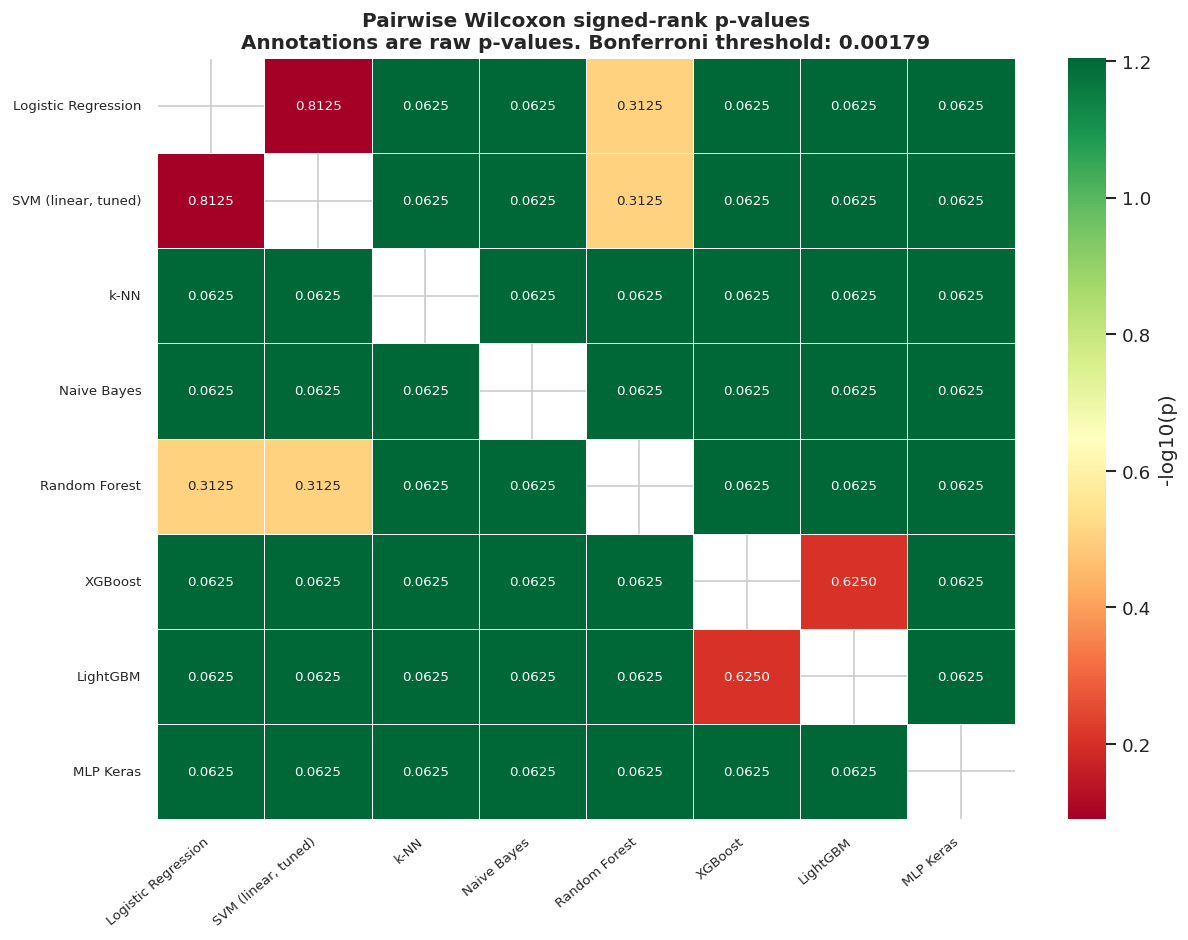

In [ ]:
# A6 Step 2 — Friedman omnibus test and paired Wilcoxon comparisons
# Use Friedman first, then paired Wilcoxon tests with Bonferroni correction.

score_arrays = [np.asarray(fold_scores[m]) for m in STAT_MODELS]
model_labels = [m.replace(' (tuned)', '') for m in STAT_MODELS]

k = len(score_arrays)
N = len(score_arrays[0])

assert k >= 3, 'Friedman test requires at least three models.'
assert all(len(s) == N for s in score_arrays), (
    'All models must have scores from the same number of outer folds.'
)

chi2_f, p_f = stats.friedmanchisquare(*score_arrays)

print('=== FRIEDMAN OMNIBUS TEST ===')
print(f'  Models (k):  {k}')
print(f'  Folds  (N):  {N}')
print(f'  chi-squared: {chi2_f:.4f}   df = {k - 1}   p = {p_f:.5f}')
print()

if p_f < 0.05:
    print('  -> REJECT H0: evidence that at least one model differs.')
    print('     Pairwise Wilcoxon comparisons are examined below.')
else:
    print('  -> FAIL TO REJECT H0 at alpha = 0.05.')
    print('     With only five outer folds, statistical power is limited, so this')
    print('     should not be interpreted as evidence that the models are equivalent.')

print()


# Pairwise Wilcoxon signed-rank with Bonferroni correction

pairs = list(combinations(range(k), 2))
alpha_corr = 0.05 / len(pairs)

p_floor = 2 / (2 ** N)

print('=== PAIRWISE WILCOXON SIGNED-RANK (Bonferroni corrected) ===')
print(f'  Comparisons:            {len(pairs)}')
print(f'  Bonferroni alpha:       0.05 / {len(pairs)} = {alpha_corr:.5f}')
print(f'  Best-case minimum exact p with N = {N}: {p_floor:.4f}')
print()

if p_floor > alpha_corr:
    print(f'  NOTE: {p_floor:.4f} > {alpha_corr:.5f}. With only {N} paired folds,')
    print('  Bonferroni-corrected pairwise significance cannot be reached under')
    print('  this best-case exact Wilcoxon resolution.')
    print('  Therefore effect size, direction and fold consistency must also be shown.')

print()


pval_matrix = pd.DataFrame(
    np.ones((k, k)),
    index=model_labels,
    columns=model_labels
)

rows = []


for i, j in pairs:

    a = score_arrays[i]
    b = score_arrays[j]

    if np.allclose(a, b):

        p = 1.0

    else:

        try:
            _, p = stats.wilcoxon(
                a,
                b,
                alternative='two-sided'
            )

        except ValueError:
            p = 1.0


    pval_matrix.iloc[i, j] = p
    pval_matrix.iloc[j, i] = p

    wins = int(
        (a > b).sum()
    )

    rows.append({
        'A': model_labels[i],
        'B': model_labels[j],
        'mean_diff': a.mean() - b.mean(),
        'A_wins': wins,
        'p': p,
        'sig': 'SIG' if (p_f < 0.05 and p < alpha_corr) else 'n.s.'
    })


pw = (
    pd.DataFrame(rows)
    .sort_values(
        'mean_diff',
        key=abs,
        ascending=False
    )
)


print(
    f'{"Model A":<22} {"Model B":<22} '
    f'{"Mean diff":>10} {"A wins":>8} {"p":>9} {"Verdict":>9}'
)

print('-' * 84)


for _, r in pw.iterrows():

    print(
        f'{r.A:<22} '
        f'{r.B:<22} '
        f'{r.mean_diff:>+10.4f} '
        f'{r.A_wins:>4}/{N:<3}'
        f' {r.p:>9.4f} '
        f'{r.sig:>9}'
    )


print()

if p_f >= 0.05:
    print('Because the Friedman omnibus test did not reject H0, the pairwise results')
    print('above should be treated as descriptive/exploratory rather than confirmatory.')
    print()

print('The "A wins" column adds practical context to the p-values. A 5/5 result')
print('shows that Model A had the higher ROC-AUC on every shared outer fold, while')
print('the mean difference shows the magnitude of that advantage. It does not, by')
print('itself, establish statistical significance.')

print()


# p-value heatmap

fig, ax = plt.subplots(
    figsize=(10.5, 8)
)

mask = np.eye(
    k,
    dtype=bool
)

sns.heatmap(
    -np.log10(pval_matrix.values.astype(float) + 1e-12),
    annot=pval_matrix.round(4),
    fmt='.4f',
    cmap='RdYlGn',
    mask=mask,
    xticklabels=model_labels,
    yticklabels=model_labels,
    linewidths=0.5,
    annot_kws={'size': 8},
    cbar_kws={'label': '-log10(p)'},
    ax=ax
)

ax.set_title(
    'Pairwise Wilcoxon signed-rank p-values\n'
    f'Annotations are raw p-values. Bonferroni threshold: {alpha_corr:.5f}',
    fontweight='bold'
)

plt.xticks(
    rotation=40,
    ha='right',
    fontsize=8
)

plt.yticks(
    rotation=0,
    fontsize=8
)

plt.tight_layout()

plt.savefig(
    '/content/a6_wilcoxon_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


**Output explanation.** The Friedman test gives **p = 0.00003**, so the models are not all performing the same across the five folds. However, with only five paired folds, the smallest possible exact Wilcoxon p-value is **0.0625**, which is still above the Bonferroni limit of **0.00179**. This means the individual model pairs cannot be called statistically significant under this strict test, so the size and consistency of the differences must also be considered.

### A6 Step 3 — Compare model ranks with a critical-difference chart

Use the shared fold ranks as an additional view of how consistently the models perform.

=== CRITICAL DIFFERENCE DIAGRAM (Nemenyi, alpha = 0.05) ===
  k = 8 models, N = 5 shared outer folds, q_alpha = 3.031
  CD = 3.031 * sqrt(8*9 / (6*5)) = 4.6956 rank positions
  Rank span across all models: 6.60

  Average ranks (1 = best):
    LightGBM                 1.40
    XGBoost                  1.60
    MLP Keras                3.00
    Random Forest            4.80
    SVM (linear, tuned)      5.00
    Logistic Regression      5.20
    k-NN                     7.00
    Naive Bayes              8.00



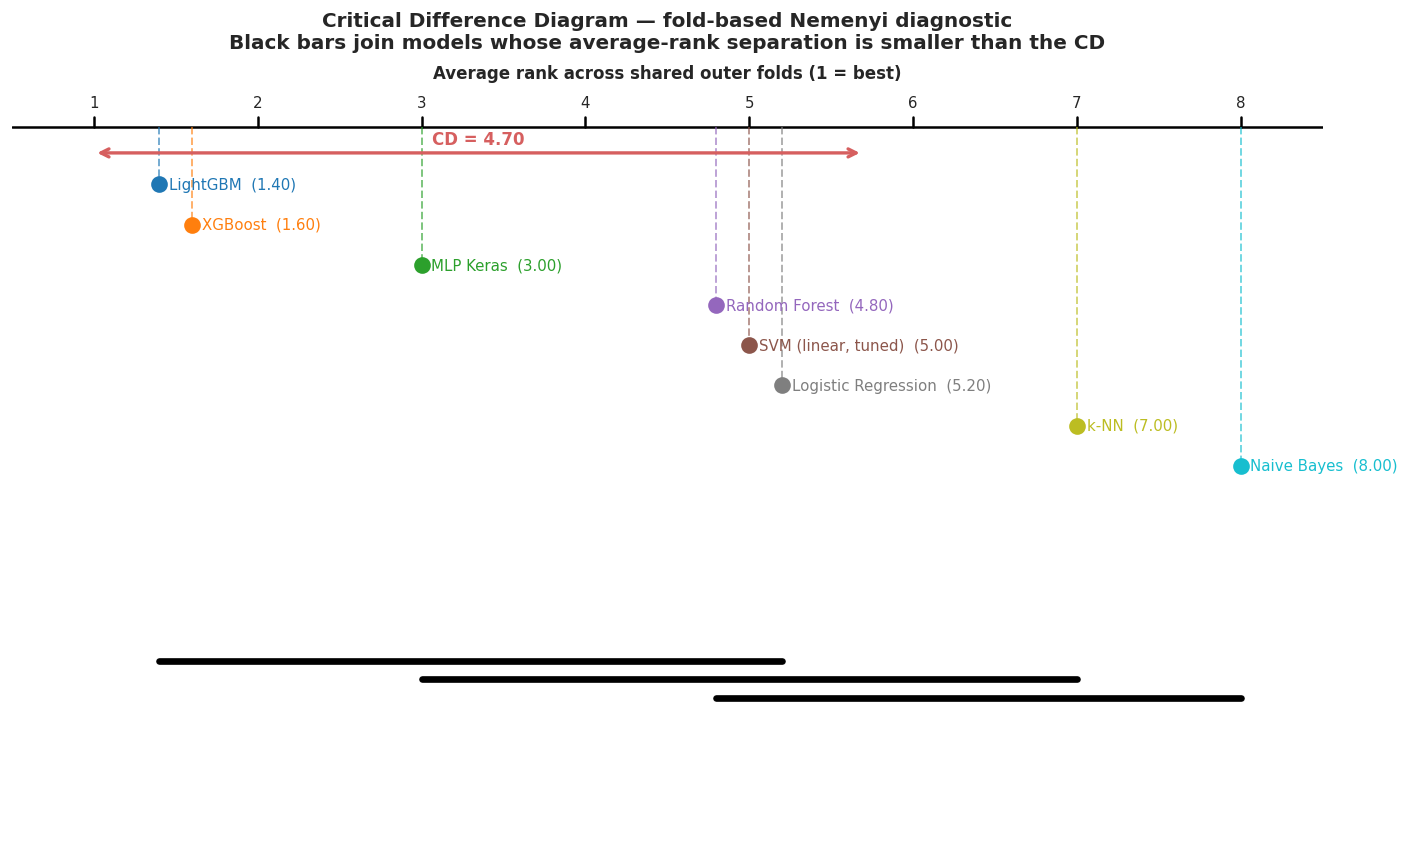

In [ ]:
# A6 Step 3 — Visualise rank separation with the critical-difference diagnostic
# Treat the fold-based critical-difference plot as a diagnostic, not independent-dataset evidence.


def average_ranks(arrays, names):
    """Rank models within each fold (1 = best), then average across folds."""

    df = pd.DataFrame(
        np.column_stack(arrays),
        columns=names
    )

    return (
        df.rank(
            axis=1,
            ascending=False,
            method='average'
        )
        .mean(axis=0)
        .sort_values()
    )


# Nemenyi critical values at alpha = 0.05

Q_ALPHA = {
    2: 1.960,
    3: 2.343,
    4: 2.569,
    5: 2.728,
    6: 2.850,
    7: 2.949,
    8: 3.031,
    9: 3.102,
    10: 3.164,
    11: 3.219,
    12: 3.268
}


assert k in Q_ALPHA, (
    f'No Nemenyi q_alpha value stored for k = {k}.'
)


avg_ranks = average_ranks(
    score_arrays,
    model_labels
)


q_alpha = Q_ALPHA[k]


CD = q_alpha * np.sqrt(
    k * (k + 1)
    /
    (6 * N)
)


rank_span = (
    avg_ranks.max()
    -
    avg_ranks.min()
)


print('=== CRITICAL DIFFERENCE DIAGRAM (Nemenyi, alpha = 0.05) ===')

print(
    f'  k = {k} models, '
    f'N = {N} shared outer folds, '
    f'q_alpha = {q_alpha}'
)

print(
    f'  CD = {q_alpha} * '
    f'sqrt({k}*{k + 1} / (6*{N})) '
    f'= {CD:.4f} rank positions'
)

print(
    f'  Rank span across all models: '
    f'{rank_span:.2f}'
)

print()

print(
    '  Average ranks (1 = best):'
)


for name, r in avg_ranks.items():

    print(
        f'    {name:<24} '
        f'{r:.2f}'
    )


print()


if p_f >= 0.05:

    print(
        '  NOTE: the Friedman omnibus test in A6.2 did not reject H0.'
    )

    print(
        '  Therefore the CD diagram below should be interpreted descriptively,'
    )

    print(
        '  not as confirmatory evidence of pairwise model differences.'
    )

    print()


if CD > rank_span:

    print(
        f'  CD ({CD:.2f}) exceeds the entire observed rank span '
        f'({rank_span:.2f}).'
    )

    print(
        '  Under this fold-based Nemenyi comparison, no pair of models can be'
    )

    print(
        '  separated by the critical-difference criterion.'
    )

    print(
        '  This reflects the limited resolution available with only five folds;'
    )

    print(
        '  it should not be interpreted as evidence that the models are equivalent.'
    )


# Draw the diagram

fig, ax = plt.subplots(
    figsize=(12, 0.55 * k + 3)
)


ax.set_xlim(
    0.5,
    k + 0.5
)

ax.set_ylim(
    -1.5 - 0.35 * k,
    k + 1.6
)


top = k + 0.4


# Rank axis

ax.axhline(
    top,
    color='black',
    lw=1.5
)


for r in range(1, k + 1):

    ax.plot(
        [r, r],
        [top, top + 0.18],
        color='black',
        lw=1.5
    )

    ax.text(
        r,
        top + 0.3,
        str(r),
        ha='center',
        va='bottom',
        fontsize=9
    )


ax.text(
    (1 + k) / 2,
    top + 0.85,
    'Average rank across shared outer folds (1 = best)',
    ha='center',
    fontsize=10,
    fontweight='bold'
)


# Model positions

colors = plt.cm.tab10(
    np.linspace(
        0,
        1,
        max(k, 3)
    )
)


for idx, (name, r) in enumerate(avg_ranks.items()):

    y = (
        k
        -
        0.6
        -
        idx * 0.7
    )

    ax.plot(
        [r, r],
        [top, y],
        color=colors[idx % len(colors)],
        lw=1.2,
        ls='--',
        alpha=0.6
    )

    ax.plot(
        r,
        y,
        'o',
        color=colors[idx % len(colors)],
        ms=9,
        zorder=5
    )

    ax.text(
        r + 0.06,
        y,
        f'{name}  ({r:.2f})',
        va='center',
        fontsize=9,
        color=colors[idx % len(colors)]
    )


cd_x = 1.0


ax.annotate(
    '',
    xy=(cd_x + CD, top - 0.45),
    xytext=(cd_x, top - 0.45),
    arrowprops=dict(
        arrowstyle='<->',
        color=RED,
        lw=2
    )
)


ax.text(
    cd_x + CD / 2,
    top - 0.30,
    f'CD = {CD:.2f}',
    ha='center',
    color=RED,
    fontsize=10,
    fontweight='bold'
)


rank_vals = avg_ranks.values
rank_names = avg_ranks.index.tolist()

candidate_groups = []


for i in range(len(rank_names)):

    j = i

    while (
        j + 1 < len(rank_names)
        and
        rank_vals[j + 1] - rank_vals[i] < CD
    ):

        j += 1


    if j > i:

        candidate_groups.append(
            (i, j)
        )


maximal_groups = []


for g in candidate_groups:

    contained = any(
        h != g
        and
        h[0] <= g[0]
        and
        h[1] >= g[1]
        for h in candidate_groups
    )

    if not contained:

        maximal_groups.append(
            g
        )


y_bar = -0.9


for start, end in maximal_groups:

    ax.plot(
        [rank_vals[start], rank_vals[end]],
        [y_bar, y_bar],
        color='black',
        lw=4,
        solid_capstyle='round'
    )

    y_bar -= 0.32


ax.set_title(
    'Critical Difference Diagram — fold-based Nemenyi diagnostic\n'
    'Black bars join models whose average-rank separation is smaller than the CD',
    fontweight='bold'
)


ax.axis(
    'off'
)


plt.tight_layout()


plt.savefig(
    '/content/a6_cd_diagram.png',
    dpi=300,
    bbox_inches='tight'
)


plt.show()


**Output explanation.** LightGBM has the best average rank at **1.40**, followed by XGBoost at **1.60**. The critical difference is large at about **4.70 rank positions** because only five folds are available. The chart therefore supports the ranking pattern but does not show a clear statistical separation between the leading models.

### A6 Step 4 — Calculate out-of-fold probabilities and calibration charts

Each development applicant is scored by a model that did not train on that row. These probabilities are then used to check how well predicted risk matches observed default rates.

Computing out-of-fold probabilities (one 5-fold pass per model)...
  Logistic Regression (tuned)      20s
  SVM (linear, tuned)              44s
  k-NN (tuned)                    125s
  Naive Bayes (tuned)               7s
  Random Forest (tuned)            62s
  XGBoost (tuned)                  32s
  LightGBM (tuned)                 21s
  MLP Keras (tuned)            reused from A5.3

=== HOME CREDIT CALIBRATION SUMMARY (10 bins, out-of-fold) ===
Model                              ECE     Brier   Mean pred    Actual      Bias
--------------------------------------------------------------------------------
SVM (linear, tuned)             0.0023    0.0687      0.0807    0.0807   -0.0000
k-NN (tuned)                    0.0044    0.0694      0.0768    0.0807   -0.0040
XGBoost (tuned)                 0.3120    0.1855      0.3927    0.0807   +0.3120
LightGBM (tuned)                0.3143    0.1870      0.3951    0.0807   +0.3143
MLP Keras (tuned)               0.3252    0.1909      0.4059  

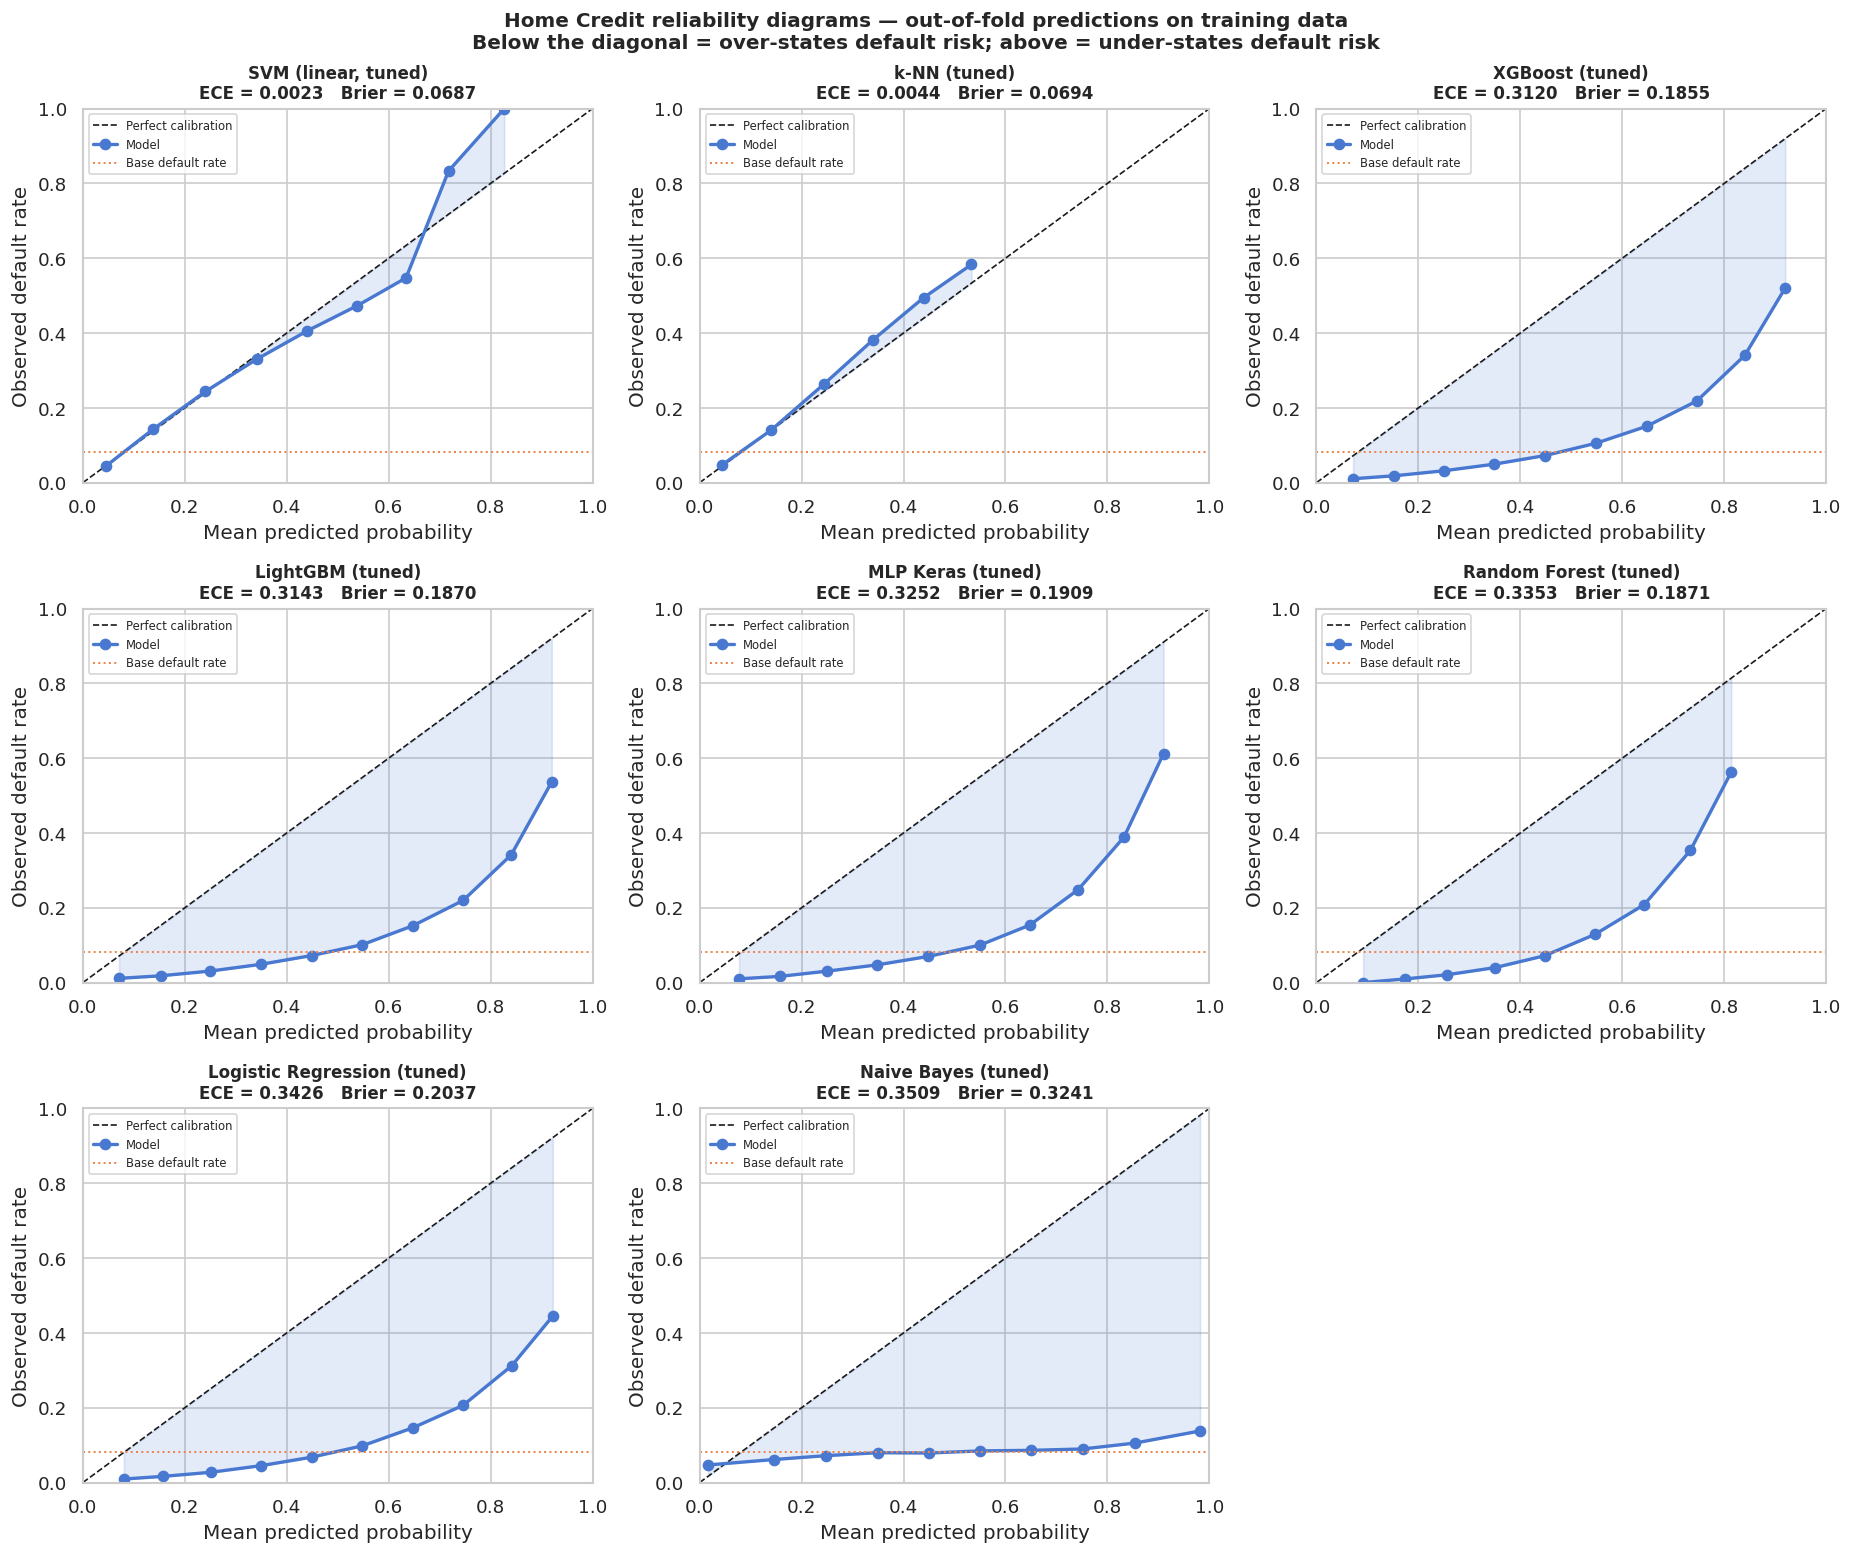

In [ ]:
# A6 Step 4 — Compute leakage-free out-of-fold probabilities and reliability diagrams
# Use out-of-fold training probabilities for calibration checks.

oof_probs = {}

# Reuse neural-network out-of-fold predictions accumulated earlier
PRECOMPUTED_OOF = {
    'MLP Keras (tuned)': oof_keras,
    'MLP PyTorch (tuned)': oof_torch
}

print('Computing out-of-fold probabilities (one 5-fold pass per model)...')

for name in STAT_MODELS:

    t0 = time.time()

    if name in PRECOMPUTED_OOF:

        oof_probs[name] = PRECOMPUTED_OOF[name]

        print(f'  {name:<28} reused from A5.3')

    else:

        oof_probs[name] = cross_val_predict(
            clone(tuned_models[name]),
            X_tr_sel,
            y_tr,
            cv=cv5,
            method='predict_proba',
            n_jobs=1
        )[:, 1]

        print(f'  {name:<28} {time.time() - t0:>6.0f}s')


# ECE summary for every model
actual_rate = float(y_tr.mean())

ece_rows = []

for name, p in oof_probs.items():

    ece_rows.append({
        'Model': name,
        'ECE': compute_ece(y_tr.values, p, N_BINS_ECE),
        'Brier': brier_score_loss(y_tr.values, p),
        'Mean_pred': p.mean(),
        'Actual_rate': actual_rate
    })

ece_df = (
    pd.DataFrame(ece_rows)
    .sort_values('ECE')
    .reset_index(drop=True)
)

print()
print(f'=== HOME CREDIT CALIBRATION SUMMARY ({N_BINS_ECE} bins, out-of-fold) ===')
print(f'{"Model":<28} {"ECE":>9} {"Brier":>9} {"Mean pred":>11} {"Actual":>9} {"Bias":>9}')
print('-' * 80)

for _, r in ece_df.iterrows():

    print(
        f'{r.Model:<28} '
        f'{r.ECE:>9.4f} '
        f'{r.Brier:>9.4f} '
        f'{r.Mean_pred:>11.4f} '
        f'{r.Actual_rate:>9.4f} '
        f'{r.Mean_pred - r.Actual_rate:>+9.4f}'
    )

print()
print('Bias is a blunt calibration summary: a large positive value means the model')
print('predicts a higher default probability on average than the observed Home Credit')
print('default rate; a large negative value means it tends to under-state risk.')
print('This can often be associated with class weighting and model form, but should')
print('be interpreted alongside the reliability diagrams rather than on its own.')


# Reliability diagrams for every model

models_to_plot = ece_df['Model'].tolist()

ncols = 3
nrows = int(np.ceil(len(models_to_plot) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5.2 * ncols, 4.4 * nrows)
)

axes = np.atleast_1d(axes).ravel()

for ax, name in zip(axes, models_to_plot):

    p = oof_probs[name]

    frac_pos, mean_pred = calibration_curve(
        y_tr.values,
        p,
        n_bins=N_BINS_ECE,
        strategy='uniform'
    )

    ece = compute_ece(y_tr.values, p, N_BINS_ECE)
    brier = brier_score_loss(y_tr.values, p)

    ax.plot(
        [0, 1],
        [0, 1],
        'k--',
        lw=1,
        label='Perfect calibration'
    )

    ax.plot(
        mean_pred,
        frac_pos,
        'o-',
        color=BLUE,
        lw=2,
        ms=6,
        label='Model'
    )

    ax.fill_between(
        mean_pred,
        frac_pos,
        mean_pred,
        alpha=0.15,
        color=BLUE
    )

    ax.axhline(
        actual_rate,
        color=ORANGE,
        ls=':',
        lw=1.2,
        label='Base default rate'
    )

    ax.set_title(
        f'{name}\nECE = {ece:.4f}   Brier = {brier:.4f}',
        fontweight='bold',
        fontsize=10
    )

    ax.set_xlabel('Mean predicted probability')
    ax.set_ylabel('Observed default rate')

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.legend(fontsize=7, loc='upper left')


for ax in axes[len(models_to_plot):]:
    ax.set_visible(False)


plt.suptitle(
    'Home Credit reliability diagrams — out-of-fold predictions on training data\n'
    'Below the diagonal = over-states default risk; above = under-states default risk',
    fontweight='bold',
    fontsize=12
)

plt.tight_layout()

plt.savefig(
    '/content/a6_home_credit_reliability_all.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


**Output explanation.** The out-of-fold calibration check shows that SVM and k-NN have small ECE values, while several class-weighted models predict default probabilities that are much higher than the observed **8.07%** default rate. LightGBM, for example, has mean predicted risk **0.3951** before calibration. This is why the winning model needs a separate calibration step before its probabilities are used for decisions.

### A6 Step 5 — Calibrate the development winner

Choose the calibration method using development data only, then apply the chosen method to the held-out test predictions.

=== CALIBRATING THE BEST HOME CREDIT MODEL: LightGBM (tuned) ===

=== CALIBRATOR SELECTION — TRAINING DATA ONLY ===
Method                    ECE      Brier
----------------------------------------
Platt scaling          0.0006     0.0676
Isotonic               0.0004     0.0676

Selected calibration method: Platt scaling
Selection was completed without using the sealed test labels.

Generating final probabilities on the sealed Home Credit test set...

=== FINAL TEST CALIBRATION — LightGBM (tuned) ===
Variant                  ECE     Brier    ROC-AUC   Mean pred
--------------------------------------------------------------
Uncalibrated          0.3167    0.1875     0.7673      0.3974
Platt scaling         0.0031    0.0671     0.7673      0.0814
Actual test rate                                       0.0807

Calibration changes the interpretation of predicted probabilities, not the underlying discrimination objective.
For Platt scaling, ROC-AUC should normally remain unchanged because t

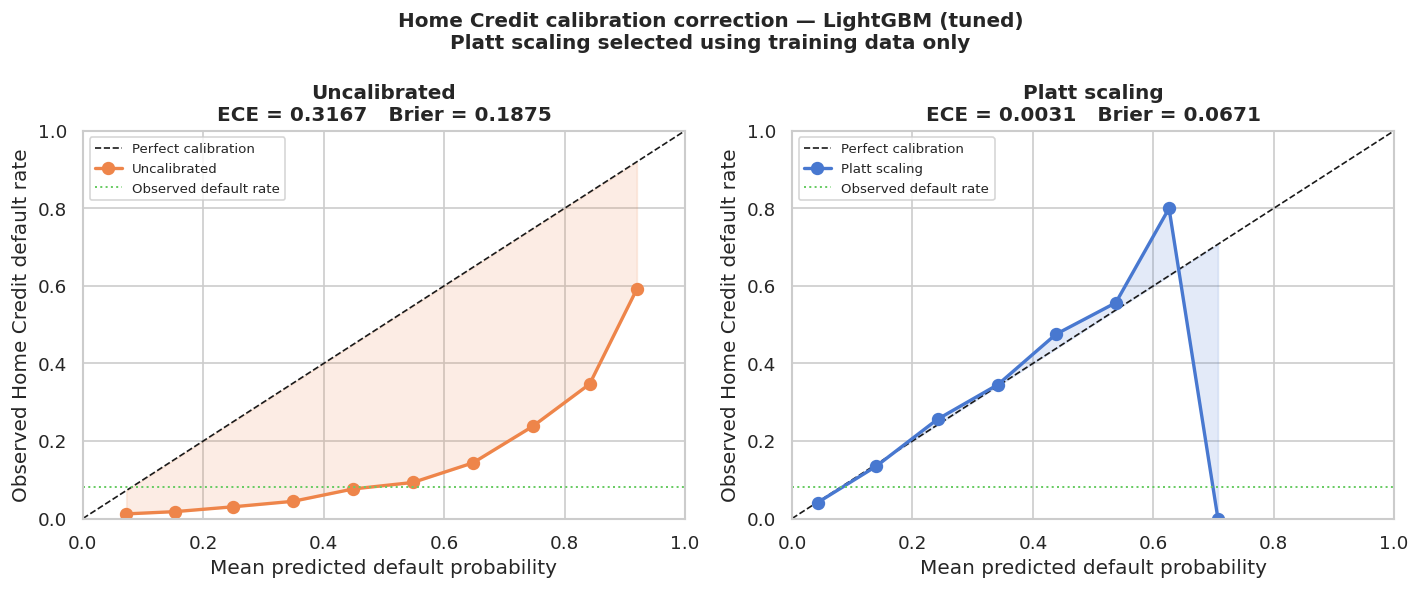


Platt scaling will be used for the Home Credit threshold analysis in A6.8.
  Test ECE: 0.3167 -> 0.0031


In [ ]:
# A6 Step 5 — Calibrate the development winner
# Choose the calibration method from training evidence only.


def predict_final_test(name):
    """Generate test probabilities from the final tuned Home Credit model.

    For sklearn models, refit the complete tuned pipeline on all development
    training rows.

    For the neural networks, use the final models produced in A5 using their
    predefined internal early-stopping protocol.

    No test labels are used here.
    """

    if name.startswith('MLP Keras'):

        return keras_final.predict(
            X_te_nn,
            verbose=0
        ).ravel()


    if name.startswith('MLP PyTorch'):

        torch_final.eval()

        with torch.no_grad():

            return (
                torch_final(
                    torch.tensor(
                        X_te_nn,
                        dtype=torch.float32,
                        device=DEVICE
                    )
                )
                .cpu()
                .numpy()
                .ravel()
            )


    pipe = clone(
        tuned_models[name]
    )

    pipe.fit(
        X_tr_sel,
        y_tr
    )

    return pipe.predict_proba(
        X_te_sel
    )[:, 1]


# Retrieve OOF probabilities for the selected model

print(
    f'=== CALIBRATING THE BEST HOME CREDIT MODEL: '
    f'{BEST_MODEL_NAME} ==='
)

oof_best = np.asarray(
    oof_probs[BEST_MODEL_NAME]
)

y_cal = y_tr.values


# Safe logit transformation

EPS = 1e-6


def safe_logit(p):

    p = np.clip(
        np.asarray(p),
        EPS,
        1 - EPS
    )

    return np.log(
        p / (1 - p)
    )


cal_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


platt_oof = np.zeros(
    len(y_cal),
    dtype=float
)

iso_oof = np.zeros(
    len(y_cal),
    dtype=float
)


for cal_tr, cal_va in cal_cv.split(
    oof_best,
    y_cal
):

    # Platt scaling

    platt_fold = LogisticRegression(
        C=1e6,
        solver='lbfgs'
    )

    platt_fold.fit(
        safe_logit(
            oof_best[cal_tr]
        ).reshape(-1, 1),

        y_cal[cal_tr]
    )

    platt_oof[cal_va] = platt_fold.predict_proba(
        safe_logit(
            oof_best[cal_va]
        ).reshape(-1, 1)
    )[:, 1]


    # Isotonic regression

    iso_fold = IsotonicRegression(
        out_of_bounds='clip',
        y_min=0.0,
        y_max=1.0
    )

    iso_fold.fit(
        oof_best[cal_tr],
        y_cal[cal_tr]
    )

    iso_oof[cal_va] = iso_fold.predict(
        oof_best[cal_va]
    )


calibration_selection = pd.DataFrame([

    {
        'Method': 'Platt scaling',

        'ECE': compute_ece(
            y_cal,
            platt_oof,
            N_BINS_ECE
        ),

        'Brier': brier_score_loss(
            y_cal,
            platt_oof
        )
    },

    {
        'Method': 'Isotonic',

        'ECE': compute_ece(
            y_cal,
            iso_oof,
            N_BINS_ECE
        ),

        'Brier': brier_score_loss(
            y_cal,
            iso_oof
        )
    }

])


calibration_selection = (
    calibration_selection
    .sort_values(
        ['Brier', 'ECE']
    )
    .reset_index(drop=True)
)


print()
print('=== CALIBRATOR SELECTION — TRAINING DATA ONLY ===')

print(
    f'{"Method":<18} '
    f'{"ECE":>10} '
    f'{"Brier":>10}'
)

print('-' * 40)


for _, r in calibration_selection.iterrows():

    print(
        f'{r.Method:<18} '
        f'{r.ECE:>10.4f} '
        f'{r.Brier:>10.4f}'
    )


CAL_METHOD = calibration_selection.iloc[0]['Method']


print()
print(
    f'Selected calibration method: {CAL_METHOD}'
)

print(
    'Selection was completed without using the sealed test labels.'
)


if CAL_METHOD == 'Platt scaling':

    final_calibrator = LogisticRegression(
        C=1e6,
        solver='lbfgs'
    )

    final_calibrator.fit(
        safe_logit(
            oof_best
        ).reshape(-1, 1),

        y_cal
    )


else:

    final_calibrator = IsotonicRegression(
        out_of_bounds='clip',
        y_min=0.0,
        y_max=1.0
    )

    final_calibrator.fit(
        oof_best,
        y_cal
    )


print()
print(
    'Generating final probabilities on the sealed Home Credit test set...'
)

test_probs_raw = predict_final_test(
    BEST_MODEL_NAME
)


if CAL_METHOD == 'Platt scaling':

    test_probs_cal = final_calibrator.predict_proba(
        safe_logit(
            test_probs_raw
        ).reshape(-1, 1)
    )[:, 1]

else:

    test_probs_cal = final_calibrator.predict(
        test_probs_raw
    )


test_variants = [

    (
        'Uncalibrated',
        test_probs_raw,
        ORANGE
    ),

    (
        CAL_METHOD,
        test_probs_cal,
        BLUE
    )
]


print()

print(
    f'=== FINAL TEST CALIBRATION — {BEST_MODEL_NAME} ==='
)

print(
    f'{"Variant":<18} '
    f'{"ECE":>9} '
    f'{"Brier":>9} '
    f'{"ROC-AUC":>10} '
    f'{"Mean pred":>11}'
)

print('-' * 62)


for label, p, _ in test_variants:

    print(
        f'{label:<18} '
        f'{compute_ece(y_te.values, p, N_BINS_ECE):>9.4f} '
        f'{brier_score_loss(y_te.values, p):>9.4f} '
        f'{roc_auc_score(y_te.values, p):>10.4f} '
        f'{p.mean():>11.4f}'
    )


print(
    f'{"Actual test rate":<18} '
    f'{"":>9} '
    f'{"":>9} '
    f'{"":>10} '
    f'{y_te.mean():>11.4f}'
)


print()
print(
    'Calibration changes the interpretation of predicted probabilities, '
    'not the underlying discrimination objective.'
)

print(
    'For Platt scaling, ROC-AUC should normally remain unchanged because '
    'the fitted mapping is monotonic when its slope is positive.'
)

print(
    'Isotonic regression is non-decreasing and can create tied probabilities, '
    'so ROC-AUC can occasionally change slightly.'
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)


for ax, (label, p, colr) in zip(
    axes,
    test_variants
):

    frac_pos, mean_pred = calibration_curve(
        y_te.values,
        p,
        n_bins=N_BINS_ECE,
        strategy='uniform'
    )

    ece = compute_ece(
        y_te.values,
        p,
        N_BINS_ECE
    )

    brier = brier_score_loss(
        y_te.values,
        p
    )


    ax.plot(
        [0, 1],
        [0, 1],
        'k--',
        lw=1,
        label='Perfect calibration'
    )

    ax.plot(
        mean_pred,
        frac_pos,
        'o-',
        color=colr,
        lw=2,
        ms=7,
        label=label
    )

    ax.fill_between(
        mean_pred,
        frac_pos,
        mean_pred,
        alpha=0.15,
        color=colr
    )

    ax.axhline(
        y_te.mean(),
        color=GREEN,
        ls=':',
        lw=1.2,
        label='Observed default rate'
    )

    ax.set_title(
        f'{label}\n'
        f'ECE = {ece:.4f}   '
        f'Brier = {brier:.4f}',
        fontweight='bold'
    )

    ax.set_xlabel(
        'Mean predicted default probability'
    )

    ax.set_ylabel(
        'Observed Home Credit default rate'
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.legend(
        fontsize=8,
        loc='upper left'
    )


plt.suptitle(
    f'Home Credit calibration correction — {BEST_MODEL_NAME}\n'
    f'{CAL_METHOD} selected using training data only',
    fontweight='bold',
    fontsize=12
)

plt.tight_layout()

plt.savefig(
    '/content/a6_home_credit_calibration_correction.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


raw_ece = compute_ece(
    y_te.values,
    test_probs_raw,
    N_BINS_ECE
)

cal_ece = compute_ece(
    y_te.values,
    test_probs_cal,
    N_BINS_ECE
)


print()

print(
    f'{CAL_METHOD} will be used for the Home Credit '
    'threshold analysis in A6.8.'
)

print(
    f'  Test ECE: '
    f'{raw_ece:.4f} -> {cal_ece:.4f}'
)


**Output explanation.** Platt scaling is selected using training data only. On the held-out test set, LightGBM ECE improves from **0.3167 to 0.0031**, while ROC-AUC stays at **0.7673**. The mean predicted default probability also moves close to the true test default rate, so the calibrated probabilities are used for threshold selection and reporting.

### A6 Step 6 — Check subgroup performance

Compare model behaviour across gender, age, education and family-status groups on the held-out test set.

=== HOME CREDIT SUBGROUP FAIRNESS — LightGBM (tuned) (Platt scaling calibrated) ===
  Held-out applicants:           61,503
  Overall test ROC-AUC:          0.7673
  Overall default prevalence:    8.07%
  Overall selection rate @ 0.50: 0.23%
  Overall TPR:                   0.0169
  Overall FPR:                   0.0010

--- Gender ---
Group                           N  Defaults  True rate      AUC   Selection      TPR      FPR
--------------------------------------------------------------------------------------------------
Male                       20,940     2,129     10.17%   0.7631       0.33%    0.019    0.002
Female                     40,561     2,836      6.99%   0.7624       0.18%    0.016    0.001
  range                                                  0.0006       0.15%    0.003    0.001

--- Age band ---
Group                           N  Defaults  True rate      AUC   Selection      TPR      FPR
---------------------------------------------------------------------------

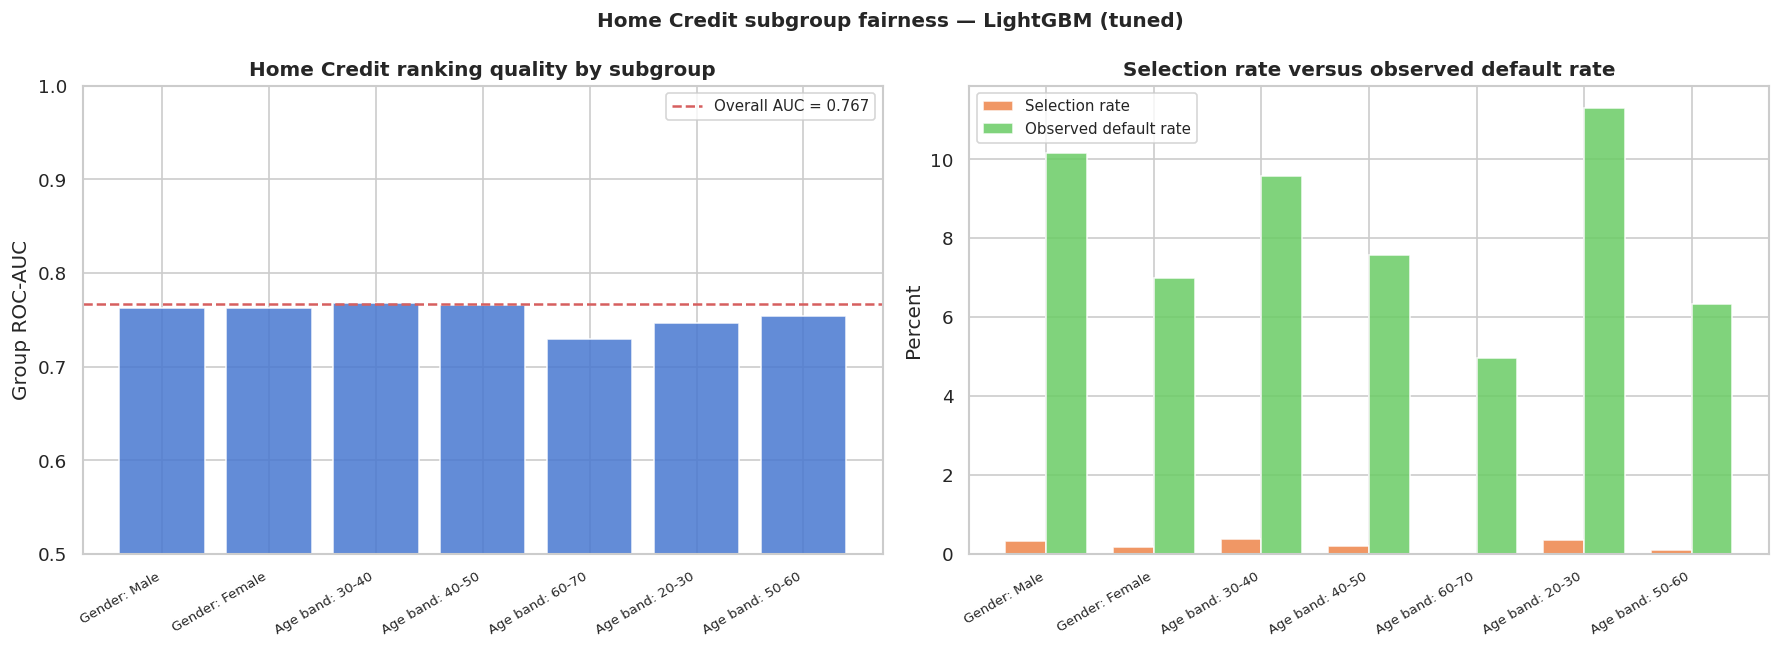


WRITE-UP GUIDANCE:
Compare subgroup ROC-AUC, selection rate, TPR and FPR.
A difference in selection rate does not by itself demonstrate unfairness.
It should be interpreted alongside observed subgroup default prevalence,
true-positive rates, false-positive rates and subgroup sample sizes.

The 0.50 threshold used here is a fixed reference threshold for auditing;
it is not assumed to be the final cost-sensitive Home Credit threshold.


In [ ]:
# A6 Step 6 — Audit subgroup performance
# Audit subgroup behaviour on the held-out test set using aligned metadata.


# Prepare held-out test metadata safely

META_COLS = [
    'CODE_GENDER',
    'NAME_EDUCATION_TYPE',
    'NAME_FAMILY_STATUS',
    'DAYS_BIRTH'
]


missing_meta_cols = [
    col
    for col in META_COLS
    if col not in df_te_fe.columns
]


if missing_meta_cols:

    raise KeyError(
        'The following fairness columns are missing from df_te_fe: '
        f'{missing_meta_cols}'
    )


# Row-alignment check

if len(df_te_fe) != len(X_te_sel):

    raise ValueError(
        'Fairness metadata cannot be aligned safely: '
        f'df_te_fe has {len(df_te_fe):,} rows but '
        f'X_te_sel has {len(X_te_sel):,} rows.'
    )


meta_source = (
    df_te_fe
    .reset_index(drop=True)
)


test_meta = (
    meta_source[
        META_COLS
    ]
    .copy()
)


# Attach the sealed test target

if 'TARGET' in meta_source.columns:

    test_meta['TARGET'] = (
        meta_source['TARGET']
        .to_numpy()
        .reshape(-1)
    )


elif 'y_te' in globals():

    y_te_array = (
        np.asarray(y_te)
        .reshape(-1)
    )

    if len(y_te_array) != len(test_meta):

        raise ValueError(
            'y_te is not aligned with the held-out test metadata: '
            f'y_te has {len(y_te_array):,} observations but '
            f'test_meta has {len(test_meta):,}.'
        )

    test_meta['TARGET'] = (
        y_te_array
    )


else:

    raise KeyError(
        'TARGET is not present in df_te_fe and y_te was not found. '
        'The held-out test target is required for the fairness audit.'
    )


# Attach calibrated probabilities from A6.5

test_probs_cal_array = (
    np.asarray(test_probs_cal)
    .reshape(-1)
)


if len(test_probs_cal_array) != len(test_meta):

    raise ValueError(
        'Calibrated probabilities are not aligned with the held-out test set: '
        f'test_probs_cal has {len(test_probs_cal_array):,} values but '
        f'test_meta has {len(test_meta):,} rows.'
    )


if not np.isfinite(test_probs_cal_array).all():

    raise ValueError(
        'test_probs_cal contains NaN or infinite probability values.'
    )


test_meta['prob'] = (
    test_probs_cal_array
)


test_meta['TARGET'] = (
    pd.to_numeric(
        test_meta['TARGET'],
        errors='coerce'
    )
)


if test_meta['TARGET'].isna().any():

    raise ValueError(
        'The held-out TARGET contains missing or non-numeric values.'
    )


unique_targets = set(
    test_meta['TARGET']
    .astype(int)
    .unique()
)


if not unique_targets.issubset({0, 1}):

    raise ValueError(
        f'Expected binary TARGET values 0/1, but found: '
        f'{sorted(unique_targets)}'
    )


test_meta['TARGET'] = (
    test_meta['TARGET']
    .astype(int)
)


test_meta['AGE_YEARS'] = (
    -pd.to_numeric(
        test_meta['DAYS_BIRTH'],
        errors='coerce'
    )
    /
    365.25
)


test_meta['age_band'] = pd.cut(
    test_meta['AGE_YEARS'],
    bins=[
        20,
        30,
        40,
        50,
        60,
        70,
        100
    ],
    labels=[
        '20-30',
        '30-40',
        '40-50',
        '50-60',
        '60-70',
        '70+'
    ],
    include_lowest=True
)


gender_map = {
    'M': 'Male',
    'F': 'Female',
    'XNA': 'Unknown',
    'Unknown': 'Unknown'
}


test_meta['gender_label'] = (
    test_meta[
        'CODE_GENDER'
    ]
    .astype(str)
    .map(
        gender_map
    )
    .fillna(
        test_meta[
            'CODE_GENDER'
        ].astype(str)
    )
)


FAIRNESS_THRESHOLD = 0.5


test_meta['flagged'] = (
    test_meta['prob']
    >=
    FAIRNESS_THRESHOLD
).astype(int)


overall_auc = roc_auc_score(
    test_meta['TARGET'],
    test_meta['prob']
)


overall_selection = (
    test_meta['flagged']
    .mean()
)


overall_tpr = (
    test_meta.loc[
        test_meta['TARGET'] == 1,
        'flagged'
    ]
    .mean()
)


overall_fpr = (
    test_meta.loc[
        test_meta['TARGET'] == 0,
        'flagged'
    ]
    .mean()
)


print(
    f'=== HOME CREDIT SUBGROUP FAIRNESS — '
    f'{BEST_MODEL_NAME} '
    f'({CAL_METHOD} calibrated) ==='
)

print(
    f'  Held-out applicants:           '
    f'{len(test_meta):,}'
)

print(
    f'  Overall test ROC-AUC:          '
    f'{overall_auc:.4f}'
)

print(
    f'  Overall default prevalence:    '
    f'{test_meta["TARGET"].mean() * 100:.2f}%'
)

print(
    f'  Overall selection rate @ '
    f'{FAIRNESS_THRESHOLD:.2f}: '
    f'{overall_selection * 100:.2f}%'
)

print(
    f'  Overall TPR:                   '
    f'{overall_tpr:.4f}'
)

print(
    f'  Overall FPR:                   '
    f'{overall_fpr:.4f}'
)

print()


GROUPS = [
    (
        'gender_label',
        'Gender'
    ),

    (
        'age_band',
        'Age band'
    ),

    (
        'NAME_EDUCATION_TYPE',
        'Education'
    ),

    (
        'NAME_FAMILY_STATUS',
        'Family status'
    )
]


fairness_rows = []


for col, label in GROUPS:

    print(
        f'--- {label} ---'
    )

    print(
        f'{"Group":<24} '
        f'{"N":>8} '
        f'{"Defaults":>9} '
        f'{"True rate":>10} '
        f'{"AUC":>8} '
        f'{"Selection":>11} '
        f'{"TPR":>8} '
        f'{"FPR":>8}'
    )

    print(
        '-' * 98
    )


    group_rows = []


    group_values = (
        test_meta[col]
        .dropna()
        .unique()
    )


    for val in group_values:

        sub = (
            test_meta[
                test_meta[col] == val
            ]
            .copy()
        )


        if len(sub) < 50:

            continue


        if sub['TARGET'].nunique() < 2:

            continue


        n_defaults = int(
            sub['TARGET']
            .sum()
        )


        n_nondefaults = int(
            len(sub)
            -
            n_defaults
        )


        auc = roc_auc_score(
            sub['TARGET'],
            sub['prob']
        )


        selection_rate = (
            sub['flagged']
            .mean()
        )


        true_rate = (
            sub['TARGET']
            .mean()
        )


        tpr = (
            sub.loc[
                sub['TARGET'] == 1,
                'flagged'
            ]
            .mean()
        )


        fpr = (
            sub.loc[
                sub['TARGET'] == 0,
                'flagged'
            ]
            .mean()
        )


        row = {

            'group_col':
                col,

            'group_type':
                label,

            'group':
                str(val),

            'n':
                len(sub),

            'n_defaults':
                n_defaults,

            'n_nondefaults':
                n_nondefaults,

            'true_rate':
                true_rate,

            'auc':
                auc,

            'sel_rate':
                selection_rate,

            'tpr':
                tpr,

            'fpr':
                fpr
        }


        group_rows.append(
            row
        )

        fairness_rows.append(
            row
        )


        print(
            f'{str(val)[:23]:<24} '
            f'{len(sub):>8,} '
            f'{n_defaults:>9,} '
            f'{true_rate * 100:>9.2f}% '
            f'{auc:>8.4f} '
            f'{selection_rate * 100:>10.2f}% '
            f'{tpr:>8.3f} '
            f'{fpr:>8.3f}'
        )


    if group_rows:

        aucs = [
            row['auc']
            for row in group_rows
        ]

        selections = [
            row['sel_rate']
            for row in group_rows
        ]

        tprs = [
            row['tpr']
            for row in group_rows
        ]

        fprs = [
            row['fpr']
            for row in group_rows
        ]


        print(
            f'{"  range":<24} '
            f'{"":>8} '
            f'{"":>9} '
            f'{"":>10} '
            f'{max(aucs) - min(aucs):>8.4f} '
            f'{(max(selections) - min(selections)) * 100:>10.2f}% '
            f'{max(tprs) - min(tprs):>8.3f} '
            f'{max(fprs) - min(fprs):>8.3f}'
        )


    print()


fairness_df = pd.DataFrame(
    fairness_rows
)


if fairness_df.empty:

    raise ValueError(
        'No subgroup fairness results were produced. '
        'Check the subgroup columns and minimum-group-size criterion.'
    )


sub_plot = (
    fairness_df[
        fairness_df[
            'group_col'
        ].isin(
            [
                'gender_label',
                'age_band'
            ]
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


if not sub_plot.empty:


    sub_plot[
        'plot_label'
    ] = (
        sub_plot['group_type']
        +
        ': '
        +
        sub_plot['group']
    )


    x = np.arange(
        len(sub_plot)
    )


    fig, axes = plt.subplots(
        1,
        2,
        figsize=(15, 5.5)
    )


    axes[0].bar(
        x,
        sub_plot['auc'],
        color=BLUE,
        alpha=0.85
    )


    axes[0].axhline(
        overall_auc,
        color=RED,
        ls='--',
        lw=1.5,
        label=(
            f'Overall AUC = '
            f'{overall_auc:.3f}'
        )
    )


    axes[0].set_xticks(
        x
    )


    axes[0].set_xticklabels(
        sub_plot[
            'plot_label'
        ],
        rotation=30,
        ha='right',
        fontsize=8
    )


    axes[0].set_ylabel(
        'Group ROC-AUC'
    )


    axes[0].set_ylim(
        0.5,
        1.0
    )


    axes[0].set_title(
        'Home Credit ranking quality by subgroup',
        fontweight='bold'
    )


    axes[0].legend(
        fontsize=9
    )


    w = 0.38


    axes[1].bar(
        x - w / 2,
        sub_plot[
            'sel_rate'
        ] * 100,
        width=w,
        color=ORANGE,
        alpha=0.85,
        label='Selection rate'
    )


    axes[1].bar(
        x + w / 2,
        sub_plot[
            'true_rate'
        ] * 100,
        width=w,
        color=GREEN,
        alpha=0.85,
        label='Observed default rate'
    )


    axes[1].set_xticks(
        x
    )


    axes[1].set_xticklabels(
        sub_plot[
            'plot_label'
        ],
        rotation=30,
        ha='right',
        fontsize=8
    )


    axes[1].set_ylabel(
        'Percent'
    )


    axes[1].set_title(
        'Selection rate versus observed default rate',
        fontweight='bold'
    )


    axes[1].legend(
        fontsize=9
    )


    plt.suptitle(
        f'Home Credit subgroup fairness — '
        f'{BEST_MODEL_NAME}',
        fontweight='bold',
        fontsize=12
    )


    plt.tight_layout()


    plt.savefig(
        '/content/a6_home_credit_fairness.png',
        dpi=300,
        bbox_inches='tight'
    )


    plt.show()


print()

print(
    'WRITE-UP GUIDANCE:'
)

print(
    'Compare subgroup ROC-AUC, selection rate, TPR and FPR.'
)

print(
    'A difference in selection rate does not by itself demonstrate unfairness.'
)

print(
    'It should be interpreted alongside observed subgroup default prevalence,'
)

print(
    'true-positive rates, false-positive rates and subgroup sample sizes.'
)

print()

print(
    'The 0.50 threshold used here is a fixed reference threshold for auditing;'
)

print(
    'it is not assumed to be the final cost-sensitive Home Credit threshold.'
)


**Output explanation.** Gender ROC-AUC is very similar, with a range of only about **0.0006**. Larger ROC-AUC ranges appear across **age groups (0.0392)** and **family-status groups (0.0295)**, while the education range is small at about **0.0034**. Selection, true-positive and false-positive rates also vary, so subgroup behaviour should be monitored rather than judged from one fairness measure alone.

### A6 Step 7 — Test whether SMOTENC helps with class imbalance

Apply SMOTENC inside each training fold only and compare it with class weighting and no imbalance correction.


=== HOME CREDIT IMBALANCE INVESTIGATION — LightGBM (tuned) ===
5-fold stratified CV using identical folds

Arm                                 ROC-AUC     PR-AUC    Recall     Brier     Time
----------------------------------------------------------------------------------
Class weighting (incumbent)          0.7621     0.2485    0.6716    0.1870      33s
No imbalance correction              0.7628     0.2497    0.0280    0.0675      32s
SMOTENC inside the fold              0.7264     0.1964    0.1026    0.0783     157s
----------------------------------------------------------------------------------
SMOTENC vs class weighting          -0.0357    -0.0521   -0.5690   -0.1088

For ROC-AUC, PR-AUC and Recall: positive Δ favours SMOTENC.
For Brier score: negative Δ favours SMOTENC because lower is better.


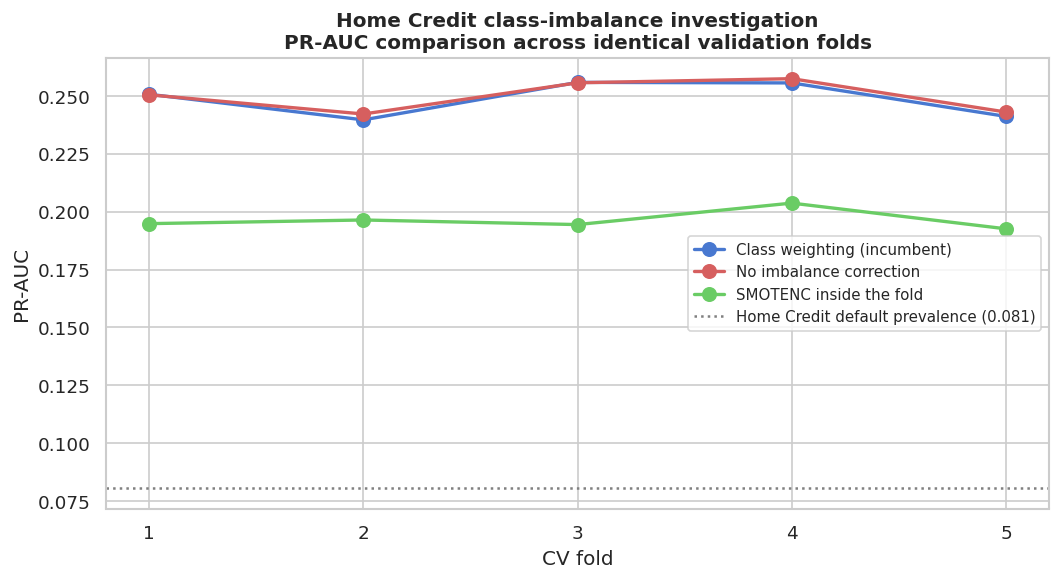

=== CRITICAL DISCUSSION: SHOULD SYNTHETIC OVERSAMPLING BE USED FOR HOME CREDIT? ===

1. SYNTHETIC APPLICANTS
   SMOTENC generates additional minority-class training observations from patterns
   among existing TARGET=1 applicants. These observations are synthetic training
   examples rather than additional observed borrowers.

2. HISTORICAL-BIAS CONSIDERATION
   Oversampling does not create new information about default behaviour. It increases
   the influence of patterns already present in minority-class observations.
   Consequently, historical sampling or representation problems may also receive greater weight.

3. MIXED HOME CREDIT FEATURES
   Ordinary SMOTE after one-hot encoding could generate fractional dummy coordinates.
   SMOTENC is therefore used here so categorical Home Credit variables are handled
   as categorical attributes rather than interpolated as ordinary continuous numbers.

4. PROBABILITY CALIBRATION
   Synthetic oversampling changes the class distribution present

In [ ]:
# A6 Step 7 — Test whether SMOTENC improves the imbalanced problem
# Apply SMOTENC inside each cross-validation training fold only.


from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline


# Remove built-in class-imbalance weighting

def strip_class_weighting(clf):
    """Return a cloned estimator with built-in imbalance correction removed."""

    c = clone(clf)

    params = c.get_params()

    if 'class_weight' in params:
        c.set_params(
            class_weight=None
        )

    if 'scale_pos_weight' in params:
        c.set_params(
            scale_pos_weight=1.0
        )

    return c


# Choose sklearn-compatible model for the SMOTENC experiment

if BEST_MODEL_NAME.startswith('MLP'):

    eligible_models = [
        m for m in tuned_models
        if m in fold_scores
        and not m.startswith('MLP')
    ]

    SMOTE_TARGET = max(
        eligible_models,
        key=lambda m: np.mean(fold_scores[m])
    )

    print(
        'NOTE: the overall best model is a neural network.'
    )

    print(
        'The synthetic-oversampling investigation will therefore '
        'use the best sklearn-compatible model:'
    )

    print(
        f'  {SMOTE_TARGET}'
    )

else:

    SMOTE_TARGET = BEST_MODEL_NAME


# Retrieve the tuned classifier

base_pipe = clone(
    tuned_models[SMOTE_TARGET]
)

best_clf = base_pipe.named_steps[
    'clf'
]


# PRE-SMOTENC preprocessing

log1p_smote = FunctionTransformer(
    np.log1p,
    validate=True,
    feature_names_out='one-to-one'
)


pre_smote = ColumnTransformer(

    transformers=[

        (
            'num_skew',

            Pipeline([
                ('imp', SimpleImputer(strategy='median')),
                ('log', log1p_smote),
                ('sc', StandardScaler())
            ]),

            sel_num_skewed
        ),


        (
            'num',

            Pipeline([
                ('imp', SimpleImputer(strategy='median')),
                ('sc', StandardScaler())
            ]),

            sel_num_plain
        ),


        (
            'cat',

            Pipeline([
                (
                    'imp',
                    SimpleImputer(
                        strategy='most_frequent'
                    )
                )
            ]),

            sel_cat
        )
    ],

    remainder='drop'
)


n_num = (
    len(sel_num_skewed)
    +
    len(sel_num_plain)
)

cat_indices = list(
    range(
        n_num,
        n_num + len(sel_cat)
    )
)

num_indices = list(
    range(n_num)
)


post_smote = ColumnTransformer(

    transformers=[

        (
            'num',
            'passthrough',
            num_indices
        ),

        (
            'cat',

            OneHotEncoder(
                drop='first',
                sparse_output=False,
                handle_unknown='ignore'
            ),

            cat_indices
        )
    ],

    remainder='drop'
)


arms = {


    'Class weighting (incumbent)': ImbPipeline([

        (
            'pre',
            clone(pre_smote)
        ),

        (
            'post',
            clone(post_smote)
        ),

        (
            'clf',
            clone(best_clf)
        )
    ]),


    'No imbalance correction': ImbPipeline([

        (
            'pre',
            clone(pre_smote)
        ),

        (
            'post',
            clone(post_smote)
        ),

        (
            'clf',
            strip_class_weighting(
                best_clf
            )
        )
    ]),


    'SMOTENC inside the fold': ImbPipeline([

        (
            'pre',
            clone(pre_smote)
        ),

        (
            'smote',

            SMOTENC(
                categorical_features=cat_indices,
                random_state=RANDOM_STATE,
                sampling_strategy=0.30,
                k_neighbors=5
            )
        ),

        (
            'post',
            clone(post_smote)
        ),

        (
            'clf',
            strip_class_weighting(
                best_clf
            )
        )
    ])
}


print(
    f'\n=== HOME CREDIT IMBALANCE INVESTIGATION — '
    f'{SMOTE_TARGET} ==='
)

print(
    '5-fold stratified CV using identical folds'
)

print()

print(
    f'{"Arm":<32} '
    f'{"ROC-AUC":>10} '
    f'{"PR-AUC":>10} '
    f'{"Recall":>9} '
    f'{"Brier":>9} '
    f'{"Time":>8}'
)

print('-' * 82)


smote_results = {}


for label, pipe in arms.items():

    t0 = time.time()

    cv = cross_validate(

        pipe,

        X_tr_sel,
        y_tr,

        cv=cv5,

        scoring=SCORING,

        n_jobs=1
    )


    smote_results[label] = {

        'roc': cv[
            'test_roc_auc'
        ].mean(),

        'pr': cv[
            'test_pr_auc'
        ].mean(),

        'recall': cv[
            'test_recall'
        ].mean(),

        'brier': -cv[
            'test_brier'
        ].mean(),

        'folds': cv[
            'test_pr_auc'
        ]
    }


    r = smote_results[label]


    print(
        f'{label:<32} '
        f'{r["roc"]:>10.4f} '
        f'{r["pr"]:>10.4f} '
        f'{r["recall"]:>9.4f} '
        f'{r["brier"]:>9.4f} '
        f'{time.time() - t0:>7.0f}s'
    )


inc = smote_results[
    'Class weighting (incumbent)'
]

sm = smote_results[
    'SMOTENC inside the fold'
]


print('-' * 82)

print(
    f'{"SMOTENC vs class weighting":<32} '
    f'{sm["roc"] - inc["roc"]:>+10.4f} '
    f'{sm["pr"] - inc["pr"]:>+10.4f} '
    f'{sm["recall"] - inc["recall"]:>+9.4f} '
    f'{sm["brier"] - inc["brier"]:>+9.4f}'
)

print()

print(
    'For ROC-AUC, PR-AUC and Recall: positive Δ favours SMOTENC.'
)

print(
    'For Brier score: negative Δ favours SMOTENC because lower is better.'
)


fig, ax = plt.subplots(
    figsize=(9, 5)
)


for (label, r), colr in zip(
    smote_results.items(),
    [BLUE, RED, GREEN]
):

    ax.plot(
        np.arange(1, 6),
        r['folds'],
        'o-',
        color=colr,
        lw=2,
        ms=8,
        label=label
    )


ax.axhline(
    y_tr.mean(),
    color='grey',
    ls=':',
    lw=1.5,
    label=(
        f'Home Credit default prevalence '
        f'({y_tr.mean():.3f})'
    )
)


ax.set_xticks(
    np.arange(1, 6)
)

ax.set_xlabel(
    'CV fold'
)

ax.set_ylabel(
    'PR-AUC'
)

ax.set_title(
    'Home Credit class-imbalance investigation\n'
    'PR-AUC comparison across identical validation folds',
    fontweight='bold'
)

ax.legend(
    fontsize=9
)


plt.tight_layout()

plt.savefig(
    '/content/a6_home_credit_smote.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


print(
    '=== CRITICAL DISCUSSION: SHOULD SYNTHETIC OVERSAMPLING '
    'BE USED FOR HOME CREDIT? ==='
)

print()


print(
    '1. SYNTHETIC APPLICANTS'
)

print(
    '   SMOTENC generates additional minority-class training observations '
    'from patterns'
)

print(
    '   among existing TARGET=1 applicants. These observations are '
    'synthetic training'
)

print(
    '   examples rather than additional observed borrowers.'
)

print()


print(
    '2. HISTORICAL-BIAS CONSIDERATION'
)

print(
    '   Oversampling does not create new information about default behaviour. '
    'It increases'
)

print(
    '   the influence of patterns already present in minority-class observations.'
)

print(
    '   Consequently, historical sampling or representation problems may also '
    'receive greater weight.'
)

print()


print(
    '3. MIXED HOME CREDIT FEATURES'
)

print(
    '   Ordinary SMOTE after one-hot encoding could generate fractional '
    'dummy coordinates.'
)

print(
    '   SMOTENC is therefore used here so categorical Home Credit variables '
    'are handled'
)

print(
    '   as categorical attributes rather than interpolated as ordinary '
    'continuous numbers.'
)

print()


print(
    '4. PROBABILITY CALIBRATION'
)

print(
    '   Synthetic oversampling changes the class distribution presented '
    'during model fitting.'
)

print(
    '   Therefore improvements in recall or PR-AUC must be considered '
    'alongside Brier'
)

print(
    '   score and the calibration analysis performed in A6.4–A6.5.'
)

print()


print(
    'REPORT DECISION:'
)

print(
    'Compare class weighting, no correction and SMOTENC using the observed '
    'ROC-AUC,'
)

print(
    'PR-AUC, recall and Brier scores. Prefer SMOTENC only if the measured '
    'benefit is'
)

print(
    'large enough to justify the additional synthetic-data complexity.'
)


**Output explanation.** SMOTENC performs worse than the current class-weighted LightGBM on ROC-AUC, PR-AUC and recall. Its ROC-AUC falls from **0.7621 to 0.7264**, PR-AUC falls from **0.2485 to 0.1964**, and it also takes much longer to run. The no-correction model has a strong Brier score but very low recall at the 0.5 threshold. Based on these results, SMOTENC is not used in the final workflow.

### A6 Step 8 — Select a cost-based decision threshold from development data

Choose the threshold using out-of-fold calibrated probabilities, then measure that fixed threshold once on the held-out test set.

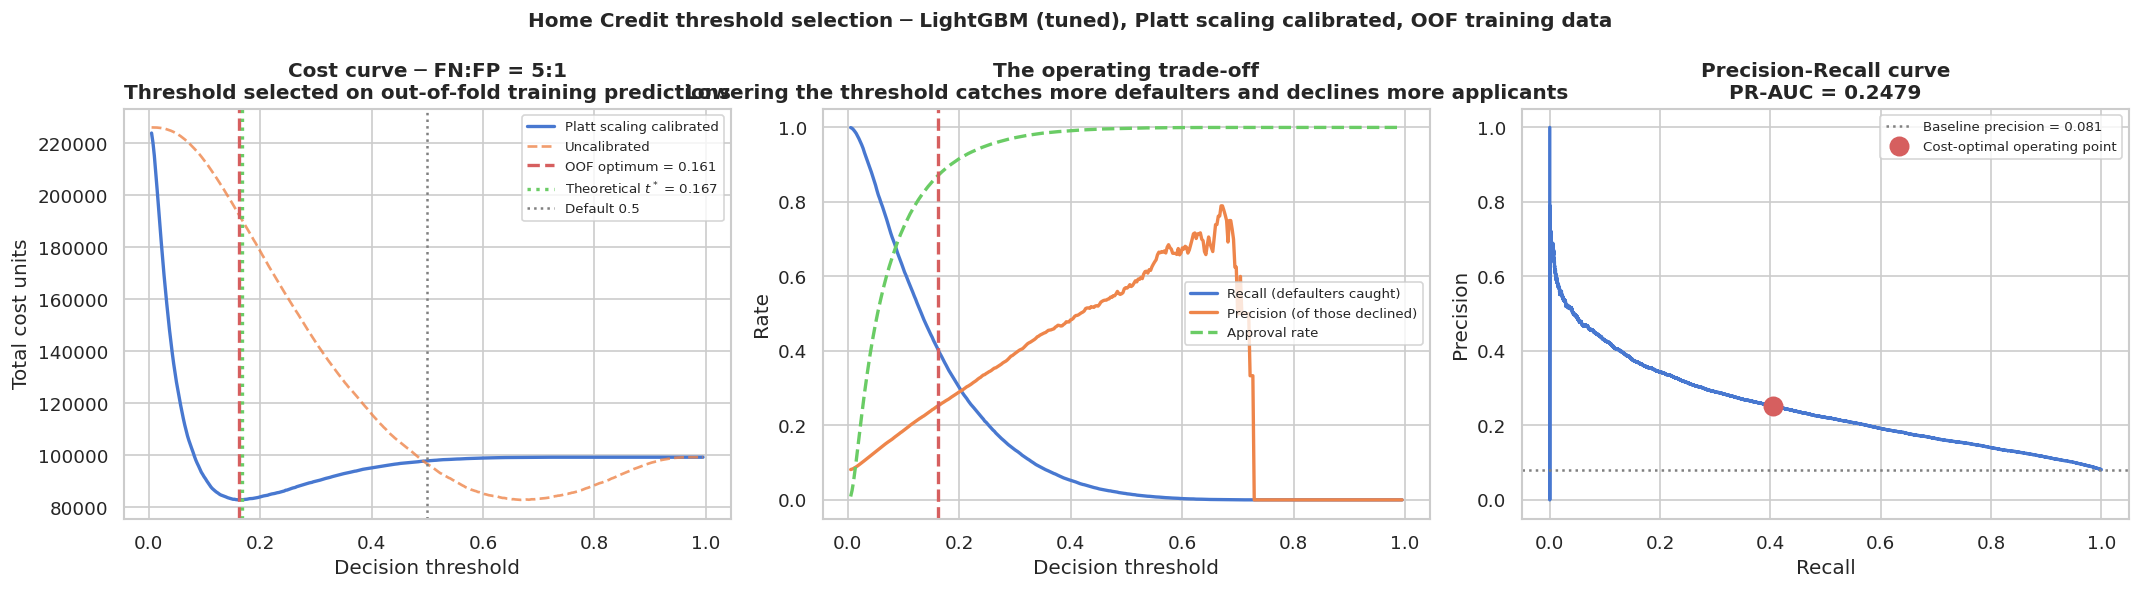

=== THRESHOLD ANALYSIS (FN cost = 5, FP cost = 1) ===
Threshold                    Total cost    Recall   Precision   Approval
------------------------------------------------------------------------
Default (0.500)                  24,463     0.017       0.592      99.8%
OOF-selected (0.161)             20,186     0.426       0.263      86.9%
------------------------------------------------------------------------
Saving vs 0.5 on test             4,277 cost units

Theoretical optimum for a calibrated model: c_FP / (c_FP + c_FN) = 0.1667
OOF empirical optimum found:                0.1613
Discrepancy:                                0.0054

The threshold was selected from out-of-fold TRAINING probabilities only.
The held-out Home Credit test set is used only to measure the performance
of that already-fixed operating threshold.

BUSINESS READING: at the OOF-selected threshold the model catches
43% of defaulters, but only 26% of
those declined actually defaulted, and the approval rate is


In [ ]:
# A6 Step 8 — Select a cost-sensitive decision threshold from training evidence
# Select the operating threshold from out-of-fold training probabilities.
COST_FN = 5    # cost of approving an applicant who then defaults
COST_FP = 1    # cost of declining an applicant who would have repaid

if CAL_METHOD == 'Platt scaling':
    train_probs_cal = platt_oof
else:
    train_probs_cal = iso_oof

train_probs_raw = oof_probs[BEST_MODEL_NAME]

y_train = y_tr.values
y_test  = y_te.values
thresholds = np.linspace(0.005, 0.995, 400)


def cost_curve(y_true, probs):
    costs, recalls, precisions, approve = [], [], [], []
    for t in thresholds:
        pred = (probs >= t).astype(int)
        fn = int(((pred == 0) & (y_true == 1)).sum())
        fp = int(((pred == 1) & (y_true == 0)).sum()) # Removed extra ')'
        tp = int(((pred == 1) & (y_true == 1)).sum()) # Removed extra ')'
        costs.append(fn * COST_FN + fp * COST_FP)
        recalls.append(tp / max(tp + fn, 1))
        precisions.append(tp / max(tp + fp, 1))
        approve.append((pred == 0).mean())
    return (np.array(costs), np.array(recalls),
            np.array(precisions), np.array(approve))


cost_cal, rec_cal, prec_cal, appr_cal = cost_curve(y_train, train_probs_cal)
cost_raw, _, _, _                     = cost_curve(y_train, train_probs_raw)

opt_i      = int(np.argmin(cost_cal))
opt_t      = thresholds[opt_i]
opt_cost   = cost_cal[opt_i]
half_i     = int(np.argmin(np.abs(thresholds - 0.5)))
half_cost  = cost_cal[half_i]
theory_t   = COST_FP / (COST_FP + COST_FN)


test_costs, test_recalls, test_precisions, test_approvals = cost_curve(y_test, test_probs_cal)

half_test = {
    "cost": test_costs[half_i],
    "recall": test_recalls[half_i],
    "precision": test_precisions[half_i],
    "approval": test_approvals[half_i]
}

opt_test = {
    "cost": test_costs[opt_i],
    "recall": test_recalls[opt_i],
    "precision": test_precisions[opt_i],
    "approval": test_approvals[opt_i]
}


fig, axes = plt.subplots(1, 3, figsize=(18, 5))


# Panel 1: cost curve, calibrated vs uncalibrated
axes[0].plot(thresholds, cost_cal, color=BLUE, lw=2,
             label=f'{CAL_METHOD} calibrated')
axes[0].plot(thresholds, cost_raw, color=ORANGE, lw=1.6, ls='--', alpha=0.8,
             label='Uncalibrated')
axes[0].axvline(opt_t, color=RED, ls='--', lw=2,
                label=f'OOF optimum = {opt_t:.3f}')
axes[0].axvline(theory_t, color=GREEN, ls=':', lw=2,
                label=f'Theoretical $t^*$ = {theory_t:.3f}')
axes[0].axvline(0.5, color='grey', ls=':', lw=1.5,
                label='Default 0.5')
axes[0].set_xlabel('Decision threshold')
axes[0].set_ylabel('Total cost units')
axes[0].set_title(f'Cost curve ─ FN:FP = {COST_FN}:{COST_FP}\n'
                  'Threshold selected on out-of-fold training predictions',
                  fontweight='bold')
axes[0].legend(fontsize=8)


# Panel 2: what the threshold does to recall and precision
axes[1].plot(thresholds, rec_cal, color=BLUE, lw=2,
             label='Recall (defaulters caught)')
axes[1].plot(thresholds, prec_cal, color=ORANGE, lw=2,
             label='Precision (of those declined)')
axes[1].plot(thresholds, appr_cal, color=GREEN, lw=2, ls='--',
             label='Approval rate')
axes[1].axvline(opt_t, color=RED, ls='--', lw=2)
axes[1].set_xlabel('Decision threshold')
axes[1].set_ylabel('Rate')
axes[1].set_title('The operating trade-off\n'
                  'Lowering the threshold catches more defaulters and declines more applicants',
                  fontweight='bold')
axes[1].legend(fontsize=8)


# Panel 3: OOF precision-recall curve with operating point marked
prec_c, rec_c, thr_c = precision_recall_curve(y_train, train_probs_cal)

axes[2].plot(rec_c, prec_c, color=BLUE, lw=2)
axes[2].axhline(y_train.mean(), color='grey', ls=':', lw=1.5,
                label=f'Baseline precision = {y_train.mean():.3f}')
axes[2].plot(rec_cal[opt_i], prec_cal[opt_i], 'o', color=RED, ms=11,
             zorder=5, label='Cost-optimal operating point')
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].set_title(f'Precision-Recall curve\nPR-AUC = '
                  f'{average_precision_score(y_train, train_probs_cal):.4f}',
                  fontweight='bold')
axes[2].legend(fontsize=8)


plt.suptitle(f'Home Credit threshold selection ─ {BEST_MODEL_NAME}, '
             f'{CAL_METHOD} calibrated, OOF training data',
             fontweight='bold', fontsize=12)
plt.tight_layout()
plt.savefig('/content/a6_threshold.png', dpi=300, bbox_inches='tight')
plt.show()

print(f'=== THRESHOLD ANALYSIS (FN cost = {COST_FN}, FP cost = {COST_FP}) ===')
print(f'{"Threshold":<26} {"Total cost":>12} {"Recall":>9} {"Precision":>11} {"Approval":>10}')
print('-' * 72)

print(f'{"Default (0.500) ":<26} {half_test["cost"]:>12,.0f}'
      f' {half_test["recall"]:>9.3f} {half_test["precision"]:>11.3f}'
      f' {half_test["approval"] * 100:>9.1f}%')

print(f'{f"OOF-selected ({opt_t:.3f})":<26} {opt_test["cost"]:>12,.0f}'
      f' {opt_test["recall"]:>9.3f} {opt_test["precision"]:>11.3f}'
      f' {opt_test["approval"] * 100:>9.1f}%')

print('-' * 72)
print(f'{"Saving vs 0.5 on test":<26}'
      f' {half_test["cost"] - opt_test["cost"]:>12,.0f} cost units')

print()
print(f'Theoretical optimum for a calibrated model: '
      f'c_FP / (c_FP + c_FN) = {theory_t:.4f}')
print(f'OOF empirical optimum found:                {opt_t:.4f}')
print(f'Discrepancy:                                {abs(opt_t - theory_t):.4f}')

print()
print('The threshold was selected from out-of-fold TRAINING probabilities only.')
print('The held-out Home Credit test set is used only to measure the performance')
print('of that already-fixed operating threshold.')

print()
print(f'BUSINESS READING: at the OOF-selected threshold the model catches')
print(f'{opt_test["recall"] * 100:.0f}% of defaulters, but only '
      f'{opt_test["precision"] * 100:.0f}% of')
print(f'those declined actually defaulted, and the approval rate is')
print(f'{opt_test["approval"] * 100:.0f}%. Whether a lender accepts that trade-off is')
print('a commercial judgement encoded by the assumed cost ratio.')
print()
print('NOTE: the 5:1 FN-to-FP ratio is an analytical assumption, not a value')
print('provided by the Home Credit dataset; sensitivity analysis should be reported.')


**Output explanation.** With a false-negative cost set to five times the false-positive cost, the training data selects a threshold of **0.1613**. On the held-out test set, this threshold gives **42.6% recall**, **26.3% precision** and an **86.9% approval rate**, while reducing the assumed cost by **4,277 units** compared with a 0.5 threshold. The 5:1 cost ratio is an analysis assumption and must be checked against real business costs before use.

### A6 wrap-up

LightGBM remains the development winner, with XGBoost very close. LightGBM needs probability calibration, subgroup differences need monitoring, SMOTENC does not improve the main results, and the final threshold depends on the assumed business cost of errors.

---
# A7 — Model Explanation with SHAP

A7 compares feature importance across the strongest classical, ensemble and neural models. It then explains the leading LightGBM model both overall and for one applicant. SHAP explains model behaviour; it does not prove cause and effect.

### A7 Step 1 — Calculate SHAP values for the best model from each family

In [ ]:
# A7 Step 1 — Compute SHAP values for the best model from each family
# Explain the same held-out sample across the three model families.

CLASSICAL = ['Logistic Regression (tuned)', 'SVM (linear, tuned)',
             'k-NN (tuned)', 'Naive Bayes (tuned)']
ENSEMBLES = ['Random Forest (tuned)', 'XGBoost (tuned)', 'LightGBM (tuned)']
NEURALS   = ['MLP Keras (tuned)', 'MLP PyTorch (tuned)']

best_classical = max([m for m in CLASSICAL if m in fold_scores],
                     key=lambda m: fold_scores[m].mean())
best_ensemble  = max([m for m in ENSEMBLES if m in fold_scores],
                     key=lambda m: fold_scores[m].mean())
best_neural    = max([m for m in NEURALS if m in fold_scores],
                     key=lambda m: fold_scores[m].mean())

print('=== BEST HOME CREDIT MODEL OF EACH CLASS ===')
for label, name in [('Classical', best_classical), ('Ensemble', best_ensemble),
                    ('Neural',    best_neural)]:
    print(f'  {label:<11} {name:<28} AUC = {fold_scores[name].mean():.4f}')
print()


# Fitted preprocessor for classical and ensemble explainers
prep_shap = clone(prep_sel).fit(X_tr_sel, y_tr)
X_tr_shap = prep_shap.transform(X_tr_sel).astype('float32')
X_te_shap = prep_shap.transform(X_te_sel).astype('float32')
SHAP_NAMES, _ = ohe_name_to_source(prep_shap, sel_cat)

# One identical explanation sample for every model
rng = np.random.default_rng(RANDOM_STATE)

SHAP_N = min(120, len(X_te_shap))
shap_idx = rng.choice(len(X_te_shap), size=SHAP_N, replace=False)

X_explain    = X_te_shap[shap_idx]
X_explain_nn = X_te_nn[shap_idx]

print(f'Explanation sample: {SHAP_N:,} Home Credit test applicants, '
      f'{X_explain.shape[1]} transformed columns')
print()

shap_values = {}     # model name -> (n_explain, n_features) array
shap_bases  = {}     # model name -> expected probability


# 1. Classical model
print(f'[1/3] {best_classical} ...')
t0 = time.time()

clf_cls = clone(tuned_models[best_classical].named_steps['clf'])
clf_cls.fit(X_tr_shap, y_tr)

bg_cls = shap.kmeans(X_tr_shap, 40)

expl_cls = shap.KernelExplainer(
    lambda z: clf_cls.predict_proba(z)[:, 1],
    bg_cls
)

sv_cls = expl_cls.shap_values(
    X_explain,
    nsamples=200,
    silent=True
)

sv_cls = np.array(sv_cls)

if sv_cls.ndim == 3:
    sv_cls = sv_cls[:, :, 0]

base_cls = float(np.atleast_1d(expl_cls.expected_value)[0])

shap_values[best_classical] = sv_cls
shap_bases[best_classical] = base_cls

print(f'      KernelExplainer (probability space, {SHAP_N} rows)'
      f'  --  {time.time() - t0:.0f}s')


# 2. Ensemble model
# 3. Neural network
print(f'[2/3] {best_ensemble} ...')
t0 = time.time()

clf_ens = clone(tuned_models[best_ensemble].named_steps['clf'])
clf_ens.fit(X_tr_shap, y_tr)

bg_n = min(200, len(X_tr_shap))
bg_idx = rng.choice(len(X_tr_shap), size=bg_n, replace=False)

expl_ens = shap.TreeExplainer(
    clf_ens,
    data=X_tr_shap[bg_idx],
    feature_perturbation='interventional',
    model_output='probability'
)

sv_ens = expl_ens.shap_values(X_explain)

if isinstance(sv_ens, list):
    sv_ens = sv_ens[1]

sv_ens = np.array(sv_ens)

if sv_ens.ndim == 3:
    sv_ens = sv_ens[:, :, 1]

base_ens = np.atleast_1d(expl_ens.expected_value)
base_ens = float(base_ens[-1])

shap_values[best_ensemble] = sv_ens
shap_bases[best_ensemble] = base_ens

print(f'      TreeExplainer (probability space)  --  '
      f'{time.time() - t0:.0f}s')


print(f'[3/3] {best_neural} (KernelExplainer -- the slow one) ...')
t0 = time.time()

bg_nn = shap.kmeans(X_fin_tr_nn, 40)

if best_neural.startswith('MLP Keras'):

    nn_predict = lambda z: keras_final.predict(
        np.asarray(z, dtype='float32'),
        verbose=0
    ).ravel()

else:

    def nn_predict(z):
        torch_final.eval()
        with torch.no_grad():
            z_t = torch.tensor(np.asarray(z), dtype=torch.float32,
                               device=DEVICE)
            return torch_final(z_t).cpu().numpy().ravel()


expl_nn = shap.KernelExplainer(
    nn_predict,
    bg_nn
)

sv_nn = expl_nn.shap_values(
    X_explain_nn,
    nsamples=200,
    silent=True
)

sv_nn = np.array(sv_nn)

if sv_nn.ndim == 3:
    sv_nn = sv_nn[:, :, 0]

base_nn = float(np.atleast_1d(expl_nn.expected_value)[0])

shap_values[best_neural] = sv_nn
shap_bases[best_neural] = base_nn

print(f'      KernelExplainer (probability space, {SHAP_N} rows)'
      f'  --  {time.time() - t0:.0f}s')


print()
print('=== SHAP MATRICES ===')

for name, sv in shap_values.items():
    print(f'  {name:<28} SHAP matrix {sv.shape}')


=== BEST HOME CREDIT MODEL OF EACH CLASS ===
  Classical   SVM (linear, tuned)          AUC = 0.7466
  Ensemble    LightGBM (tuned)             AUC = 0.7621
  Neural      MLP Keras (tuned)            AUC = 0.7523

Explanation sample: 120 Home Credit test applicants, 98 transformed columns

[1/3] SVM (linear, tuned) ...
      KernelExplainer (probability space, 120 rows)  --  76s
[2/3] LightGBM (tuned) ...


      TreeExplainer (probability space)  --  6s
[3/3] MLP Keras (tuned) (KernelExplainer -- the slow one) ...
      KernelExplainer (probability space, 120 rows)  --  121s

=== SHAP MATRICES ===
  SVM (linear, tuned)          SHAP matrix (120, 98)
  LightGBM (tuned)             SHAP matrix (120, 98)
  MLP Keras (tuned)            SHAP matrix (120, 98)


**Output explanation.** The strongest model from each family is SVM for the classical group, LightGBM for ensembles and Keras MLP for neural networks. SHAP values are calculated for the same **120 held-out applicants** and the same **98 transformed features**, so the explanations are compared on a common sample.

### A7 Step 2 — Compare overall SHAP importance across model families

Compare normalised average SHAP importance to see whether the three model families rely on similar features.

=== SHAP RANK AGREEMENT ACROSS MODEL FAMILIES ===
SVM (linear, tuned)          vs LightGBM (tuned)              Spearman = +0.853  p = 0.0000
SVM (linear, tuned)          vs MLP Keras (tuned)             Spearman = +0.899  p = 0.0000
LightGBM (tuned)             vs MLP Keras (tuned)             Spearman = +0.884  p = 0.0000

Top 15 transformed features by mean normalised SHAP importance:


,"SVM (linear, tuned)",LightGBM (tuned),MLP Keras (tuned),mean_normalised
EXT_SOURCE_2,0.862,1.000,0.950,0.937
EXT_SOURCE_3,0.828,0.926,1.000,0.918
AMT_GOODS_PRICE,1.000,0.521,0.210,0.577
EXT_SOURCE_1,0.234,0.534,0.354,0.374
AMT_CREDIT,0.797,0.197,0.035,0.343
pos_instalment_future_mean,0.240,0.406,0.376,0.341
previous_refused_rate,0.218,0.325,0.267,0.270
credit_goods_gap,0.111,0.404,0.294,0.270
AMT_ANNUITY,0.187,0.325,0.292,0.268
CODE_GENDER_M,0.195,0.272,0.203,0.223


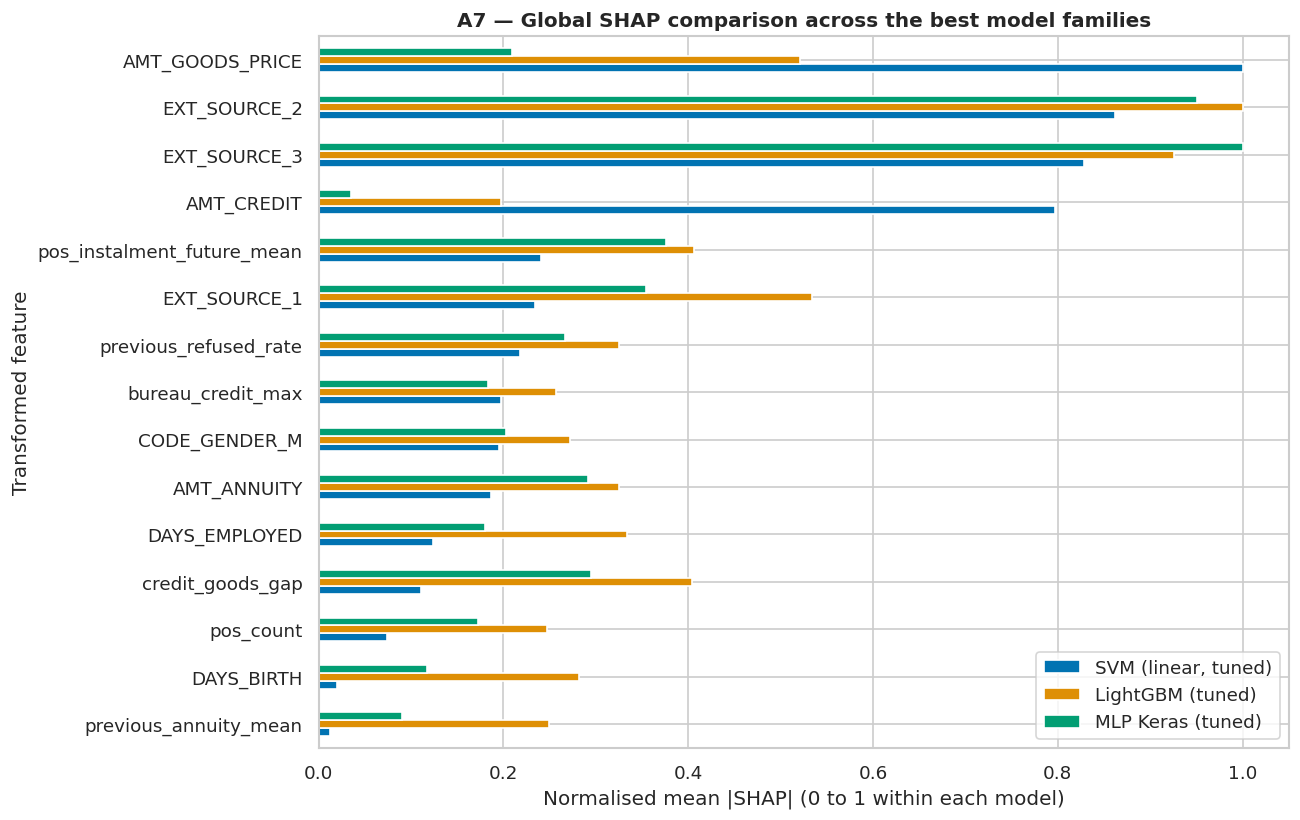

In [ ]:
# A7 Step 2 — Compare global SHAP importance across the three model families

global_shap = pd.DataFrame({
    name: np.mean(np.abs(values), axis=0)
    for name, values in shap_values.items()
}, index=SHAP_NAMES)

global_shap_norm = global_shap.divide(
    global_shap.max(axis=0).replace(0, np.nan),
    axis=1
).fillna(0)

rank_table = global_shap.rank(ascending=False, method='average')

print('=== SHAP RANK AGREEMENT ACROSS MODEL FAMILIES ===')
for a, b in combinations(global_shap.columns, 2):
    rho, p = stats.spearmanr(rank_table[a], rank_table[b])
    print(f'{a:<28} vs {b:<28}  Spearman = {rho:+.3f}  p = {p:.4f}')

global_shap_norm['mean_normalised'] = global_shap_norm.mean(axis=1)
top_features = (
    global_shap_norm
    .sort_values('mean_normalised', ascending=False)
    .head(15)
)

print()
print('Top 15 transformed features by mean normalised SHAP importance:')
display(top_features.round(3))

plot_df = (
    top_features
    .drop(columns='mean_normalised')
    .sort_values(by=top_features.columns[0])
)

ax = plot_df.plot(
    kind='barh',
    figsize=(11, 7)
)
ax.set_title(
    'A7 — Global SHAP comparison across the best model families',
    fontweight='bold'
)
ax.set_xlabel('Normalised mean |SHAP| (0 to 1 within each model)')
ax.set_ylabel('Transformed feature')
plt.tight_layout()
plt.show()


**Output explanation.** The SHAP importance rankings are strongly related across the three model families, with Spearman correlations from **0.853 to 0.899**. `EXT_SOURCE_2` and `EXT_SOURCE_3` are among the most important features across all three models. This suggests that the models rely on several similar signals, although SHAP shows model behaviour rather than cause and effect.

### A7 Step 3 — Show direction as well as importance with a beeswarm

The beeswarm shows both how important a feature is and whether its values tend to push predicted default risk higher or lower.

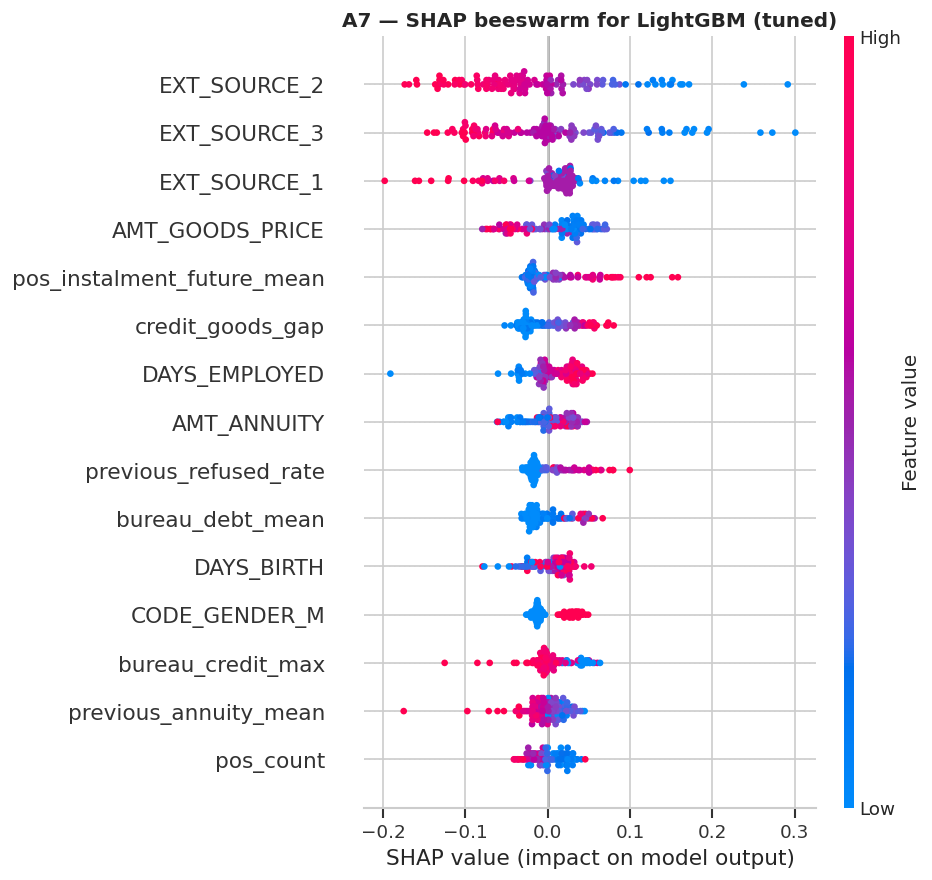

In [ ]:
# A7 Step 3 — Beeswarm for the leading ensemble model

ensemble_sv = shap_values[best_ensemble]

shap.summary_plot(
    ensemble_sv,
    X_explain,
    feature_names=SHAP_NAMES,
    max_display=15,
    show=False
)
plt.title(
    f'A7 — SHAP beeswarm for {best_ensemble}',
    fontweight='bold'
)
plt.tight_layout()
plt.show()


**Output explanation.** The beeswarm chart shows which features have the largest effect on LightGBM predictions and the direction of that effect. Features near the top matter more overall; points to the right push the model toward higher predicted default risk, while points to the left push it toward lower predicted risk.

### A7 Step 3b — Examine the top LightGBM feature in more detail

Plot the strongest LightGBM feature against its SHAP contribution to see the shape of the model relationship.

A7 Step 3b done.
  Highest-importance ensemble feature: EXT_SOURCE_2


<Figure size 1200x720 with 0 Axes>

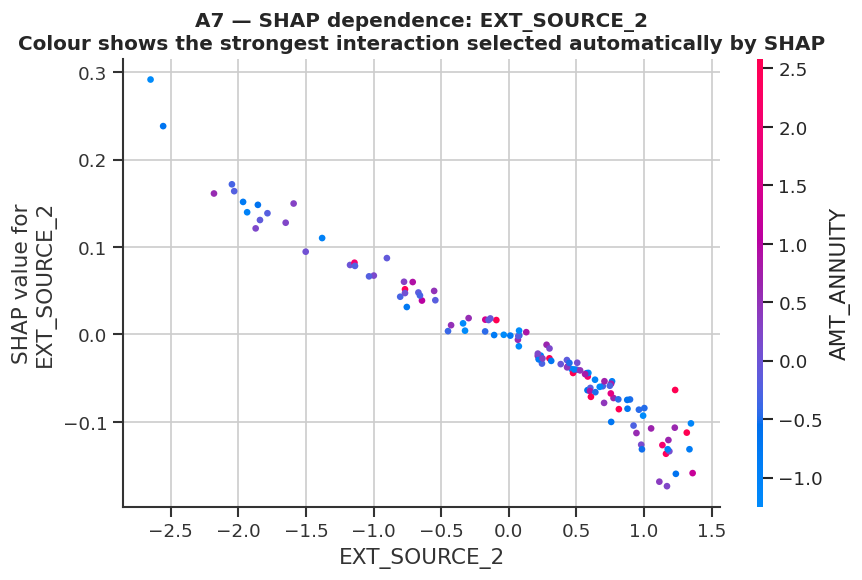


Read this plot for two things:
  1. whether the SHAP effect changes smoothly or jumps at a threshold;
  2. whether the colour split suggests an interaction with another feature.


In [ ]:
# A7 Step 3b: plot SHAP dependence for the strongest ensemble feature.

ensemble_sv = shap_values[best_ensemble]

top_feature_index = int(
    np.argmax(
        np.abs(ensemble_sv).mean(axis=0)
    )
)

top_feature_name = SHAP_NAMES[top_feature_index]

print('A7 Step 3b done.')
print(f'  Highest-importance ensemble feature: {top_feature_name}')

plt.figure(figsize=(10, 6))

shap.dependence_plot(
    top_feature_index,
    ensemble_sv,
    X_explain[:ensemble_sv.shape[0]],
    feature_names=SHAP_NAMES[:ensemble_sv.shape[1]],
    show=False
)

plt.title(
    f'A7 — SHAP dependence: {top_feature_name}\n'
    'Colour shows the strongest interaction selected automatically by SHAP',
    fontweight='bold'
)

plt.tight_layout()
plt.savefig('/content/a7_dependence.png', dpi=300, bbox_inches='tight')
plt.show()

print()
print('Read this plot for two things:')
print('  1. whether the SHAP effect changes smoothly or jumps at a threshold;')
print('  2. whether the colour split suggests an interaction with another feature.')


**Output explanation.** `EXT_SOURCE_2` is the most important LightGBM feature in this SHAP analysis. The dependence plot shows how its SHAP effect changes across its values and whether another feature may change that pattern. It should be read as a description of the model, not as proof that changing `EXT_SOURCE_2` would cause risk to change.

### A7 Step 4 — Explain one applicant and the decision margin

Choose a useful held-out example, show how close its calibrated probability is to the operating threshold, and list the SHAP contributions that move the model score up or down.

=== ONE-APPLICANT EXPLANATION ===
Case chosen: false positive at the selected operating threshold
Held-out row position: 16999
Actual TARGET: 0
Calibrated default probability: 0.1664
Operating threshold:            0.1613
Decision:                       DECLINE / HIGHER RISK
Margin from threshold:          +0.0051

A probability movement of 0.0051 in the opposite direction would cross the threshold. This is a decision-margin statement, not a causal counterfactual.

Largest risk-increasing contributions:


,feature,value,shap
16,pos_instalment_future_mean,6.1695,0.1512
10,EXT_SOURCE_3,-0.6147,0.0608
9,EXT_SOURCE_2,-0.7671,0.0515
13,bureau_debt_mean,0.6479,0.0400
3,AMT_CREDIT,2.9813,0.0317
7,DAYS_EMPLOYED,0.5962,0.0294
17,CODE_GENDER_M,1.0000,0.0271
6,DAYS_BIRTH,0.4627,0.0168


Largest risk-reducing contributions:


,feature,value,shap
2,previous_annuity_mean,0.7771,-0.0717
5,AMT_GOODS_PRICE,3.4144,-0.0694
11,credit_goods_gap,-0.8042,-0.0267
14,previous_refused_rate,-0.5802,-0.0169
32,OCCUPATION_TYPE_Managers,1.0000,-0.0070
30,OCCUPATION_TYPE_Laborers,0.0000,-0.0018
8,EXT_SOURCE_1,-0.3602,-0.0016
45,ORGANIZATION_TYPE_Business Entity Type 3,0.0000,-0.0015


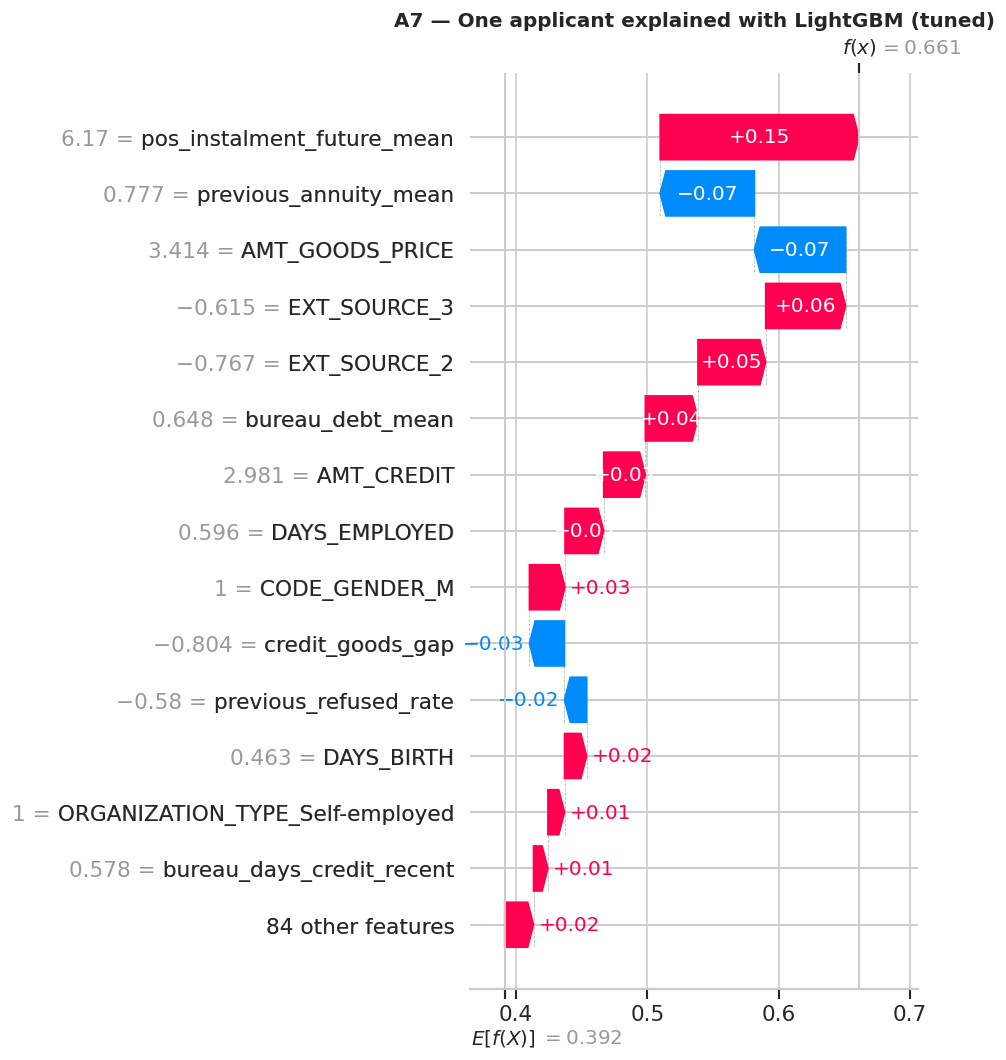

In [ ]:
# A7 Step 4 — Explain one applicant and show the distance to the decision threshold
# Prefer a false-positive example when available, otherwise use the case nearest the threshold.

sample_targets = y_te.iloc[shap_idx].to_numpy()
sample_cal_probs = np.asarray(test_probs_cal)[shap_idx]

false_positive_pos = np.where(
    (sample_cal_probs >= opt_t) & (sample_targets == 0)
)[0]

if len(false_positive_pos):
    local_pos = int(false_positive_pos[0])
    case_reason = 'false positive at the selected operating threshold'
else:
    local_pos = int(np.argmin(np.abs(sample_cal_probs - opt_t)))
    case_reason = 'sampled applicant closest to the selected operating threshold'

global_test_pos = int(shap_idx[local_pos])
cal_prob = float(sample_cal_probs[local_pos])
actual = int(sample_targets[local_pos])
decision = 'DECLINE / HIGHER RISK' if cal_prob >= opt_t else 'APPROVE / LOWER RISK'
margin = cal_prob - opt_t

local_sv = shap_values[best_ensemble][local_pos]
local_x = X_explain[local_pos]
local_base = shap_bases[best_ensemble]

explanation = shap.Explanation(
    values=local_sv,
    base_values=local_base,
    data=local_x,
    feature_names=SHAP_NAMES
)

print('=== ONE-APPLICANT EXPLANATION ===')
print(f'Case chosen: {case_reason}')
print(f'Held-out row position: {global_test_pos}')
print(f'Actual TARGET: {actual}')
print(f'Calibrated default probability: {cal_prob:.4f}')
print(f'Operating threshold:            {opt_t:.4f}')
print(f'Decision:                       {decision}')
print(f'Margin from threshold:          {margin:+.4f}')
print()
print(
    'A probability movement of '
    f'{abs(margin):.4f} in the opposite direction would cross the threshold. '
    'This is a decision-margin statement, not a causal counterfactual.'
)

# Top local positive and negative SHAP contributions
local_df = pd.DataFrame({
    'feature': SHAP_NAMES,
    'value': local_x,
    'shap': local_sv
}).sort_values('shap', ascending=False)

print()
print('Largest risk-increasing contributions:')
display(local_df.head(8).round(4))

print('Largest risk-reducing contributions:')
display(local_df.tail(8).sort_values('shap').round(4))

shap.plots.waterfall(explanation, max_display=15, show=False)
plt.title(
    f'A7 — One applicant explained with {best_ensemble}',
    fontweight='bold'
)
plt.tight_layout()
plt.show()


**Output explanation.** The selected example is a false positive: the applicant did not default, but the calibrated risk score is **0.1664**, just above the **0.1613** operating threshold. The margin is only **0.0051**, so the decision is close to the boundary. The table shows which features push the model score up or down for this applicant.

In [ ]:
# A7 Step 4b: check that the local SHAP values reconstruct the raw model output.

raw_reconstructed = float(
    local_base
    +
    np.sum(local_sv)
)

raw_direct = float(
    clf_ens.predict_proba(
        np.asarray(local_x).reshape(1, -1)
    )[:, 1][0]
)

print('=== LOCAL-ACCURACY CHECK ===')
print(f'  Base value:                    {local_base:.6f}')
print(f'  Sum of SHAP contributions:      {np.sum(local_sv):+.6f}')
print(f'  Reconstructed raw probability:  {raw_reconstructed:.6f}')
print(f'  Direct model raw probability:    {raw_direct:.6f}')
print(f'  Absolute reconstruction error:   {abs(raw_reconstructed - raw_direct):.8f}')
print()

largest_risk_row = (
    local_df
    .sort_values('shap', ascending=False)
    .iloc[0]
)

print('=== WHAT WOULD HAVE TO MOVE TO CROSS THE DECISION BOUNDARY? ===')
print(f'  Calibrated probability:          {cal_prob:.4f}')
print(f'  Operating threshold:             {opt_t:.4f}')
print(f'  Required calibrated movement:    {abs(margin):.4f}')
print(f'  Largest risk-increasing feature: {largest_risk_row["feature"]}')
print(f'  Its local SHAP contribution:     {largest_risk_row["shap"]:+.4f}')
print()
print('This identifies the model evidence that currently pushes the applicant most')
print('toward the high-risk side. It is NOT a causal claim that changing that borrower')
print('attribute by itself would change real-world default risk or guarantee approval.')


=== LOCAL-ACCURACY CHECK ===
  Base value:                    0.391535
  Sum of SHAP contributions:      +0.269471
  Reconstructed raw probability:  0.661006
  Direct model raw probability:    0.661006
  Absolute reconstruction error:   0.00000002

=== WHAT WOULD HAVE TO MOVE TO CROSS THE DECISION BOUNDARY? ===
  Calibrated probability:          0.1664
  Operating threshold:             0.1613
  Required calibrated movement:    0.0051
  Largest risk-increasing feature: pos_instalment_future_mean
  Its local SHAP contribution:     +0.1512

This identifies the model evidence that currently pushes the applicant most
toward the high-risk side. It is NOT a causal claim that changing that borrower
attribute by itself would change real-world default risk or guarantee approval.


**Output explanation.** The SHAP values reconstruct the model's raw probability almost exactly, with an error of about **0.00000002**, which confirms local accuracy for this explanation. The calibrated score would need to fall by about **0.0051** to cross the decision threshold. `pos_instalment_future_mean` is the largest risk-increasing contribution in this case, but this is a model explanation and not a causal statement.

### A7 wrap-up

A7 shows which features matter across model families, how feature values affect LightGBM predictions, and why one applicant falls on one side of the decision threshold.

---
# A8 — Final Selection, Saved Model and Model Card

A8 checks final held-out performance, compares deployment trade-offs, saves the selected model bundle and records the conditions under which it should be used.

### A8 Step 1 — Confirm held-out performance and prediction speed

Fit each candidate on all development data, score the held-out test set once, and measure prediction time.

=== FINAL HOME CREDIT TEST-SET EVALUATION AND LATENCY ===
Model                          Test AUC   Test PR   ECE(oof)    Fit s   Pred ms/1k   Fair dAUC
----------------------------------------------------------------------------------------------
Logistic Regression (tuned)      0.7504    0.2338     0.3426      6.2         4.67      0.0142
SVM (linear, tuned)              0.7502    0.2338     0.0023     11.2         7.04      0.0142
k-NN (tuned)                     0.7286    0.2123     0.0044      1.1       587.44      0.0101
Naive Bayes (tuned)              0.6433    0.1218     0.3509      1.5         3.00      0.0052
Random Forest (tuned)            0.7522    0.2353     0.3353     15.4         5.61      0.0151
XGBoost (tuned)                  0.7667    0.2597     0.3120      8.2         3.95      0.0139
LightGBM (tuned)                 0.7673    0.2603     0.3143      4.2         4.46      0.0140
MLP Keras (tuned)                0.7566    0.2428     0.3252       A5        59.19     

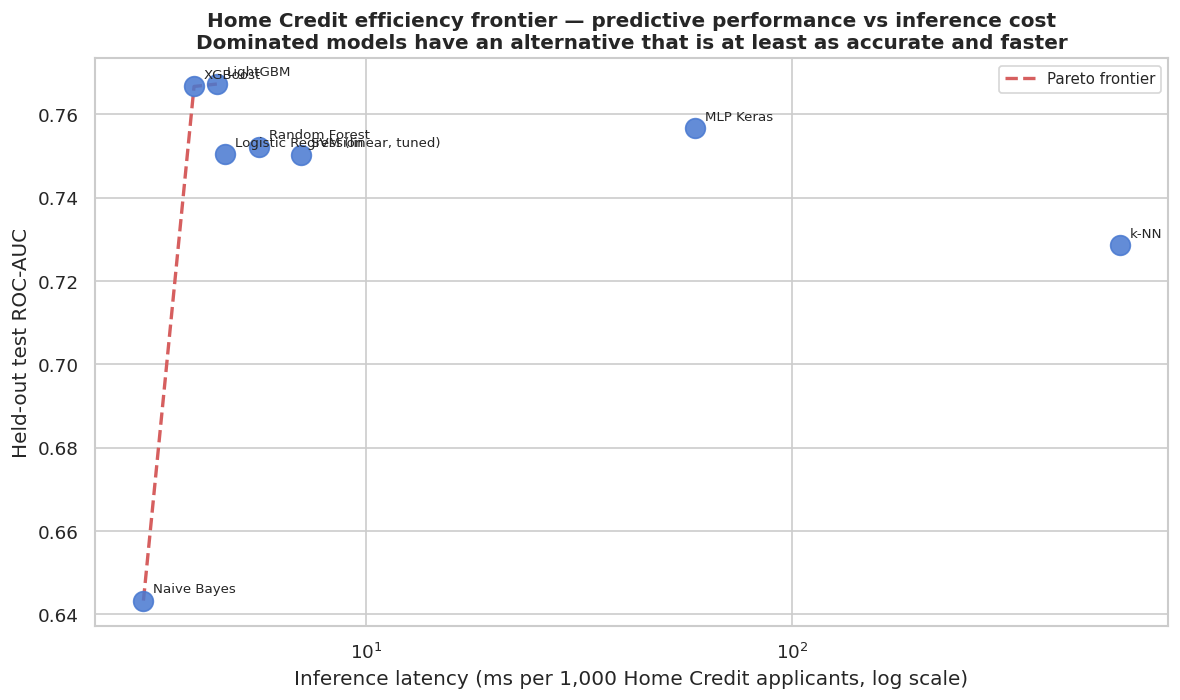


Models ON the Pareto frontier (genuine accuracy-speed trade-offs):
  Naive Bayes (tuned)          AUC 0.6433  at     3.00 ms/1k
  XGBoost (tuned)              AUC 0.7667  at     3.95 ms/1k
  LightGBM (tuned)             AUC 0.7673  at     4.46 ms/1k

Models outside the frontier are dominated on these two deployment dimensions:
another evaluated model provides equal or better test ROC-AUC at lower inference
latency. Other considerations such as calibration, fairness and interpretability
must still be considered before making the final deployment recommendation.


In [ ]:
# A8 Step 1 — Final held-out evaluation and latency
# Use the sealed test set only for final confirmation and latency measurement.
train_gender = df_tr_rel['CODE_GENDER']

LATENCY_SLICE = min(20_000, len(X_te_sel))
X_lat = X_te_sel.iloc[:LATENCY_SLICE]

print('=== FINAL HOME CREDIT TEST-SET EVALUATION AND LATENCY ===')
print(f'{'Model':<28} {'Test AUC':>10} {'Test PR':>9} {'ECE(oof)':>10}'
      f' {'Fit s':>8} {'Pred ms/1k':>12} {'Fair dAUC':>11}')
print('-' * 94)

final_rows = []

for name in STAT_MODELS:

    # Fit and time
    if name == 'MLP Keras (tuned)':

        fit_s = np.nan

        t0 = time.time()
        _ = keras_final.predict(
            X_te_nn[:LATENCY_SLICE],
            verbose=0
        ).ravel()

        pred_ms = (
            (time.time() - t0)
            * 1000
            / LATENCY_SLICE
            * 1000
        )

        te_prob = keras_final.predict(
            X_te_nn,
            verbose=0
        ).ravel()


    elif name == 'MLP PyTorch (tuned)':

        fit_s = np.nan
        torch_final.eval()

        X_lat_t = torch.tensor(
            X_te_nn[:LATENCY_SLICE],
            dtype=torch.float32,
            device=DEVICE
        )

        t0 = time.time()

        with torch.no_grad():
            _ = torch_final(X_lat_t)

        if str(DEVICE).startswith('cuda'):
            torch.cuda.synchronize()

        pred_ms = (
            (time.time() - t0)
            * 1000
            / LATENCY_SLICE
            * 1000
        )

        X_te_t = torch.tensor(
            X_te_nn,
            dtype=torch.float32,
            device=DEVICE
        )

        with torch.no_grad():
            te_prob = (
                torch_final(X_te_t)
                .cpu()
                .numpy()
                .ravel()
            )


    else:

        pipe = clone(
            tuned_models[name]
        )

        t0 = time.time()

        pipe.fit(
            X_tr_sel,
            y_tr
        )

        fit_s = (
            time.time()
            -
            t0
        )


        # Prediction latency on the same number of test applicants
        t0 = time.time()

        _ = pipe.predict_proba(
            X_lat
        )[:, 1]

        pred_ms = (
            (time.time() - t0)
            * 1000
            / LATENCY_SLICE
            * 1000
        )


        te_prob = pipe.predict_proba(
            X_te_sel
        )[:, 1]


    # Fairness dimension: gender AUC disparity on OOF training probs
    oof = oof_probs[name]

    aucs = []

    for g in train_gender.dropna().unique():

        m = (
            train_gender == g
        ).values

        if (
            m.sum() >= 200
            and
            len(np.unique(y_tr.values[m])) == 2
        ):

            aucs.append(
                roc_auc_score(
                    y_tr.values[m],
                    oof[m]
                )
            )


    d_auc = (
        max(aucs) - min(aucs)
        if len(aucs) > 1
        else np.nan
    )


    # Store final model results
    final_rows.append({

        'Model': name,

        'Test_AUC': roc_auc_score(
            y_te,
            te_prob
        ),

        'Test_PR': average_precision_score(
            y_te,
            te_prob
        ),

        'Test_Brier': brier_score_loss(
            y_te,
            te_prob
        ),

        'ECE_oof': compute_ece(
            y_tr.values,
            oof,
            N_BINS_ECE
        ),

        'Fit_s': fit_s,

        'Pred_ms_per_1k': pred_ms,

        'Fairness_dAUC': d_auc,

        'CV_AUC': fold_scores[
            name
        ].mean(),
    })


    r = final_rows[-1]

    fit_display = (
        f'{r["Fit_s"]:>8.1f}'
        if np.isfinite(r['Fit_s'])
        else f'{"A5":>8}'
    )

    print(
        f'{name:<28} '
        f'{r["Test_AUC"]:>10.4f} '
        f'{r["Test_PR"]:>9.4f} '
        f'{r["ECE_oof"]:>10.4f}'
        f' {fit_display} '
        f'{r["Pred_ms_per_1k"]:>12.2f} '
        f'{r["Fairness_dAUC"]:>11.4f}'
    )


final_df = (
    pd.DataFrame(final_rows)
    .sort_values(
        'Test_AUC',
        ascending=False
    )
    .reset_index(drop=True)
)


print()

print(
    '=== CV vs TEST: HOW WELL DID CROSS-VALIDATION ESTIMATE GENERALISATION? ==='
)

print(
    f'{"Model":<28} '
    f'{"CV AUC":>9} '
    f'{"Test AUC":>10} '
    f'{"Gap":>9}'
)

print('-' * 60)


for _, r in final_df.iterrows():

    print(
        f'{r.Model:<28} '
        f'{r.CV_AUC:>9.4f} '
        f'{r.Test_AUC:>10.4f} '
        f'{r.Test_AUC - r.CV_AUC:>+9.4f}'
    )


print()
print('Small positive or negative CV-to-test differences are normal sampling variation.')
print('The final sklearn models are trained on all available training rows whereas each')
print('CV fold trains on only a fraction of them, so a small positive test gap may occur.')
print('A large negative test gap may indicate optimistic CV selection or overfitting and')
print('should be discussed rather than automatically interpreted as model failure.')


fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.scatter(
    final_df['Pred_ms_per_1k'],
    final_df['Test_AUC'],
    s=140,
    color=BLUE,
    alpha=0.85,
    zorder=3
)


for _, r in final_df.iterrows():

    ax.annotate(
        r.Model.replace(
            ' (tuned)',
            ''
        ),

        xy=(
            r.Pred_ms_per_1k,
            r.Test_AUC
        ),

        xytext=(6, 5),

        textcoords='offset points',

        fontsize=8
    )


pareto = []

for _, r in final_df.iterrows():

    dominated = (

        (
            final_df['Test_AUC']
            >=
            r.Test_AUC
        )

        &

        (
            final_df['Pred_ms_per_1k']
            <=
            r.Pred_ms_per_1k
        )

        &

        (
            (
                final_df['Test_AUC']
                >
                r.Test_AUC
            )

            |

            (
                final_df['Pred_ms_per_1k']
                <
                r.Pred_ms_per_1k
            )
        )

    ).any()


    if not dominated:
        pareto.append(r)

pareto_df = (
    pd.DataFrame(pareto)
    .sort_values(
        'Pred_ms_per_1k'
    )
)


ax.plot(
    pareto_df['Pred_ms_per_1k'],
    pareto_df['Test_AUC'],
    '--',
    color=RED,
    lw=2,
    label='Pareto frontier',
    zorder=2
)


ax.set_xscale(
    'log'
)

ax.set_xlabel(
    'Inference latency (ms per 1,000 Home Credit applicants, log scale)'
)

ax.set_ylabel(
    'Held-out test ROC-AUC'
)

ax.set_title(
    'Home Credit efficiency frontier — predictive performance vs inference cost\n'
    'Dominated models have an alternative that is at least as accurate and faster',
    fontweight='bold'
)

ax.legend(
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    '/content/a8_home_credit_efficiency_frontier.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


print()

print(
    'Models ON the Pareto frontier '
    '(genuine accuracy-speed trade-offs):'
)


for _, r in pareto_df.iterrows():

    print(
        f'  {r.Model:<28} '
        f'AUC {r.Test_AUC:.4f}  at '
        f'{r.Pred_ms_per_1k:>8.2f} ms/1k'
    )


print()

print('Models outside the frontier are dominated on these two deployment dimensions:')
print('another evaluated model provides equal or better test ROC-AUC at lower inference')
print('latency. Other considerations such as calibration, fairness and interpretability')
print('must still be considered before making the final deployment recommendation.')


**Output explanation.** LightGBM has the highest held-out ROC-AUC at **0.7673** and PR-AUC at **0.2603**, with XGBoost very close at **0.7667** and **0.2597**. XGBoost is slightly faster at about **3.95 ms per 1,000 applicants**, compared with **4.46 ms** for LightGBM. The test results are close to the cross-validation results, which supports the stability of the development comparison.

### A8 Step 2 — Keep the recommendation based on development evidence

Show cross-validation and test results side by side, but do not choose a new model only because of a very small held-out difference. The test set is used to confirm the earlier development choice.

In [ ]:
# A8 Step 2 — Build a transparent final decision table
# Keep development and held-out results separate in the final comparison.

# Cross-validated PR-AUC from the existing leaderboard
cv_summary = (
    pd.DataFrame(leaderboard)
    .drop_duplicates(subset='Model', keep='last')
    .set_index('Model')
)

decision_table = final_df.copy()
decision_table['CV_PR_AUC'] = decision_table['Model'].map(cv_summary['PR_AUC'])
decision_table['Development_winner'] = (
    decision_table['Model'] == BEST_MODEL_NAME
)

# Add the calibrated result only to the model for which calibration was selected
decision_table['Calibrated_test_ECE'] = np.nan
decision_table.loc[
    decision_table['Model'] == BEST_MODEL_NAME,
    'Calibrated_test_ECE'
] = cal_ece

decision_table = decision_table[
    [
        'Model', 'CV_AUC', 'CV_PR_AUC',
        'Test_AUC', 'Test_PR',
        'Pred_ms_per_1k', 'Fairness_dAUC',
        'Calibrated_test_ECE', 'Development_winner'
    ]
].sort_values('CV_AUC', ascending=False)

print('=== A8 FINAL DECISION TABLE ===')
display(decision_table.round(4))

RECOMMENDED = BEST_MODEL_NAME

print()
print(f'RECOMMENDED MODEL: {RECOMMENDED}')
print(
    'Reason: it was selected from shared development cross-validation before '
    'the sealed test labels were used, it remains competitive on the held-out '
    'test set, and its probability calibration was explicitly corrected.'
)

assert RECOMMENDED == BEST_MODEL_NAME


=== A8 FINAL DECISION TABLE ===


,Model,CV_AUC,CV_PR_AUC,Test_AUC,Test_PR,Pred_ms_per_1k,Fairness_dAUC,Calibrated_test_ECE,Development_winner
0,LightGBM (tuned),0.7621,0.2485,0.7673,0.2603,4.4641,0.0140,0.0031,True
1,XGBoost (tuned),0.7618,0.2475,0.7667,0.2597,3.9457,0.0139,NaN,False
2,MLP Keras (tuned),0.7523,0.2338,0.7566,0.2428,59.1935,0.0122,NaN,False
3,Random Forest (tuned),0.7487,0.2264,0.7522,0.2353,5.6087,0.0151,NaN,False
5,"SVM (linear, tuned)",0.7466,0.2226,0.7502,0.2338,7.0370,0.0142,NaN,False
4,Logistic Regression (tuned),0.7466,0.2224,0.7504,0.2338,4.6659,0.0142,NaN,False
6,k-NN (tuned),0.7263,0.2066,0.7286,0.2123,587.4410,0.0101,NaN,False
7,Naive Bayes (tuned),0.6384,0.1225,0.6433,0.1218,3.0014,0.0052,NaN,False



RECOMMENDED MODEL: LightGBM (tuned)
Reason: it was selected from shared development cross-validation before the sealed test labels were used, it remains competitive on the held-out test set, and its probability calibration was explicitly corrected.


**Output explanation.** The final table keeps development and held-out results separate. LightGBM remains the recommended model because it was the development winner before the held-out labels were used, and it also performs slightly better than XGBoost on the current test results. Its calibrated test ECE is **0.0031**, showing that the calibration step works well.

### A8 Step 2b — Compare deployment trade-offs

Put performance, statistical standing, calibration, subgroup difference, prediction speed and interpretability on the same 1–5 scale. Compare both equal weights and a weighting that gives more importance to regulated-deployment concerns.

In [ ]:
# A8 Step 2b-i: map raw measures onto a common 1-5 scale.

def scale_higher_is_better(series):
    lo, hi = series.min(), series.max()
    if hi == lo:
        return pd.Series(3.0, index=series.index)
    return 1 + 4 * (series - lo) / (hi - lo)


def scale_lower_is_better(series):
    lo, hi = series.min(), series.max()
    if hi == lo:
        return pd.Series(3.0, index=series.index)
    return 5 - 4 * (series - lo) / (hi - lo)


print('A8 Step 2b-i done: common 1-5 scoring tools defined.')


A8 Step 2b-i done: common 1-5 scoring tools defined.


**Output explanation.** The notebook has defined a common **1-to-5 scoring scale** so different deployment measures can be compared in the same table. A higher score will mean a better result for that measure.

In [ ]:
# A8 Step 2b-ii: score the measurable deployment dimensions.

selection_table = final_df.set_index('Model').copy()

performance_score = scale_higher_is_better(
    selection_table['CV_AUC']
)

calibration_score = scale_lower_is_better(
    selection_table['ECE_oof']
)

fairness_score = scale_lower_is_better(
    selection_table['Fairness_dAUC'].fillna(
        selection_table['Fairness_dAUC'].mean()
    )
)

latency_score = scale_lower_is_better(
    np.log10(
        selection_table['Pred_ms_per_1k']
        +
        1e-6
    )
)

print('A8 Step 2b-ii done: performance, calibration, fairness and latency scored.')

display(
    pd.DataFrame({
        'Performance': performance_score,
        'Calibration': calibration_score,
        'Fairness': fairness_score,
        'Latency': latency_score
    }).round(2)
)


A8 Step 2b-ii done: performance, calibration, fairness and latency scored.


,Performance,Calibration,Fairness,Latency
Model,,,,
LightGBM (tuned),5.00,1.42,1.44,4.70
XGBoost (tuned),4.99,1.45,1.45,4.79
MLP Keras (tuned),4.68,1.30,2.17,2.74
Random Forest (tuned),4.57,1.18,1.00,4.53
Logistic Regression (tuned),4.50,1.10,1.34,4.67
"SVM (linear, tuned)",4.50,5.00,1.33,4.35
k-NN (tuned),3.84,4.98,3.02,1.00
Naive Bayes (tuned),1.00,1.00,5.00,5.00


**Output explanation.** The first deployment scores show different strengths across models. LightGBM and XGBoost score highest for performance, while SVM and k-NN score much better for calibration before any extra calibration step. Naive Bayes is fast and has the smallest fairness gap under this single measure, but its predictive performance is much lower.

In [ ]:
# A8 Step 2b-iii: convert the A6 average ranks to a 1-5 score.

rank_lookup = pd.Series({
    name: avg_ranks.get(
        name.replace(' (tuned)', ''),
        np.nan
    )
    for name in selection_table.index
})

significance_score = scale_lower_is_better(
    rank_lookup.fillna(
        rank_lookup.mean()
    )
)

print('A8 Step 2b-iii done: fold-rank statistical standing scored.')
display(significance_score.rename('Significance').round(2).to_frame())


A8 Step 2b-iii done: fold-rank statistical standing scored.


,Significance
LightGBM (tuned),5.00
XGBoost (tuned),4.88
MLP Keras (tuned),4.03
Random Forest (tuned),2.94
Logistic Regression (tuned),2.70
"SVM (linear, tuned)",2.82
k-NN (tuned),1.61
Naive Bayes (tuned),1.00


**Output explanation.** LightGBM receives the strongest fold-rank score, followed closely by XGBoost. This score summarises how consistently each model ranks across the shared cross-validation folds. It does not replace the formal significance tests shown earlier.

Interpretability is added as a separate score because there is no single accepted numeric measure that can represent how easy a model is to explain.

In [ ]:
# A8 Step 2b-iv: add an explicit interpretability score.

INTERPRETABILITY_SCORES = {
    'Logistic Regression (tuned)': 5,  # coefficients / odds-ratio interpretation
    'Naive Bayes (tuned)': 4,          # class-conditional structure is inspectable
    'LightGBM (tuned)': 4,             # exact Tree SHAP is fast and well supported
    'XGBoost (tuned)': 4,              # exact Tree SHAP is fast and well supported
    'Random Forest (tuned)': 3,        # explainable with SHAP, but global tree importance is less clean
    'k-NN (tuned)': 3,                 # local neighbour explanations are possible, global story is weaker
    'SVM (linear, tuned)': 2,          # calibration layer makes the final probability less direct
    'MLP Keras (tuned)': 2,            # SHAP is approximate and slower
}

interpretability_score = pd.Series({
    name: INTERPRETABILITY_SCORES.get(name, 3)
    for name in selection_table.index
}, dtype=float)

print('A8 Step 2b-iv done: interpretability judgement recorded.')
display(interpretability_score.rename('Interpretability').to_frame())


A8 Step 2b-iv done: interpretability judgement recorded.


,Interpretability
LightGBM (tuned),4.0
XGBoost (tuned),4.0
MLP Keras (tuned),2.0
Random Forest (tuned),3.0
Logistic Regression (tuned),5.0
"SVM (linear, tuned)",2.0
k-NN (tuned),3.0
Naive Bayes (tuned),4.0


**Output explanation.** Interpretability is scored separately because there is no single numeric measure for it. Logistic Regression receives the highest score because its coefficients are easier to explain directly, while the tree models remain reasonably explainable with tools such as SHAP.

In [ ]:
# A8 Step 2b-v: combine the dimensions under two weighting schemes.

score_matrix = pd.DataFrame({
    'Performance': performance_score.round(2),
    'Significance': significance_score.round(2),
    'Calibration': calibration_score.round(2),
    'Fairness': fairness_score.round(2),
    'Latency': latency_score.round(2),
    'Interpretability': interpretability_score,
})

EQUAL_WEIGHTS = dict(
    Performance=1,
    Significance=1,
    Calibration=1,
    Fairness=1,
    Latency=1,
    Interpretability=1
)

REGULATED_WEIGHTS = dict(
    Performance=2,
    Significance=1,
    Calibration=3,
    Fairness=3,
    Latency=1,
    Interpretability=3
)

for label, weights in [
    ('Composite_equal', EQUAL_WEIGHTS),
    ('Composite_regulated', REGULATED_WEIGHTS)
]:
    total_weight = sum(weights.values())
    score_matrix[label] = (
        sum(
            score_matrix[dimension] * weight
            for dimension, weight in weights.items()
        )
        /
        total_weight
    )

score_matrix = score_matrix.sort_values(
    'Composite_regulated',
    ascending=False
)

print('=== A8 MULTI-CRITERIA MODEL-SELECTION MATRIX ===')
display(score_matrix.round(2))


=== A8 MULTI-CRITERIA MODEL-SELECTION MATRIX ===


,Performance,Significance,Calibration,Fairness,Latency,Interpretability,Composite_equal,Composite_regulated
k-NN (tuned),3.84,1.61,4.98,3.02,1.00,3.0,2.91,3.33
"SVM (linear, tuned)",4.50,2.82,5.00,1.33,4.35,2.0,3.33,3.17
XGBoost (tuned),4.99,4.88,1.45,1.45,4.79,4.0,3.59,3.10
LightGBM (tuned),5.00,5.00,1.42,1.44,4.70,4.0,3.59,3.10
Logistic Regression (tuned),4.50,2.70,1.10,1.34,4.67,5.0,3.22,2.98
Naive Bayes (tuned),1.00,1.00,1.00,5.00,5.00,4.0,2.83,2.92
MLP Keras (tuned),4.68,4.03,1.30,2.17,2.74,2.0,2.82,2.50
Random Forest (tuned),4.57,2.94,1.18,1.00,4.53,3.0,2.87,2.47


**Output explanation.** Under equal weights, LightGBM and XGBoost both reach a rounded composite score of **3.59**, with LightGBM kept first by the detailed ordering. Under the regulated weighting, k-NN scores highest at **3.33** because calibration and fairness receive more weight. This table shows trade-offs; it does not automatically change the chosen production model.

In [ ]:
# A8 Step 2b-vi: compare the framework choice with the development winner.

top_by_equal = (
    score_matrix
    .sort_values('Composite_equal', ascending=False)
    .index[0]
)

top_by_regulated = score_matrix.index[0]

print('=== A8 MODEL-SELECTION FRAMEWORK ===')
print(f'  Development CV winner:         {BEST_MODEL_NAME}')
print(f'  Equal-weight framework choice: {top_by_equal}')
print(f'  Regulated framework choice:    {top_by_regulated}')
print()

if top_by_regulated == BEST_MODEL_NAME:
    print('The regulated multi-criteria framework agrees with the development winner.')
    print('The recommendation therefore remains unchanged.')
else:
    print('The framework prefers a different candidate from the pure CV winner.')
    print('Do NOT silently switch the deployed model here: the calibrator and operating')
    print('threshold in A6 were developed for BEST_MODEL_NAME. A different choice would')
    print('require repeating calibration, threshold selection and final validation for')
    print('that candidate before deployment.')

RECOMMENDED = BEST_MODEL_NAME


=== A8 FIVE-QUESTION FRAMEWORK RESULT ===
  Development CV winner:         LightGBM (tuned)
  Equal-weight framework choice: LightGBM (tuned)
  Regulated framework choice:    k-NN (tuned)

The framework prefers a different candidate from the pure CV winner.
Do NOT silently switch the deployed model here: the calibrator and operating
threshold in A6 were developed for BEST_MODEL_NAME. A different choice would
require repeating calibration, threshold selection and final validation for
that candidate before deployment.


**Output explanation.** The equal-weight framework supports LightGBM, while the regulated weighting favours k-NN. A switch to k-NN cannot be made from this table alone because the calibration method, cost threshold and final checks were developed for LightGBM. Choosing another model would require repeating those steps for that model.

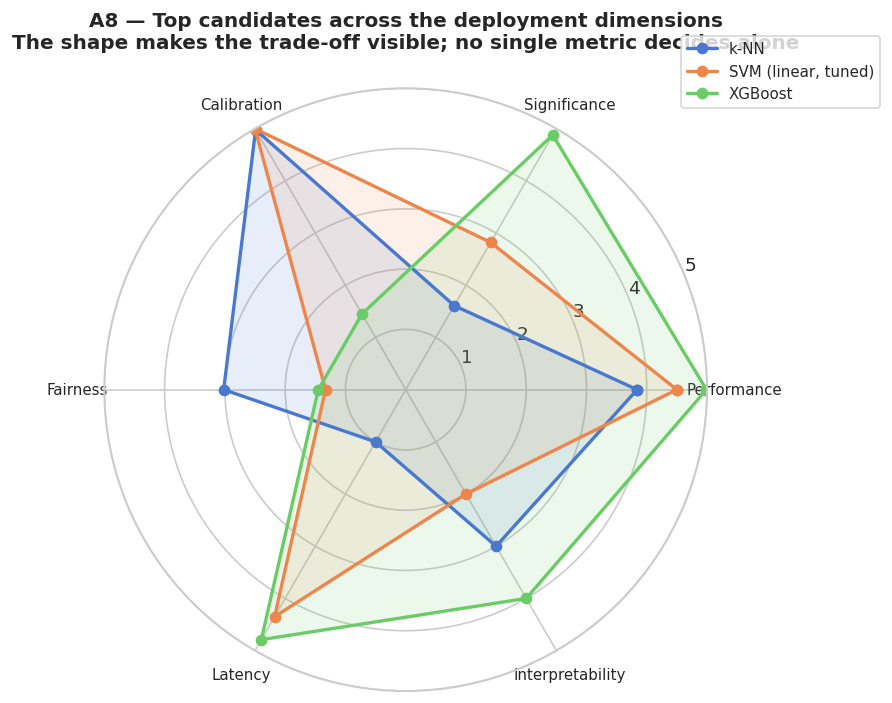

In [ ]:
# A8 Step 2b-vii: show the top deployment trade-offs as a radar chart.

top_three = score_matrix.head(3)

dimensions = [
    'Performance',
    'Significance',
    'Calibration',
    'Fairness',
    'Latency',
    'Interpretability'
]

angles = np.linspace(
    0,
    2 * np.pi,
    len(dimensions),
    endpoint=False
).tolist()

angles += angles[:1]

fig, ax = plt.subplots(
    figsize=(7.5, 7.5),
    subplot_kw=dict(polar=True)
)

for (name, row), colour in zip(
    top_three.iterrows(),
    [BLUE, ORANGE, GREEN]
):
    values = row[dimensions].tolist()
    values += values[:1]

    ax.plot(
        angles,
        values,
        'o-',
        lw=2,
        color=colour,
        label=name.replace(' (tuned)', '')
    )

    ax.fill(
        angles,
        values,
        color=colour,
        alpha=0.12
    )

ax.set_xticks(angles[:-1])
ax.set_xticklabels(dimensions, fontsize=9)
ax.set_ylim(0, 5)

ax.set_title(
    'A8 — Top candidates across the deployment dimensions\n'
    'The shape makes the trade-off visible; no single metric decides alone',
    fontweight='bold',
    pad=24
)

ax.legend(
    loc='upper right',
    bbox_to_anchor=(1.30, 1.10),
    fontsize=9
)

plt.tight_layout()
plt.savefig('/content/a8_selection_radar.png', dpi=300, bbox_inches='tight')
plt.show()


**Output explanation.** The radar chart makes the main deployment trade-offs easier to compare across the leading candidates under the scoring framework. A model that is strong in one area may still be weaker in another, which is why the final recommendation considers several measures together.

**Recommended model:** **Platt-calibrated LightGBM** using the cost-based threshold selected from out-of-fold development probabilities.

It has the best development ROC-AUC, remains slightly ahead on the held-out test set in the current run, has strong PR-AUC, and becomes well calibrated after Platt scaling. XGBoost remains a very close alternative, so the recommendation is based on the full development process rather than a large performance gap.

### A8 Step 3 — Save and reload the selected model

Save preprocessing, LightGBM, the calibrator and the operating threshold together, then reload the bundle and check that it still produces valid predictions.

In [ ]:
# A8 Step 3 — Fit, save, reload and verify the selected production bundle
# Save preprocessing, estimator and calibrator together.

import json
import joblib
from pathlib import Path

ARTIFACT_DIR = Path('/content/home_credit_model_bundle')
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

final_pipeline = clone(tuned_models[RECOMMENDED])
final_pipeline.fit(X_tr_sel, y_tr)

assert RECOMMENDED == BEST_MODEL_NAME, (
    'The saved calibrator belongs to BEST_MODEL_NAME. '
    'Re-run calibration before saving a different recommendation.'
)

model_path = ARTIFACT_DIR / 'home_credit_model.joblib'
calibrator_path = ARTIFACT_DIR / 'home_credit_calibrator.joblib'

joblib.dump(final_pipeline, model_path)
joblib.dump(final_calibrator, calibrator_path)

# Reload into fresh Python objects.
loaded_model = joblib.load(model_path)
loaded_calibrator = joblib.load(calibrator_path)

# Verify that the loaded bundle reproduces the same probabilities.
X_check = X_te_sel.iloc[:20]
raw_check = loaded_model.predict_proba(X_check)[:, 1]

if CAL_METHOD == 'Platt scaling':
    eps = 1e-6
    logits = np.log(
        np.clip(raw_check, eps, 1 - eps)
        /
        (1 - np.clip(raw_check, eps, 1 - eps))
    ).reshape(-1, 1)
    cal_check = loaded_calibrator.predict_proba(logits)[:, 1]
else:
    cal_check = loaded_calibrator.predict(raw_check)

decision_check = (cal_check >= opt_t).astype(int)

verification = pd.DataFrame({
    'raw_probability': raw_check,
    'calibrated_probability': cal_check,
    'decision_flag': decision_check
})

print('Saved model bundle to:', ARTIFACT_DIR)
print()
print('Reload verification on 10 held-out applicants:')
display(verification.round(4))

assert np.isfinite(cal_check).all()
print('Reload check PASSED: finite probabilities produced successfully.')


Saved model bundle to: /content/home_credit_model_bundle

Reload verification on 10 held-out applicants:


,raw_probability,calibrated_probability,decision_flag
0,0.4048,0.0614,0
1,0.2337,0.0287,0
2,0.7177,0.1945,1
3,0.3209,0.0436,0
4,0.4531,0.0737,0
5,0.6329,0.1411,0
6,0.1083,0.0117,0
7,0.1193,0.0131,0
8,0.8480,0.3445,1
9,0.5134,0.0918,0


Reload check PASSED: finite probabilities produced successfully.


**Output explanation.** The LightGBM pipeline, calibrator and decision threshold were saved together and then reloaded successfully. The reloaded bundle produced valid probabilities and decision flags, showing that the saved model can reproduce the scoring process after loading.

### A8 Step 4 — Create the model card and deployment conditions

Record the selected model, main evaluation results, threshold, known limits and the checks required before and after deployment.

In [ ]:
# A8 Step 4 — Build and save a compact model card

recommended_test = (
    final_df.loc[final_df['Model'] == RECOMMENDED]
    .iloc[0]
)

model_card = {
    'project': 'Home Credit Default Assessment',
    'recommended_model': RECOMMENDED,
    'calibration_method': CAL_METHOD,
    'decision_threshold': float(opt_t),
    'threshold_basis': (
        f'Out-of-fold training cost optimisation with COST_FN={COST_FN} '
        f'and COST_FP={COST_FP}'
    ),
    'development_cv_roc_auc': float(fold_scores[RECOMMENDED].mean()),
    'held_out_test_roc_auc': float(recommended_test['Test_AUC']),
    'held_out_test_pr_auc': float(recommended_test['Test_PR']),
    'held_out_calibrated_ece': float(cal_ece),
    'prediction_latency_ms_per_1000': float(
        recommended_test['Pred_ms_per_1k']
    ),
    'known_limitations': [
        'Default class is strongly imbalanced.',
        'Pairwise statistical power is limited by five outer folds.',
        'Age and education subgroup performance gaps require monitoring.',
        'The 5:1 false-negative/false-positive cost ratio is an analytical assumption.',
        'SHAP explanations describe model behaviour and are not causal effects.',
        'Performance and calibration may drift after deployment.'
    ],
    'deployment_conditions': [
        'Revalidate the business cost ratio before setting the live threshold.',
        'Monitor calibration, ROC-AUC/PR-AUC and subgroup metrics over time.',
        'Monitor input and prediction drift.',
        'Keep human review or an appeal route for consequential decisions.',
        'Version the model, preprocessing pipeline, calibrator and threshold together.',
        'Retrain or recalibrate only after a defined validation procedure.'
    ]
}

card_path = ARTIFACT_DIR / 'model_card.json'
with open(card_path, 'w', encoding='utf-8') as f:
    json.dump(model_card, f, indent=2)

print('=== MODEL CARD ===')
print(json.dumps(model_card, indent=2))
print()
print('Saved:', card_path)


=== MODEL CARD ===
{
  "project": "Home Credit Default Assessment",
  "recommended_model": "LightGBM (tuned)",
  "calibration_method": "Platt scaling",
  "decision_threshold": 0.16131578947368422,
  "threshold_basis": "Out-of-fold training cost optimisation with COST_FN=5 and COST_FP=1",
  "development_cv_roc_auc": 0.7621287034978999,
  "held_out_test_roc_auc": 0.7672655491407769,
  "held_out_test_pr_auc": 0.26031503686339086,
  "held_out_calibrated_ece": 0.0031315446995696648,
  "prediction_latency_ms_per_1000": 4.464125633239746,
  "known_limitations": [
    "Default class is strongly imbalanced.",
    "Pairwise statistical power is limited by five outer folds.",
    "Age and education subgroup performance gaps require monitoring.",
    "The 5:1 false-negative/false-positive cost ratio is an analytical assumption.",
    "SHAP explanations describe model behaviour and are not causal effects.",
    "Performance and calibration may drift after deployment."
  ],
  "deployment_conditions"

**Output explanation.** The compact model card records the chosen model, calibration method, **0.1613** threshold, development and test performance, known limits and deployment conditions. Saving this information with the model creates a clear record of how the system should be used and checked.

### A8 Step 4b — Complete the full model card

Add intended use, uses that are not supported, data details, metrics, subgroup results, limitations, ethical points and deployment conditions.

In [ ]:
# A8 Step 4b: build the full model card from results already calculated.

subgroup_card = (
    fairness_df[
        [
            'group_type',
            'group',
            'n',
            'true_rate',
            'auc',
            'sel_rate',
            'tpr',
            'fpr'
        ]
    ]
    .copy()
)

subgroup_card_records = json.loads(
    subgroup_card
    .round(4)
    .to_json(orient='records')
)

recommended_test = (
    final_df
    .loc[
        final_df['Model'] == RECOMMENDED
    ]
    .iloc[0]
)

full_model_card = {

    '1_model_details': {
        'project': 'Home Credit Default Assessment',
        'model_type': RECOMMENDED,
        'selected_source_features': len(SELECTED_FEATURES),
        'preprocessing': (
            'log1p + median imputation + standardisation for selected skewed numerics; '
            'median imputation + standardisation for other numerics; '
            'categorical imputation + one-hot encoding; all fitted inside the model pipeline'
        ),
        'calibration': CAL_METHOD,
        'decision_threshold': float(opt_t),
        'threshold_basis': (
            f'Out-of-fold training cost optimisation with '
            f'COST_FN={COST_FN} and COST_FP={COST_FP}'
        )
    },

    '2_intended_use': {
        'primary_use': (
            'Decision support for Home Credit default-risk assessment, with the score '
            'used alongside policy, affordability checks and human review.'
        ),
        'out_of_scope': [
            'Fully autonomous approval or rejection without governance or appeal.',
            'Use on populations or products that have not been separately validated.',
            'Use of the score as a causal statement about why an applicant will default.'
        ]
    },

    '3_training_and_evaluation_data': {
        'labelled_application_rows': int(len(df_tr) + len(df_te)),
        'development_rows': int(len(df_tr)),
        'held_out_test_rows': int(len(df_te)),
        'development_default_rate': float(y_tr.mean()),
        'held_out_default_rate': float(y_te.mean()),
        'relational_sources_used': [
            'bureau',
            'bureau_balance',
            'previous_application',
            'installments_payments',
            'POS_CASH_balance'
        ],
        'split_design': (
            'Stratified 80/20 development/test split. Model selection and threshold '
            'development use training/CV evidence; the held-out split is reserved for final confirmation.'
        )
    },

    '4_metrics': {
        'development_cv_roc_auc': float(fold_scores[RECOMMENDED].mean()),
        'held_out_test_roc_auc': float(recommended_test['Test_AUC']),
        'held_out_test_pr_auc': float(recommended_test['Test_PR']),
        'held_out_test_brier_raw': float(recommended_test['Test_Brier']),
        'held_out_calibrated_ece': float(cal_ece),
        'operating_threshold': float(opt_t),
        'test_recall_at_operating_threshold': float(opt_test['recall']),
        'test_precision_at_operating_threshold': float(opt_test['precision']),
        'test_approval_rate_at_operating_threshold': float(opt_test['approval']),
        'subgroup_results': subgroup_card_records
    },

    '5_ethical_considerations': [
        'Subgroup ROC-AUC and selection-rate gaps can differ; no single fairness metric proves the system is fair.',
        'Historical lending data can contain historical policy and representation effects that modelling may reproduce.',
        'Synthetic oversampling does not create new evidence and can amplify patterns already present in the minority class.',
        'SHAP explanations describe model behaviour, not causal effects on real-world default risk.',
        'Consequential decisions require review, explanation and an appeal or escalation route.'
    ],

    '6_known_limitations': [
        'The default class is strongly imbalanced.',
        'Five outer folds give low power for Bonferroni-corrected pairwise Wilcoxon tests.',
        'Age and education subgroup performance gaps require ongoing monitoring.',
        'The 5:1 false-negative:false-positive cost ratio is an analytical assumption and must be revalidated.',
        'The model is trained on historical observational outcomes and cannot by itself establish causal effects.',
        'Performance, calibration and subgroup behaviour may drift after deployment.'
    ],

    '7_deployment_conditions': [
        'Revalidate the business cost ratio and threshold before live use.',
        'Monitor ROC-AUC, PR-AUC, ECE/Brier, selection rates and subgroup gaps.',
        'Monitor input and prediction drift and define withdrawal/review triggers.',
        'Keep human review and an appeal route for consequential decisions.',
        'Version the model, preprocessing, calibrator and threshold together.',
        'Retrain or recalibrate only under a documented validation procedure.'
    ]
}

full_card_path = ARTIFACT_DIR / 'model_card_full.json'

with open(full_card_path, 'w', encoding='utf-8') as f:
    json.dump(full_model_card, f, indent=2)

print('=== FULL MODEL CARD ===')
print(json.dumps(full_model_card, indent=2))
print()
print('Saved:', full_card_path)


=== FULL ASSESSMENT MODEL CARD ===
{
  "1_model_details": {
    "project": "Home Credit Default Assessment",
    "model_type": "LightGBM (tuned)",
    "selected_source_features": 21,
    "preprocessing": "log1p + median imputation + standardisation for selected skewed numerics; median imputation + standardisation for other numerics; categorical imputation + one-hot encoding; all fitted inside the model pipeline",
    "calibration": "Platt scaling",
    "decision_threshold": 0.16131578947368422,
    "threshold_basis": "Out-of-fold training cost optimisation with COST_FN=5 and COST_FP=1"
  },
  "2_intended_use": {
    "primary_use": "Decision support for Home Credit default-risk assessment, with the score used alongside policy, affordability checks and human review.",
    "out_of_scope": [
      "Fully autonomous approval or rejection without governance or appeal.",
      "Use on populations or products that have not been separately validated.",
      "Use of the score as a causal statem

**Output explanation.** The full model card adds the intended use, data split, performance measures, subgroup results, ethical points, known limits and deployment conditions. It makes clear that the model is for decision support and should not be used as an automatic approval or rejection system without further governance and validation.

### Production-readiness reflection

The evidence supports **a controlled pilot or further validation**, not fully automatic lending decisions. Live use would require clear governance, monitoring, human review and an appeal or escalation process.

### A8 Step 5 — A limitation that better modelling cannot remove

The model learns from historical outcomes for applicants who were observed in the lending data. It cannot know what would have happened to applicants who were never financed. This limits how far the model can represent the full applicant population and cannot be solved only by using a stronger algorithm.

---
# End-to-end A1 → A8 handoff

**A1** prepares the data and features → **A2** selects features and defines preprocessing → **A3–A5** compare classical, ensemble and neural models → **A6** evaluates models, calibration, subgroups and the decision threshold → **A7** explains model behaviour → **A8** confirms, saves and documents the final system.